In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("../Data/raw/train.csv")
test = pd.read_csv("../Data/raw/test.csv")

In [3]:
print(type(train))
print(train.shape)
print(test.shape)

<class 'pandas.DataFrame'>
(891, 12)
(418, 11)


In [4]:
#Шаг 1. Смотрю на сами данные

train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
#Шаг 2. Проверяю колонки

print(train.columns.tolist())
print(test.columns.tolist())


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
#Шаг 3. Проверяю target явно

assert "Survived" in train.columns
assert "Survived" not in test.columns

In [7]:
#Шаг 4. Изучаю типы данных и пропуски

train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
#Шаг 5. Считаю пропуски явно

train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
#Шаг 6. Визуализирую % пропусков

missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})


missing.sort_values("missing_percent", ascending = False)

,missing_count,missing_percent
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


In [10]:
#Шаг 7. Проверяем дубликаты

train.duplicated().sum()

np.int64(0)

In [11]:
train["PassengerId"].duplicated().sum()

np.int64(0)

In [12]:
assert train["PassengerId"].is_unique
assert test["PassengerId"].is_unique

In [13]:
#Шаг 8. Проверяю target

train["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [14]:
train["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [15]:
assert set(train["Survived"].unique()) <= {0,1}

In [16]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [17]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [18]:
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})   


missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


In [19]:
train.duplicated().sum()

np.int64(0)

In [20]:
assert train["PassengerId"].is_unique
assert test["PassengerId"].is_unique

In [21]:
train["Survived"].value_counts(normalize=False)

Survived
0    549
1    342
Name: count, dtype: int64

In [22]:
#Шаг 9. Разбираюсь, что означает каждый признак

pd.set_option("display.max_columns", None)
train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [23]:
# Шаг 10 Смотрю числовую статистика

train.describe().T


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [24]:
# Шаг 11. Визуализирую категориальные признаки

categorical_features = ["Pclass", "Sex", "Embarked"]


for column in categorical_features:
    print(f"\n--- {column} ---")
    print(train[column].value_counts(dropna=False))


--- Pclass ---
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- Sex ---
Sex
male      577
female    314
Name: count, dtype: int64

--- Embarked ---
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


In [25]:
# Шаг 12. Смотрю связь признаков с таргетом

train.groupby("Sex")["Survived"].agg(["count", "mean"])

,count,mean
Sex,,
female,314,0.742038
male,577,0.188908


In [26]:
train.groupby("Pclass")["Survived"].agg(["count","mean"])

,count,mean
Pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


In [27]:
train.groupby("Embarked", dropna=False)["Survived"].agg(["count", "mean"])

,count,mean
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957
NaN,2,1.000000


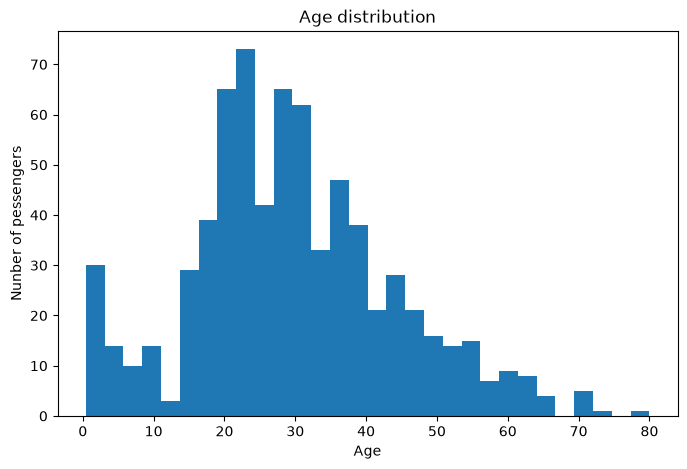

In [28]:
# Шаг 13. Делаю первые визуализации

plt.figure(figsize=(8,5))
plt.hist(train["Age"].dropna(), bins=30)


plt.xlabel("Age")
plt.ylabel("Nunber of pessengers")
plt.title("Age distribution")


plt.show()

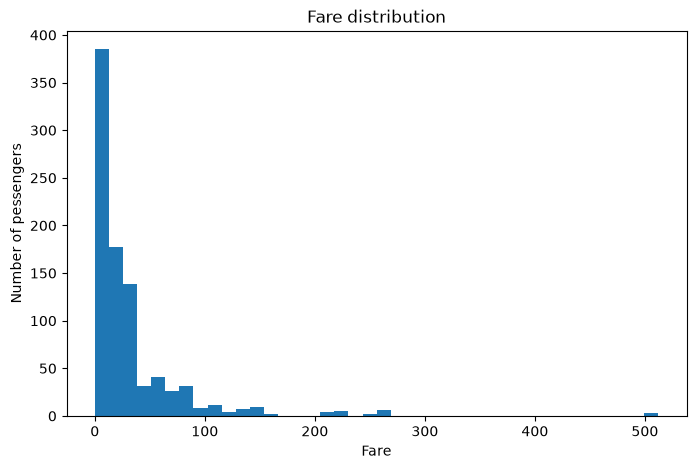

In [29]:
plt.figure(figsize=(8,5))
plt.hist(train["Fare"].dropna(), bins=40)


plt.xlabel("Fare")
plt.ylabel("Number of pessengers")
plt.title("Fare distribution") 


plt.show()

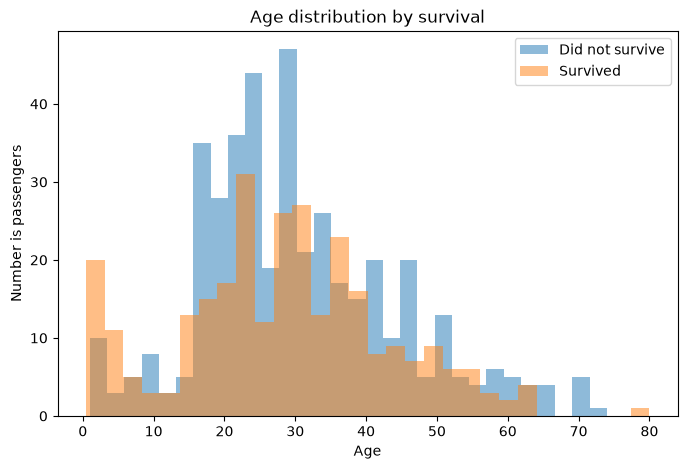

In [30]:
# Шаг 14. Смотрю на Age относительно target 

plt.figure(figsize=(8, 5))


plt.hist(
    train.loc[train["Survived"] == 0, "Age"].dropna(), #Это boolean indexing. Из train выбери строки, где Survived == 0, и из этих строк возьми колонку Age.
    bins=30,
    alpha=0.5,
    label="Did not survive"
)


plt.hist(
    train.loc[train["Survived"] == 1, "Age"].dropna(),
    bins=30,
    alpha=0.5,
    label="Survived"
)


plt.xlabel("Age")
plt.ylabel("Number is passengers")
plt.title("Age distribution by survival")
plt.legend()


plt.show()

In [31]:
## Этап 2. Basline

In [32]:
# Шаг 15 Отделяю признаки от target

X = train.drop(columns="Survived")
y = train["Survived"]

In [33]:
# Шаг 16. Первый baseline — DummyClassifier

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42 #фиксируем генератор случайных чисел
)

In [35]:
# Шаг 17. DummyClassifier Модель утанавливает нижнюю границу
# не использует признаки для принятия решения

dummy_model = DummyClassifier(
    strategy="most_frequent" #Всегда предсказывай самый распространённый класс в train.
)

In [36]:
#Шаг 18. Cross-validation baseline

dummy_scores = cross_val_score(
    dummy_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


In [37]:
# Смотрю результат

print("Fold scores:", dummy_scores)
print("Mean accuracy:", dummy_scores.mean()) #показывает среднее качество.
print("Std accuracy:", dummy_scores.std()) #показывает, насколько результат меняется между folds.

Fold scores: [0.61452514 0.61797753 0.61797753 0.61797753 0.61235955]
Mean accuracy: 0.6161634548992531
Std accuracy: 0.002324923639127706


In [38]:
#Этап 3. ML Pipeline

In [39]:
# Шаг 19. Создаю baseline на нескольких признаках


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


In [40]:
#Шаг 20. Numeric preprocessing

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [41]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), #Есть пропуски в Age, ЛинРегу не нужен НАН, прост устойчив воспроизводим, менее чувствителен к выбросам чем mean
    ("scaler", StandardScaler())
])

In [42]:
# Шаг 21. Categorical preprocessing

from sklearn.preprocessing import OneHotEncoder

In [43]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")) #делает pipeline устойчивее к новым категориям.
])

In [44]:
# Шаг 22. ColumnTransformer. Теперь объединяем две ветки.

from sklearn.compose import ColumnTransformer

In [45]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [46]:
# Шаг 23. Добавляю LogisticRegression

from sklearn.linear_model import LogisticRegression

In [47]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42)
    )
])

In [48]:
# Шаг 24. Запуск LogisticRegression

logreg_scores = cross_val_score(
    logreg_pipeline,
    X,
    y,
    cv=cv,
    scoring = "accuracy",
)


print("Fold scores:", logreg_scores)
print("Mean accuracy:", logreg_scores.mean())
print("Std accuracy:", logreg_scores.std())

Fold scores: [0.78212291 0.80337079 0.79775281 0.78089888 0.82022472]
Mean accuracy: 0.7968740192078337
Std accuracy: 0.01456733331525481


In [49]:
## Experiment tracking

In [50]:
# Шаг 25. Реализация Experiment tracking

results = []


results.append({
    "experiment": "baseline_dummy",
    "model": "DommyClassifier",
    "features": "raw",
    "cv_folds": 5,
    "cv_mean": dummy_scores.mean(),
    "cv_std": dummy_scores.std(),
    "params": "strategy=most_frequent"
})


results.append({
    "experiment": "baseline_logreg",
    "model": "LogisticRegression",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": logreg_scores.mean(),
    "cv_std": logreg_scores.std(),
    "params": "max_iter=1000"
})


results_df = pd.DataFrame(results)

results_df.sort_values(
    "cv_mean",
    ascending=False
)

,experiment,model,features,cv_folds,cv_mean,cv_std,params
1,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
0,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [51]:
## Делаю честный benchmark классических моделей на тех же basic features и тех же 5 folds.

In [52]:
# Шаг 26. KNN

from sklearn.neighbors import KNeighborsClassifier

In [53]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=5)
    )
])

In [54]:
knn_scores = cross_val_score(
    knn_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", knn_scores)
print("Mean accuracy:", knn_scores.mean())
print("Std accuracy:", knn_scores.std())


results.append({
    "experiment": "baseline_knn",
    "model": "KneighborsClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": knn_scores.mean(),
    "cv_std": knn_scores.std(),
    "params": "n_neighbors=5"
})

Fold scores: [0.79888268 0.80337079 0.78651685 0.84269663 0.80337079]
Mean accuracy: 0.8069675475488042
Std accuracy: 0.018899929014766025


In [55]:
# Шаг 27. DecisionTree

from sklearn.tree import DecisionTreeClassifier

In [56]:
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42)
    )
])
    

In [57]:
tree_scores = cross_val_score(
    tree_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", tree_scores)
print("Mean accuracy:", tree_scores.mean())
print("Std accurecy:", tree_scores.std())


results.append({
    "experiment": "baseline_tree",
    "model": "DecisionTreeClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": tree_scores.mean(),
    "cv_std": tree_scores.std(),
    "params": "default"
})

Fold scores: [0.7877095  0.82022472 0.74719101 0.76404494 0.79775281]
Mean accuracy: 0.7833845960705543
Std accurecy: 0.025559118566769734


In [58]:
# Шаг 28. RandomForest

from sklearn.ensemble import RandomForestClassifier

In [59]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1)
    )
])

In [60]:
rf_scores = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_scores)
print("Mean accuracy:", rf_scores.mean())
print("Std accuracy:", rf_scores.std())


results.append({
    "experiment": "baseline_random_forest",
    "model": "RandomForestClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": rf_scores.mean(),
    "cv_std": rf_scores.std(),
    "params":"n_estimators=300"
})

Fold scores: [0.83798883 0.79213483 0.78089888 0.82022472 0.8258427 ]
Mean accuracy: 0.8114179900822297
Std accuracy: 0.02142380221058392


In [61]:
# Шаг 29. Обновляю таблицу экспериментов

results_df = pd.DataFrame(results)

results_df.sort_values(
    "cv_mean",
    ascending=False
).reset_index(drop=True)    

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
1,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
2,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
3,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default
4,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [62]:
# Шаг 30. Добавляю еще полезную метрику (разницу относительно Dummy baseline)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df.sort_values(
    "cv_mean",
    ascending=False
).reset_index(drop=True)

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
2,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
3,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
4,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [63]:
## Feature Engineering


In [64]:
# Шаг 31. FamilySize

train["FamilySize"] = (train["SibSp"] + train["Parch"] +1)  #FamilySize = количество людей семейной группы, включая самого пассажира

In [65]:
train [["SibSp", "Parch", "FamilySize"]].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [66]:
# Шаг 32. Исследую FamilySize

train["FamilySize"].value_counts().sort_index()  #Выбираем колонку,считаем частоты, сортируем (по самому значению FamilySize)

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

In [67]:
# Шаг 33. Проверяею связь FamilySize с target

train.groupby("FamilySize")["Survived"].agg(["count", "mean"])

,count,mean
FamilySize,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


In [68]:
#Вывод: размер семьи связан с целевой переменной нелинейно.
#Пассажиры, путешествующие в одиночку, имеют более низкую долювыживших, чем пассажиры в семьях размером 2–4 человека.
#Для больших семей наблюдений существенно меньше, поэтому оценки для этих групп менее надежны.

#Гипотеза: признаки `FamilySize` и производный от него `IsAlone`могут улучшить качество модели. Эффект необходимо проверить на кросс-валидации.

In [69]:
# Шаг 34. Создаю IsAlone

train["IsAlone"] = (train["FamilySize"] ==1).astype(int)

In [70]:
train[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [71]:
# Шаг 35. Проверяю связь IsAlone с target

train.groupby("IsAlone")["Survived"].agg(["count", "mean"])

,count,mean
IsAlone,,
0,354,0.505650
1,537,0.303538


In [72]:
# Шаг 36. Ablation experiment: Family features

In [73]:
# Шаг 36.1. Создаём новый X

X_family = train.drop(columns="Survived")


print(X_family.shape)
print("FamilySize" in X_family.columns)
print("IsAlone" in X_family.columns)

(891, 13)
True
True


In [74]:
# Шаг 36.2. Обновляю список numeric features

numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]


categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [75]:
# Шаг 36.3. Создаю новый preprocessor. Не меняею старый preprocessor, потому что он относится к baseline.

preprocessor_family = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_family),
    ("cat", categorical_pipeline, categorical_features_family)
])

In [76]:
# Шаг 36.4. Создаю Random Forest

rf_family_pipeline = Pipeline ([
    ("preprocessor", preprocessor_family),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
    )
])

In [77]:
# Шаг 37. Запускаю ablation experiment

rf_family_scores = cross_val_score(
    rf_family_pipeline,
    X_family,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_family_scores)
print("Mean accuracy;", rf_family_scores.mean())
print("Std accuracy:", rf_family_scores.std())

Fold scores: [0.82681564 0.78089888 0.78089888 0.82022472 0.83707865]
Mean accuracy; 0.8091833532107213
Std accuracy: 0.02371067404450577


In [78]:
# Шаг 38. Анализирую ablation experiment

# Эксперимент показал: при текущем preprocessing, текущих параметрах Random Forest и данной 5-fold CV добавление FamilySize и IsAlone поверх basic features не улучшило средний CV score.

In [79]:
# Шаг 39. Записываю эксперимент в tracking

results.append({
    "experiment": "rf_family_features",
    "model": "RandomForestClassifier",
    "features": "basic+FAmilySize+IsAlone",
    "cv_folds": 5,
    "cv_mean": rf_family_scores.mean(),
    "cv_std": rf_family_scores.std(),
    "params": "n_estimators=300"
})

In [80]:
# Пересоздаю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
1,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300
2,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
3,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
4,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default
5,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [81]:
# Шаг 40. Добавляю сравнение именно с RF baseline

rf_baseline_mean = rf_scores.mean()


print("RF baseline:", rf_baseline_mean)
print("RF = family:", rf_family_scores.mean())
print("Difference:", rf_family_scores.mean() - rf_baseline_mean)

RF baseline: 0.8114179900822297
RF = family: 0.8091833532107213
Difference: -0.0022346368715083775


In [82]:
# Шаг 41. Feature Engineering: Name -> Title

In [83]:
train["Name"].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: str

In [84]:
train["Name"].nunique()


891

In [85]:
# Шаг 41.1. Исследую структуру Name

train[["Name"]].head(20)

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
5,"Moran, Mr. James"
6,"McCarthy, Mr. Timothy J"
7,"Palsson, Master. Gosta Leonard"
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)"
9,"Nasser, Mrs. Nicholas (Adele Achem)"


In [86]:
print("Rows:", len(train))          #Возвращает количество строк DataFrame
print("Unique names:", train["Name"].nunique())  #Считает количество уникальных значений

Rows: 891
Unique names: 891


In [87]:
# Шаг 41.2. Извлекаю Title

train["Title"] = (
    train["Name"]
    .str.extract(r",\s*([^.]*)\.", expand=False)
    .str.strip()
)

#.str.extract() извлекает из каждой строки часть, соотв-щего регуляр выражению
# , ищет запятую; \s означает whitespace — пробел, tab и тд; * ищет пробелы после запятой; ([^.]*) () создают capturing group, [^.] любой символ кроме запятой, * сколько угодно таких символов; \. означает буквальную точку
# expand=False говорит pandas вернуть Series, а не отдельный DataFrame

In [88]:
# Шаг 41.3. Проверяю извлечение

train[["Name","Title"]].head(20)

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [89]:
train["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [90]:
# Шаг 42. Объединяю редкие Title

In [91]:
# Шаг 42.1. Определяю основные категории

common_titles = [
    "Mr",
    "Miss",
    "Mrs",
    "Master"
]

In [92]:
# Шаг 42.2. Создаю TitleGrouped

train["TitleGrouped"] = (train["Title"].where(train["Title"].isin(common_titles), "Rare"))

In [93]:
# Шаг 42.3. Проверяю результат

train[["Name", "Title", "TitleGrouped"]].head(20)

train["TitleGrouped"].value_counts()

TitleGrouped
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [94]:
train["TitleGrouped"].value_counts().sum()

np.int64(891)

In [95]:
# Шаг 43. Исследую связь TitleGrouped с Survived

train.groupby("TitleGrouped")["Survived"].agg(["count", "mean"]).sort_values("mean", ascending=False)


,count,mean
TitleGrouped,,
Mrs,125,0.792000
Miss,182,0.697802
Master,40,0.575000
Rare,27,0.444444
Mr,517,0.156673


In [96]:
# Шаг 44. Анализирую TitleGrouped

#Гипотеза такая: TitleGrouped может дать модели дополнительную информацию поверх уже существующих Sex, Age, Pclass и других признаков.


In [97]:
# Шаг 45. Готовлю честный ablation experiment для TitleGrouped

In [98]:
# Шаг 45.1. Создаю отдельный X_title

numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGrouped"
]


In [99]:
# Шаг 45.2. Формирую X_title
title_features = (numeric_features_title + categorical_features_title)

X_title = train[title_features].copy()

In [100]:
# Шаг 45.3. Проверяю экспериментальный датасет

print(X_title.shape)
print(X_title.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'TitleGrouped']


In [101]:
assert "TitleGrouped" in X_title.columns
assert "FamilySize" not in X_title.columns
assert "IsAlone" not in X_title.columns
assert "Title" not in X_title.columns

In [102]:
# Шаг 45.4. Создаю preprocessing

preprocessor_title = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_title),
    ("cat", categorical_pipeline, categorical_features_title)
])


print(X_title.shape)
print(X_title.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'TitleGrouped']


In [103]:
# Шаг 46. Random Forest + TitleGrouped

rf_title_pipeline = Pipeline([
    ("preprocessor", preprocessor_title),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
        )
    )
])

In [104]:
# Шаг 47. Запускаю 5-fold CV

rf_title_scores = cross_val_score(
    rf_title_pipeline,
    X_title,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores", rf_title_scores)
print("Mean accuracy", rf_title_scores.mean())
print("Std accuracy", rf_title_scores.std())

Fold scores [0.82681564 0.79775281 0.78651685 0.80898876 0.8258427 ]
Mean accuracy 0.8091833532107213
Std accuracy 0.015702845238477328


In [105]:
# Шаг 48. Сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_title_mean = rf_title_scores.mean()


title_difference = (rf_title_mean - rf_baseline_mean)


print("RF baseline:", rf_baseline_mean)
print("RF + TitleGrouped:", rf_title_mean)
print("Difference:", title_difference)

RF baseline: 0.8114179900822297
RF + TitleGrouped: 0.8091833532107213
Difference: -0.0022346368715083775


In [106]:
# Шаг 49. Записываю эксперимент

results.append({
    "experiment": "rf_title_grouped",
    "model": "RandomForestClassifier",
    "features": "basic+TitleGrouped",
    "cv_folds": 5,
    "cv_mean": rf_title_scores.mean(),
    "cv_std": rf_title_scores.std(),
    "params": "n_estimators=300"
})

In [107]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["imrpovement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,imrpovement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
2,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
3,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
4,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
5,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
6,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [108]:
# Шаг 50. Следующая feature-гипотеза Cabin -> Deck

train["Cabin"].head(20)

0      NaN
1      C85
2      NaN
3     C123
4      NaN
5      NaN
6      E46
7      NaN
8      NaN
9      NaN
10      G6
11    C103
12     NaN
13     NaN
14     NaN
15     NaN
16     NaN
17     NaN
18     NaN
19     NaN
Name: Cabin, dtype: str

In [109]:
print("Missing Cabin:", train["Cabin"].isna().sum())
print("Missing rate:", train ["Cabin"].isna().mean())

Missing Cabin: 687
Missing rate: 0.7710437710437711


In [110]:
train["Cabin"].value_counts().head(20)

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
F2             3
D              3
C22 C26        3
C123           2
D33            2
C52            2
B28            2
C83            2
F G73          2
D26            2
B58 B60        2
C2             2
E33            2
F4             2
D36            2
Name: count, dtype: int64

In [111]:
# Шаг 51. Feature Engineering: Cabin -> Deck

In [112]:
# Шаг 51.1. Создаю Deck

train["Deck"] = (train["Cabin"].str[0].fillna("Unknown"))

In [113]:
# Шаг 51.2. Проверяю результат

train[["Cabin", "Deck"]].head(20)

,Cabin,Deck
0,NaN,Unknown
1,C85,C
2,NaN,Unknown
3,C123,C
4,NaN,Unknown
5,NaN,Unknown
6,E46,E
7,NaN,Unknown
8,NaN,Unknown
9,NaN,Unknown


In [114]:
train["Deck"].value_counts(dropna=False)

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [115]:
print("Missing Deck:", train["Deck"].isna().sum())

Missing Deck: 0


In [116]:
# Шаг 51.3. Проверяю связь Deck с target

train.groupby("Deck")["Survived"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
Deck,,
D,33,0.757576
E,32,0.750000
B,47,0.744681
F,13,0.615385
C,59,0.593220
G,4,0.500000
A,15,0.466667
Unknown,687,0.299854
T,1,0.000000


In [117]:
pd.crosstab(train["Deck"], train["Pclass"], normalize="index").round(3)

Pclass,1,2,3
Deck,,,
A,1.000,0.000,0.000
B,1.000,0.000,0.000
C,1.000,0.000,0.000
D,0.879,0.121,0.000
E,0.781,0.125,0.094
F,0.000,0.615,0.385
G,0.000,0.000,1.000
T,1.000,0.000,0.000
Unknown,0.058,0.245,0.697


In [118]:
# Шаг 52. Проверяю информативность пропуска Cabin
# Даёт ли информация «каюта известна / неизвестна» дополнительный predictive signal поверх уже имеющегося Pclass?

In [119]:
# Шаг 52.1. Создаю CabinKnown

train["CabinKnown"] = (train["Cabin"].notna().astype(int))

In [120]:
# Шаг 52.2. Проверяю результат

train[["Cabin", "Deck", "CabinKnown"]].head(20)

,Cabin,Deck,CabinKnown
0,NaN,Unknown,0
1,C85,C,1
2,NaN,Unknown,0
3,C123,C,1
4,NaN,Unknown,0
5,NaN,Unknown,0
6,E46,E,1
7,NaN,Unknown,0
8,NaN,Unknown,0
9,NaN,Unknown,0


In [121]:
train["CabinKnown"].value_counts()

CabinKnown
0    687
1    204
Name: count, dtype: int64

In [122]:
# Проперяю пропуски

print("Missing CabinKnown:", train["CabinKnown"].isna().sum())

Missing CabinKnown: 0


In [123]:
# Шаг 52.3. Проверяю связь CabinKnown с Survived

train.groupby("CabinKnown")["Survived"].agg(["count", "mean"])

,count,mean
CabinKnown,,
0,687,0.299854
1,204,0.666667


In [124]:
# Шаг 52.4. Проверяю CabinKnown внутри каждого класса

train.groupby(["Pclass", "CabinKnown"])["Survived"].agg(["count", "mean"])

count      mean
Pclass CabinKnown                 
1      0              40  0.475000
       1             176  0.664773
2      0             168  0.440476
       1              16  0.812500
3      0             479  0.235908
       1              12  0.500000

In [125]:
# Шаг 53. Тестирую CabinKnown через CV 

In [126]:
# Шаг 53.1. Создаю признаки эксперимента

numeric_features_cabin_known = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "CabinKnown"
]


categorical_features_cabin_known = [
    "Pclass",
    "Sex",
    "Embarked"
]


cabin_known_features = (numeric_features_cabin_known + categorical_features_cabin_known)

In [127]:
X_cabin_known = train[cabin_known_features].copy()

In [128]:
# Шаг 53.2. Проверяю, что в эксперимент не попали лишние признаки

print(X_cabin_known.shape)
print(X_cabin_known.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'CabinKnown', 'Pclass', 'Sex', 'Embarked']


In [129]:
# Добавляю sanity checks:

assert "CabinKnown" in X_cabin_known.columns

assert "Deck" not in X_cabin_known.columns
assert "TitleGrouped" not in X_cabin_known.columns
assert "FamilySize" not in X_cabin_known.columns
assert "IsAlone" not in X_cabin_known.columns

In [130]:
# Шаг 53.3. Создаю отдельный preprocessing

preprocessor_cabin_known = ColumnTransformer ([
    ("num", numeric_pipeline, numeric_features_cabin_known),
    ("cat", categorical_pipeline, categorical_features_cabin_known)
])


In [131]:
# Шаг 53.4. Создаю тот же Random Forest

rf_cabin_known_pipeline = Pipeline([
    ("preprocessor", preprocessor_cabin_known),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    )
    )
])

In [132]:
# Шаг 53.5. Запускаю тот же 5-fold CV

rf_cabin_known_scores = cross_val_score(
    rf_cabin_known_pipeline,
    X_cabin_known,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_cabin_known_scores)
print("Mean accuracy:", rf_cabin_known_scores.mean())
print("Std accuracy:", rf_cabin_known_scores.std())

Fold scores: [0.84357542 0.80337079 0.76966292 0.81460674 0.82022472]
Mean accuracy: 0.8102881175067477
Std accuracy: 0.02418134419893537


In [133]:
# Шаг 53.6. Сразу сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_cabin_known_mean = rf_cabin_known_scores.mean()

cabin_known_difference = (rf_cabin_known_mean - rf_baseline_mean)


print("RF baseline:", rf_baseline_mean)
print("RF + CabinKnown:", rf_cabin_known_mean)
print("Difference:", cabin_known_difference)


RF baseline: 0.8114179900822297
RF + CabinKnown: 0.8102881175067477
Difference: -0.0011298725754820271


In [134]:
# Шаг 54. Фиксирую результат CabinKnown

In [135]:
# Шаг 54.1. Интерпретирую результат
# Сравниваю поностью
# ----------------------------------------------
#                         CV mean     CV std
# RF baseline              0.811418    0.021424
# RF + CabinKnown          0.810288    0.024181
#
# Difference              -0.001130
# ----------------------------------------------
# Вывод: Добавление CabinKnown к текущему набору baseline-признаков не улучшило среднюю 5-fold CV accuracy Random Forest.

In [136]:
# Шаг 54.2. Сохраняю эксперимент в tracking

results.append({
    "experiment": "rf_cabin_known",
    "model": "RandomForestClassifier",
    "features": "basic+CabinKnown",
    "cv_folds": 5,
    "cv_mean": rf_cabin_known_scores.mean(),
    "cv_std": rf_cabin_known_scores.std(),
    "params": "n_estimators=300"
})

In [137]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
2,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
3,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
4,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
5,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
6,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
7,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [138]:
# Шаг 55. Тестирую Deck отдельно
# Теперь проверяю вторую гипотезу: Возможно, бинарного CabinKnown недостаточно, а модели полезна конкретная палуба.

In [139]:
# Шаг 55.1. Создаю набор признаков

numeric_features_deck = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_deck = [  # Deck сюда, потому что числового расстояния у признака в постановке нет
    "Pclass",
    "Sex",
    "Embarked",
    "Deck"
]

In [140]:
# Шаг 55.2. Формирую X_deck

deck_features = (numeric_features_deck + categorical_features_deck)

X_deck = train[deck_features].copy()

In [141]:
# Шаг 55.3. Проверяю состав данных

print(X_deck.shape)
print(X_deck.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Deck']


In [142]:
# Добавляю проверки

assert "Deck" in X_deck.columns

assert "CabinKnown" not in X_deck.columns
assert "TitleGrouped" not in X_deck.columns
assert "FamilySize" not in X_deck.columns
assert "IsAlone" not in X_deck.columns

In [143]:
# Шаг 55.4. Создаю preprocessing

preprocessor_deck = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_deck),
    ("cat", categorical_pipeline, categorical_features_deck)
])

In [144]:
# Шаг 55.5. Создаю Random Forest pipeline

rf_deck_pipeline = Pipeline([
    ("preprocessor", preprocessor_deck),
    ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [145]:
# Шаг 55.6. Запускаю 5-fold CV

rf_deck_scores = cross_val_score(
    rf_deck_pipeline,
    X_deck,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_deck_scores)
print("Mean accuracy:", rf_deck_scores.mean())
print("Std accuracy:", rf_deck_scores.std())

Fold scores: [0.83798883 0.76966292 0.78651685 0.79775281 0.8258427 ]
Mean accuracy: 0.8035528215429038
Std accuracy: 0.025119978756975997


In [146]:
# Шаг 55.7. Сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_deck_mean = rf_deck_scores.mean()

deck_difference = (rf_deck_mean - rf_baseline_mean)

print("RF baseline:", rf_baseline_mean)
print("RF + Deck:", rf_deck_mean)
print("Difference:", deck_difference)

RF baseline: 0.8114179900822297
RF + Deck: 0.8035528215429038
Difference: -0.00786516853932595


In [147]:
# Шаг 56. Анализирую результат Deck

In [148]:
# Шаг 56.1. Сравниваю с baseline
# ----------------------------------------------
#                         CV mean     CV std
# RF baseline              0.811418    0.021424
# RF + Deck                0.803553    0.025120
# 
# Difference              -0.007865
# ----------------------------------------------
# Переведу разницу в процентные пункты
# То есть:
# -------------------------
# Baseline RF       81.14%
# RF + Deck         80.36%
# -------------------------
# Это самое заметное снижение среди последних feature-экспериментов. При этом std тоже вырос
# 
# По текущему CV Deck не даёт оснований заменять baseline.

In [149]:
# Шаг 56.2. Интерпретирую результат
# Вывод: Deck связан с Survived в EDA, но при добавлении к текущему baseline-набору признаков средняя 5-fold CV accuracy Random Forest снизилась с 0.8114 до 0.8036

In [150]:
# Шаг 56.3. Сохраняю эксперимент

results.append({
    "experiment": "rf_deck",
    "model": "RandomForestClassifier",
    "features": "basic+Deck",
    "cv_folds": 5,
    "cv_mean": rf_deck_scores.mean(),
    "cv_std": rf_deck_scores.std(),
    "params": "n_estimators=300"
})

In [151]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
2,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
3,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
4,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
5,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300,0.187389
6,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
7,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
8,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [152]:
# Шаг 57. Подвожу промежуточный итог Feature Engineering

# Прежде чем генерировать следующие признаки, я останавливаюсь и сравниваю уже проведённые эксперименты:
# ----------------------------------------------------------
# Experiment                  CV mean      Δ vs RF baseline
# 
# RF baseline                 0.811418          —
# + CabinKnown                0.810288      -0.001130
# + FamilySize + IsAlone      0.809183      -0.002235
# + TitleGrouped              0.809183      -0.002235
# + Deck                      0.803553      -0.007865
# ----------------------------------------------------------
# Лучший RF остаётся: basic Random Forest → 0.811418

In [153]:
# Шаг 58. Исследую Ticket

In [154]:
# Шаг 58.1. Смотрю примеры Ticket

train[["Ticket", "Survived"]].head(20)

,Ticket,Survived
0,A/5 21171,0
1,PC 17599,1
2,STON/O2. 3101282,1
3,113803,1
4,373450,0
5,330877,0
6,17463,0
7,349909,0
8,347742,1
9,237736,1


In [155]:
# Шаг 58.2. Проверяю cardinality

print("Rows:", len(train))
print("Unique tickets:", train["Ticket"].nunique())
print("Ticket uniqueness ratio:", train["Ticket"].nunique() / len(train))

Rows: 891
Unique tickets: 681
Ticket uniqueness ratio: 0.7643097643097643


In [156]:
# Шаг 58.3. Проверяю, сколько пассажиров приходится на билет

ticket_counts = (train["Ticket"].value_counts())
ticket_counts.head(20)

Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
19950           4
W./C. 6608      4
4133            4
LINE            4
113781          4
17421           4
PC 17757        4
113760          4
2666            4
347742          3
Name: count, dtype: int64

In [157]:
# Шаг 58.4. Создаю гипотезу TicketGroupSize

ticket_counts.value_counts().sort_index()

count
1    547
2     94
3     21
4     11
5      2
6      3
7      3
Name: count, dtype: int64

In [158]:
# Шаг 59. Создаю TicketGroupSize

In [159]:
# Шаг 59.1. Создаю размер группы по билету

train["TicketGroupSize"] = (train["Ticket"].map(train["Ticket"].value_counts()))

In [160]:
# Шаг 59.2. Проверяю результат

train[["Ticket", "TicketGroupSize"]].head(20)

,Ticket,TicketGroupSize
0,A/5 21171,1
1,PC 17599,1
2,STON/O2. 3101282,1
3,113803,2
4,373450,1
5,330877,1
6,17463,1
7,349909,4
8,347742,3
9,237736,2


In [161]:
train["TicketGroupSize"].value_counts().sort_index()

TicketGroupSize
1    547
2    188
3     63
4     44
5     10
6     18
7     21
Name: count, dtype: int64

In [162]:
# Шаг 59.3. Проверяю корректность признака

print("Missing:", train["TicketGroupSize"].isna().sum())
print("Min:", train["TicketGroupSize"].min())
print("Max:", train["TicketGroupSize"].max())

Missing: 0
Min: 1
Max: 7


In [163]:
# Шаг 60. Проверяю связь TicketGroupSize с Survived

In [164]:
# Шаг 60.1. Считаю survival rate

train.groupby("TicketGroupSize")["Survived"].agg(["count", "mean"])

,count,mean
TicketGroupSize,,
1,547,0.297989
2,188,0.574468
3,63,0.698413
4,44,0.500000
5,10,0.000000
6,18,0.000000
7,21,0.238095


In [165]:
# Здесь проверяю гипотезу: Связано ли путешествие одному или в группе с вероятностью выживания?

In [166]:
# Шаг 60.2. Сравниваю TicketGroupSize и FamilySize

train [[
    "Ticket",
    "SibSp",
    "Parch",
    "FamilySize",
    "TicketGroupSize"
]].head(30)

,Ticket,SibSp,Parch,FamilySize,TicketGroupSize
0,A/5 21171,1,0,2,1
1,PC 17599,1,0,2,1
2,STON/O2. 3101282,0,0,1,1
3,113803,1,0,2,2
4,373450,0,0,1,1
5,330877,0,0,1,1
6,17463,0,0,1,1
7,349909,3,1,5,4
8,347742,0,2,3,3
9,237736,1,0,2,2


In [167]:
# Cчитаю корреляцию

train[[
    "FamilySize",
    "TicketGroupSize"
]].corr()

,FamilySize,TicketGroupSize
FamilySize,1.000000,0.748487
TicketGroupSize,0.748487,1.000000


In [168]:
# Шаг 61. Проверяю TicketGroupSize на data leakage

In [169]:
# Шаг 61.1. Разбираюсь, где потенциальная проблема
# Информация о наличии Passenger C из validation уже повлияла на feature в training (cross-validation leakage)
# Важно: это не target leakage — Survived мы не использовали. Но граница train/validation всё равно нарушена. 

In [170]:
# Шаг 61.2. Определяю правильную архитектуру
# 
# Мне нужна такая структура:
#
# FIT
# │
# ├── получаю training data
# ├── считаю Ticket frequencies
# └── сохраняю mapping
#        ↓
# TRANSFORM
# │
# ├── получаю новые данные
# ├── использую сохранённый mapping
# └── НЕ пересчитываю статистику
#
# Вывод: нужно сипользовать sklearn.Pipeline

In [171]:
# Шаг 62. Создаю sklearn-transformer для TicketGroupSize

In [172]:
# Шаг 62.1. Импортирую базовые классы sklearn

from sklearn.base import BaseEstimator, TransformerMixin

In [173]:
# BaseEstimator даёт нашему классу стандартное поведение sklearn estimator. Это важно для совместимости с Pipeline, cloning и работы с параметрами.
# TransformerMixin предоставляет стандартную transformer-семантику sklearn, в частности fit_transform() на основе реализованных нами fit() и transform().

In [174]:
# Шаг 62.2. Создаю класс

class TicketGroupSizeTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.ticket_counts_ = (X["Ticket"].value_counts())

        return self

    
    def transform(self,X):
        X = X.copy()
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1).astype(int))

        return X

In [175]:
# Шаг 63. Проверяю transformer вручную

In [176]:
#Шаг 63.1. Создаю маленький искусственный train

ticket_train_example = pd.DataFrame({
    "Ticket": [
        "AAA",
        "AAA",
        "BBB",
        "CCC",
        "CCC",
        "CCC"
    ]
})
                                     

In [177]:
# Шаг 63.2. Создаю искусственный validation

ticket_valid_example = pd.DataFrame ({
    "Ticket": [
        "AAA",
        "BBB",
        "DDD"
    ]
})

In [178]:
# Шаг 63.3. Обучаю transformer только на train

ticket_transformer = TicketGroupSizeTransformer()
ticket_transformer.fit(ticket_train_example)

Name,Type,Value
ticket_counts_,"Series[int64](3,)","Ticket CCC ..., dtype: int64"


In [179]:
ticket_transformer.ticket_counts_

Ticket
CCC    3
AAA    2
BBB    1
Name: count, dtype: int64

In [180]:
ticket_train_example

,Ticket
0,AAA
1,AAA
2,BBB
3,CCC
4,CCC
5,CCC


In [181]:
ticket_transformer = TicketGroupSizeTransformer()

ticket_transformer.fit(ticket_train_example)

ticket_transformer.ticket_counts_

Ticket
CCC    3
AAA    2
BBB    1
Name: count, dtype: int64

In [182]:
# Шаг 63.4. Преобразую validation

ticket_transformer.transform(ticket_valid_example)

,Ticket,TicketGroupSize
0,AAA,2
1,BBB,1
2,DDD,1


In [183]:
# Шаг 64. Встраиваю TicketGroupSizeTransformer в ML pipeline

In [184]:
# Шаг 64.1. Создаю исходный набор признаков

ticket_input_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket"
]

X_ticket = train[ticket_input_features].copy()

In [185]:
# Шаг 64.2. Проверяю входные данные

print(X_ticket.shape)
print(X_ticket.columns.tolist)

(891, 8)
<bound method IndexOpsMixin.tolist of Index(['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket'], dtype='str')>


In [186]:
assert "Ticket" in X_ticket.columns
assert "TicketGroupSize" not in X_ticket.columns

In [187]:
# Шаг 64.3. Определяю признаки после transformer

numeric_features_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

In [188]:
categorical_features_ticket = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [189]:
# Шаг 64.4. Создаю preprocessing

preprocessor_ticket = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_ticket),
    ("cat", categorical_pipeline, categorical_features_ticket)
])

In [190]:
# Шаг 64.5. Собираю полный pipeline

rf_ticket_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", preprocessor_ticket),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=43,
        n_jobs=-1
        )
    )
])

In [191]:
# Шаг 64.6. Разбираю, что произойдёт внутри CV

cross_val_score(
    rf_ticket_pipeline,
    X_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)

array([0.83798883, 0.79213483, 0.79775281, 0.79775281, 0.85393258])

In [192]:
# Шаг 64.7. Проверяю pipeline до CV

rf_ticket_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [193]:
# Шаг 65. Запускаю leakage-safe CV для TicketGroupSize

In [194]:
# Шаг 65.1. Запускаю 5-fold cross-validation

rf_ticket_scores = cross_val_score(
    rf_ticket_pipeline,
    X_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_ticket_scores)
print("Mean accuracy:", rf_ticket_scores.mean())
print("Std accuracy:", rf_ticket_scores.std())

Fold scores: [0.83798883 0.79213483 0.79775281 0.79775281 0.85393258]
Mean accuracy: 0.8159123721047015
Std accuracy: 0.025130926325444957


In [195]:
# Шаг 65.2. Сравниваю результат с baseline

rf_baseline_mean = rf_scores.mean()
rf_ticket_mean = rf_ticket_scores.mean()

ticket_difference = (rf_ticket_mean - rf_baseline_mean)

print("RF baseline:", rf_baseline_mean)
print("RF + TicketGroupSize:", rf_ticket_mean)
print("Difference:", ticket_difference)

RF baseline: 0.8114179900822297
RF + TicketGroupSize: 0.8159123721047015
Difference: 0.004494382022471766


In [196]:
# Шаг 66. Интерпретирую TicketGroupSize

In [197]:
# Шаг 66.1. Сравниваю результаты
# Вывод:
# Leakage-safe TicketGroupSize улучшил среднюю 5-fold CV accuracy Random Forest с 0.8114 до 0.8159. 
# Прирост составляет +0.0045, но он небольшой относительно межфолдового разброса, поэтому признак рассматриваю как перспективный и продолжаю проверять в следующих экспериментах.


In [198]:
# Шаг 66.2. Смотрю на отдельные folds
# Результаты между folds заметно различаются:
# min ≈ 0.792
# max ≈ 0.854

In [199]:
# Шаг 67. Фиксирую эксперимент

In [200]:
# Шаг 67.1. Добавляю результат в experiment tracking

results.append({
    "experiment": "rf_ticket_group_size",
    "model": "RandomForestClassifier",
    "features": "basic+TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_ticket_scores.mean(),
    "cv_std": rf_ticket_scores.std(),
    "params": "n_estimators=300"
})

In [201]:
# Шаг 67.2. Пересобираю таблицу результатов

results_df = pd.DataFrame(results)

dimmy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300,0.199749
1,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
2,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
3,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
4,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
5,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
6,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300,0.187389
7,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
8,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
9,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [202]:
# Шаг 68. Сравниваю все engineered features
#
# По  результатам:
# ----------------------------------------------------------
# Эксперимент	              CV accuracy    Δ к RF baseline
# RF + TicketGroupSize	       0.815912	       +0.004494
# RF baseline	               0.811418	         —
# RF + CabinKnown	           0.810288	       −0.001130
# RF + FamilySize + IsAlone	   0.809183	       −0.002235
# RF + TitleGrouped	           0.809183	       −0.002235
# RF + Deck	                   0.803553	       −0.0078653

In [203]:
# Шаг 69. Проверяю комбинацию лучших признаков
# Самая интересная пара: FamilySize + TicketGroupSize

In [204]:
# Шаг 70. Создаю единый FeatureEngineeringTransformer

In [205]:
# Шаг 70.1. Создаю новый transformer

class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.ticket_counts_ = (X["Ticket"].value_counts())

        return self


    def transform(self, X):
        X = X.copy()
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1).astype(int))

        return X

In [206]:
# Шаг 71. Проверяю новый transformer отдельно

In [207]:
# Шаг 71.1. Создаю небольшой пример

feature_train_example = pd.DataFrame({
    "SibSp": [1,0,2,0],
    "Parch": [2,0,1,0],
    "Ticket": [
        "AAA",
        "AAA",
        "BBB",
        "CCC"
    ]
})

In [208]:
# Шаг 71.2. Создаю transformer

feature_transformer = (FeatureEngineeringTransformer())

In [209]:
# Шаг 71.3. Обучаю его

feature_transformer.fit(feature_train_example)

Name,Type,Value
ticket_counts_,"Series[int64](3,)","Ticket AAA ..., dtype: int64"


In [210]:
# Шаг 71.4. Преобразую данные

feature_train_transformed = (feature_transformer.transform(feature_train_example))

feature_train_transformed

,SibSp,Parch,Ticket,FamilySize,TicketGroupSize
0,1,2,AAA,4,2
1,0,0,AAA,1,2
2,2,1,BBB,4,1
3,0,0,CCC,1,1


In [211]:
# Шаг 71.5. Добавляю автоматические sanity checks

assert (feature_train_transformed.loc[0, "FamilySize"] == 4)
assert (feature_train_transformed.loc[0, "TicketGroupSize"] == 2)
assert (feature_train_transformed.loc[2, "FamilySize"] == 4)
assert (feature_train_transformed.loc[2, "TicketGroupSize"] == 1)

In [212]:
# Шаг 72. Собираю эксперимент FamilySize + TicketGroupSize

In [213]:
# Шаг 72.1. Формирую raw input

family_ticket_input_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket"
]

X_family_ticket = train[family_ticket_input_features].copy()

In [214]:
assert "FamilySize" not in X_family_ticket.columns
assert "TicketGroupSize" not in X_family_ticket.columns

In [215]:
# Шаг 72.2 Определяю features

numeric_features_family_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "TicketGroupSize"
]


categorical_features_family_ticket = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [216]:
# Шаг 72.3. Создаю preprocessing

preprocessor_family_ticket = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_family_ticket),
    ("cat", categorical_pipeline, categorical_features_family_ticket)
])

In [217]:
# Шаг 72.4. Собираю полный pipeline

rf_family_ticket_pipeline = Pipeline([
    ("feature_engineering", FeatureEngineeringTransformer()),
    ("preprocessor", preprocessor_family_ticket),
    ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [ ]:
# Шаг 72.5. Проверяю структуру

rf_family_ticket_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

In [ ]:
# Шаг 73. Тестирую FamilySize + TicketGroupSize на 5-fold CV

In [ ]:
# Шаг 73.1. Запускаю cross-validation

rf_family_ticket_scores = cross_val_score(
    rf_family_ticket_pipeline,
    X_family_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_family_ticket_scores)
print("Mean accuracy:",  rf_family_ticket_scores.mean())
print("Std accuracy:",  rf_family_ticket_scores.std())

In [ ]:
# Шаг 73.2. Сравниваю сразу три эксперимента

print("RF baseline:", rf_scores.mean())
print("RF + TicketGroupSize:", rf_ticket_scores.mean())
print("RF + FamilySize + TicketGroupSize:", rf_family_ticket_scores.mean())

In [ ]:
#Cчитаю две разные дельты:

difference_vs_baseline = (rf_family_ticket_scores.mean() - rf_scores.mean()) #Лучше ли FamilySize + TicketGroupSize, чем модель вообще без этих engineered features?

difference_vs_ticket = (rf_family_ticket_scores.mean() - rf_ticket_scores.mean()) #Добавляет ли FamilySize новую полезную информацию поверх TicketGroupSize? 

print("Difference vs baseline:", difference_vs_baseline,)
print("Difference vs TicketGroupSize:", difference_vs_ticket)

In [ ]:
# Шаг 73.3. Сравниваю результаты fold-to-fold

fold_comparison = pd.DataFrame({
    "baseline": rf_scores,
    "ticket": rf_ticket_scores,
    "family_ticket": rf_family_ticket_scores
})

fold_comparison

In [ ]:
#Ищу скрытую нестабильность в среднем

fold_comparison["delta_vs_baseline"] = (fold_comparison["family_ticket"] - fold_comparison["baseline"])

fold_comparison["delta_vs_ticket"] = (fold_comparison["family_ticket"] - fold_comparison["ticket"])

fold_comparison

In [ ]:
# Шаг 73.4. Считаю количество выигранных folds

wins_vs_ticket = (fold_comparison["delta_vs_ticket"] > 0).sum()

ties_vs_ticket = (fold_comparison["delta_vs_ticket"] == 0).sum()

losses_vs_ticket = (fold_comparison["delta_vs_ticket"] < 0).sum()


print("Wins vs TicketGroupSize:", wins_vs_ticket)
print("Ties vs TicketGroupSize:", ties_vs_ticket)
print("Losses vs TicketGroupSize:", losses_vs_ticket)

In [ ]:
# Шаг 74. Интерпретирую эксперимент FamilySize + TicketGroupSize
# Вывод: для текущего Random Forest, текущего preprocessing и текущей CV-схемы FamilySize не даёт дополнительного качества поверх TicketGroupSize.

In [ ]:
# Шаг 74.1. Оставляю TicketGroupSize текущим кандидатом

In [ ]:
# Шаг 74.1. Оставляю TicketGroupSize текущим кандидатом

results.append({
    "experiment": "rf_family_ticket",
    "model": "RandomForestClassifier",
    "features": "basic+FamilySize+TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_family_ticket_scores.mean(),
    "cv_std": rf_family_ticket_scores.std(),
    "params": "n_estimators=300"
})

In [ ]:
# Шаг 74.3. Обновляю таблицу экспериментов

results_df = pd.DataFrame(results)

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_scores.mean())

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

In [ ]:
# Шаг 75. Перехожу от feature engineering к подбору Random Forest
# Я до сих пор использую практически произвольный RandomForestClassifier(n_estimators=300). А насколько хорошо вообще настроена сама модель?

In [ ]:
# Шаг 75.1. Определяю параметры, которые буду оптимизировать
# Шаг 75.2. Определяю способ подора гиперпараметров  

In [ ]:
# Шаг 75.3. Импортирую RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV

In [ ]:
# Шаг 76. Создаю пространство гиперпараметров Random Forest

In [ ]:
# Шаг 76.1. Смотрю параметры текущей модели

rf_ticket_pipeline.get_params()["model"]

In [ ]:
rf_ticket_pipeline.get_params()["model"].get_params()

In [ ]:
# Шаг 76.2. Создаю пространство поиска

rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 500, 800],
    "model__max_depth": [None, 3, 5, 7, 10, 15],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced"]
}

In [ ]:
# Шаг 76.3. Проверяю размер полного пространства

from math import prod

n_combinations = prod(len(values) for values in rf_param_distributions.values())

print("Total combinations:", n_combinations)

In [ ]:
# Шаг 77. Создаю RandomizedSearchCV

rf_random_search = RandomizedSearchCV(
    estimator=rf_ticket_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=50,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [ ]:
rf_random_search

In [ ]:
# Шаг 78. Запускаю подбор гиперпараметров

In [ ]:
# Шаг 78.1. Запускаю .fit()

rf_random_search.fit(X_ticket, y)

In [ ]:
# Шаг 78.2. Смотрю лучший CV score

print("Best CV accuracy:", rf_random_search.best_score_)

In [ ]:
# Шаг 78.3. Смотрю лучшие гиперпараметры

rf_random_search.best_params_

In [ ]:
# Шаг 78.4. Смотрю train score лучшей конфигурации

best_index = rf_random_search.best_index_

In [ ]:
best_train_score = (rf_random_search.cv_results_["mean_train_score"][best_index])
best_valid_score = (rf_random_search.cv_results_["mean_test_score"][best_index])

print("Train accuracy:", best_train_score)
print("Validation accuracy:", best_valid_score)
print("Train-validation gap:", best_train_score - best_valid_score)

In [ ]:
# Шаг 78.5. Сравниваю tuned RF с исходным RF

baseline_rf_mean = rf_scores.mean()
ticket_rf_mean = rf_ticket_scores.mean()
tuned_rf_mean = rf_random_search.best_score_


print("RF baseline:", baseline_rf_mean)
print("RF + TicketGroupSize:", ticket_rf_mean)
print("Tuned RF + TicketGroupSize:", tuned_rf_mean)

print("Improvement tuning vs TicketGroupSize:", tuned_rf_mean - ticket_rf_mean)

print("Total improvement vs baseline:", tuned_rf_mean - baseline_rf_mean)

In [ ]:
# Вывод: 
# Tuned Random Forest сохраняет заметный train-validation gap, но демонстрирует существенно более высокую CV accuracy.
# => регуляризация улучшила generalization, хотя признаки переобучения не исчезли.

In [ ]:
# Шаг 80. Проверяю устойчивость результата

best_index = rf_random_search.best_index_

best_fold_scores = [rf_random_search.cv_results_[f"split{i}_test_score"][best_index] for i in range(5)]

print("Best model fold scores:", best_fold_scores)
print("Mean:", np.mean(best_fold_scores))
print("Std:", np.std(best_fold_scores))

In [ ]:
# Шаг 81. Фиксирую tuned Random Forest как отдельный эксперимент

In [ ]:
# Шаг 81.1. Добавляю эксперимент

results.append({
    "experiment": "rf_ticket_tuned",
    "model": "RandomForestClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_random_search.best_score_,
    "cv_std": np.std(best_fold_scores),
    "params": rf_random_search.best_params_
})

In [ ]:
# Шаг 81.2. Обновляю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

In [ ]:
# Шаг 81.3. Проверяю, нет ли случайного дубликата

results_df[results_df["experiment"] == "rf_ticket_tuned"]

In [ ]:
# Шаг 82. Получаю лучшую модель из RandomizedSearchCV

best_rf_pipeline = rf_random_search.best_estimator_
best_rf_pipeline

In [ ]:
# Шаг 82.1. Проверяю параметры модели

best_rf_pipeline.named_steps["model"]

In [ ]:
best_rf_pipeline.named_steps["model"].get_params()

In [ ]:
# Шаг 83. Начинаю работу с градиентным бустингом

In [ ]:
import catboost

print(catboost.__version__)

In [ ]:
import sys

print(sys.executable)

In [ ]:
import sys

!{sys.executable} -m pip install catboost

In [ ]:
import catboost

print("CatBoost version:", catboost.__version__)


In [ ]:
# Шаг 84. Подготавливаю данные для CatBoost

In [ ]:
from catboost import CatBoostClassifier

In [ ]:
print(X_ticket.columns.tolist())

In [ ]:
X_ticket.head()

In [ ]:
X_ticket.dtypes

In [ ]:
X_ticket.isna().sum().sort_values(ascending=False)

In [ ]:
# Шаг 85. Готовлю preprocessing для CatBoost

In [ ]:
# Шаг 85.1. Определяю признаки

numeric_features_catboost = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "TicketGroupSize"
]

categorical_features_catboost = [
    "Sex",
    "Embarked"
]

In [ ]:
# Шаг 85.2. Создаю transformer для подготовки DataFrame

from sklearn.base import BaseEstimator, TransformerMixin

In [ ]:
class CatBoostPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self, numeric_features, categorical_features):
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X = X[self.numeric_features + self.categorical_features]

        X[self.categorical_features] = (X[self.categorical_features].fillna("Missing").astype(str))

        return X

In [ ]:
# Шаг 85.3. Создаю preprocessor

catboost_preprocessor = CatBoostPreprocessor(
    numeric_features=numeric_features_catboost,
    categorical_features=categorical_features_catboost
)

In [ ]:
# Шаг 85.4. Проверяю его отдельно до Pipeline

X_catboost_test = X_ticket.head(10).copy()

In [ ]:
ticket_test_transformer = TicketGroupSizeTransformer()

X_catboost_test = ticket_test_transformer.fit_transform(X_catboost_test)

In [ ]:
X_catboost_test.columns.tolist()

In [ ]:
X_catboost_test = catboost_preprocessor.fit_transform(X_catboost_test)
X_catboost_test

In [ ]:
# Шаг 85.5. Проверяю итоговую схему

print(X_catboost_test.dtypes)
print()
print(X_catboost_test.isna().sum())

In [ ]:
# Шаг 86. Собираю baseline CatBoost

In [ ]:
# Шаг 86.1. Создаю CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="Accuracy",
    cat_features=catboost_cat_features,
    random_seed=42,
    verbose=False,
    thread_count=1
)

In [ ]:
# Шаг 86.2. Собираю полный Pipeline

catboost_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", CatBoostPreprocessor(numeric_features=numeric_features_catboost, categorical_features=categorical_features_catboost)),
    ("model", catboost_model)
])

In [ ]:
# Шаг 86.3. Проверяю Pipeline до обучения

catboost_pipeline

In [ ]:
# Шаг 86.4. Запускаю 5-fold CV

from sklearn.model_selection import cross_validate

In [ ]:
catboost_cv_results = cross_validate(
    estimator=catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

In [ ]:
# Шаг 86.5. Достаю результаты

catboost_train_scores = catboost_cv_results["train_score"]
catboost_valid_scores = catboost_cv_results["test_score"]

print("Train fold scores:", catboost_train_scores)
print("Validation fold scores:", catboost_valid_scores)

print()
print("Mean train accuracy:", catboost_train_scores.mean())
print("Mean validation accuracy:", catboost_valid_scores.mean())
print("Validation std:", catboost_valid_scores.std())

print("Train-validation gap:", catboost_train_scores.mean() - catboost_valid_scores.mean())

In [ ]:
# Шаг 86.6. Сравниваю с tuned Random Forest

print("Tuned Random Forest:", rf_random_search.best_score_)
print("CatBoost baseline:", catboost_valid_scores.mean())
print("Difference:", catboost_valid_scores.mean() - rf_random_search.best_score_)

In [ ]:
# Шаг 87. Фиксирую CatBoost baseline в experiment tracking

results.append({
    "experiment": "catboost_initial",
    "model": "CatBoostClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": catboost_valid_scores.mean(),
    "cv_std": catboost_valid_scores.std(),
    "params": "iterations=500, learning_rate=0.05, depth=6"
})

In [ ]:
# Шаг 87.1. Проверяю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

In [ ]:
# Шаг 88. Начинаю tuning CatBoost

In [ ]:
# Шаг 88.1. Определяю параметры для поиска

catboost_param_distributions = {
    "model__iterations": [200, 300, 500, 700, 1000],
    "model__depth": [4, 5, 6, 7, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__l2_leaf_reg": [1, 3, 5, 7, 10],
    "model__random_strength": [0.5, 1, 2, 5],
}

In [ ]:
# Шаг 88.2. Проверяю, что Pipeline видит эти параметры

pipeline_params = catboost_pipeline.get_params()

for param in catboost_param_distributions:
    print(param, "->", param in pipeline_params)

In [ ]:
# Шаг 88.3. Добавляю тюнимые параметры в CatBoost

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    random_strength=1,
    loss_function="Logloss",
    eval_metric="Accuracy",
    cat_features=catboost_cat_features,
    random_seed=42,
    verbose=False,
    thread_count=1
)

In [ ]:
# Шаг 88.4. Пересобираю Pipeline

catboost_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", CatBoostPreprocessor(numeric_features=numeric_features_catboost, categorical_features=categorical_features_catboost)),
    ("model", catboost_model)
])

In [ ]:
pipeline_params = catboost_pipeline.get_params()

for param in catboost_param_distributions:
    print(param, "->", param in pipeline_params)

In [ ]:
# Шаг 88.5. Считаю стоимость поиска

n_iter = 40
n_folds = 5

total_fits = n_iter * n_folds

print("Random configurations:", n_iter)
print("CV folds:", n_folds)
print("Total model fits:", total_fits)

In [ ]:
# Шаг 88.7. Создаю RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV

In [ ]:
catboost_random_search = RandomizedSearchCV(
    estimator=catboost_pipeline,
    param_distributions=catboost_param_distributions,
    n_iter=40,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

In [ ]:
catboost_random_search

In [ ]:
# Шаг 88.8. Запускаю tuning CatBoost

catboost_random_search.fit(X_ticket, y)

In [ ]:
# Шаг 88.9 Проверяю лучший CV score

print("Best CV accuracy:", catboost_random_search.best_score_)

In [ ]:
# Шаг 88.10. Смотрю лучшие гиперпараметры

catboost_random_search.best_params_

In [ ]:
# Шаг 88.11. Достаю лучшую модель

best_catboost_pipeline = catboost_random_search.best_estimator_
best_catboost_pipeline

In [ ]:
# Шаг 88.12. Смотрю train-validation gap лучшей конфигурации

best_index = catboost_random_search.best_index_

best_catboost_train_score = (catboost_random_search.cv_results_["mean_train_score"][best_index])
best_catboost_valid_score = (catboost_random_search.cv_results_["mean_test_score"][best_index])
best_catboost_gap = (best_catboost_train_score - best_catboost_valid_score)


print("Best train accuracy:", best_catboost_train_score)
print("Best validation accuracy:", best_catboost_valid_score)
print("Train-validation gap:", best_catboost_gap)

In [ ]:
# Шаг 89. Анализирую tuned CatBoost по folds

In [ ]:
# Шаг 89.1. Достаю validation scores лучшей конфигурации

best_index = catboost_random_search.best_index_
best_catboost_fold_scores = [catboost_random_search.cv_results_[f"split{i}_test_score"][best_index] for i in range(5)]

print("Best CatBoost fold scores:", best_catboost_fold_scores)

In [ ]:
# Шаг 89.2. Считаю mean и std

best_catboost_fold_scores = np.array(best_catboost_fold_scores)

print("Mean:", best_catboost_fold_scores.mean())

print("Std:", best_catboost_fold_scores.std())

In [ ]:
# Шаг 89.3. Сравниваю tuned RF и tuned CatBoost (лучшие модели)

rf_mean = rf_random_search.best_score_
rf_best_index = rf_random_search.best_index_
rf_std = rf_random_search.cv_results_["std_test_score"][rf_best_index]

catboost_mean = best_catboost_fold_scores.mean()
catboost_std = best_catboost_fold_scores.std()


print("Tuned Random Forest:", rf_mean, "+/-", rf_std)
print("Tuned CatBoost:", catboost_mean, "+/-", catboost_std)
print()
print("Difference:", catboost_mean - rf_mean)

In [ ]:
# Шаг 90. Фиксирую tuned CatBoost в experiment tracking

results.append({
    "experiment": "catboost_tuned",
    "model": "CatBoostClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": catboost_random_search.best_score_,
    "cv_std": catboost_std,
    "params": catboost_random_search.best_params_
})


In [ ]:
# Шаг 90.1. Обновляю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

In [ ]:
#Шаг 91. Перехожу от одной accuracy к качеству классификации

In [ ]:
# Шаг 91.1. Импортирую инструмент для OOF-предсказаний

from sklearn.model_selection import cross_val_predict

In [ ]:
# Шаг 91.2. Получаю лучшую конфигурацию Random Forest

best_rf_pipeline = rf_random_search.best_estimator_

best_rf_pipeline

In [ ]:
# Шаг 91.3. Получаю OOF-предсказания Random Forest

rf_oof_pred = cross_val_predict(  # cross_val_predict - что модель предсказала для каждого конкретного объекта, когда этот объект находился вне train fold?
    estimator=best_rf_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict",
    n_jobs=-1
)

In [ ]:
# Шаг 91.4. Проверяю OOF-предсказания Random Forest

print("Number of predictions:", len(rf_oof_pred))
print("Number of targets:", len(y))

print()
print("First 20 predictions:")
print(rf_oof_pred[:20])

print()
print("Unique predictions:")
print(np.unique(rf_oof_pred))

In [ ]:
# Шаг 91.5. Получаю OOF-предсказания tuned CatBoost

best_catboost_pipeline = (catboost_random_search.best_estimator_)

catboost_oof_pred = cross_val_predict(
    estimator=best_catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict",
    n_jobs=-1
)

In [ ]:
# Шаг 91.6. Проверяю OOF-предсказания CatBoost

print("Number of predictions:", len(catboost_oof_pred))

print("Number of targets:", len(y))

print()
print("First 20 predictions:")
print(catboost_oof_pred[:20])

print()
print("Unique predictions:")
print(np.unique(catboost_oof_pred))

In [ ]:
# Шаг 92. Анализирую ошибки моделей через Confusion Matrix

In [ ]:
# Шаг 92.1. Импортирую confusion matrix

from sklearn.metrics import confusion_matrix

In [ ]:
# Шаг 92.2. Строю confusion matrix для Random Forest

rf_conf_matrix = confusion_matrix(y, rf_oof_pred)

print(rf_conf_matrix)

In [ ]:
# Шаг 92.3. Распаковываю confusion matrix Random Forest

rf_tn, rf_fp, rf_fn, rf_tp = (rf_conf_matrix.ravel()) # ravel превращает 2мерный массив в одномерный  


print("True Negative:", rf_tn)
print("False Positive:", rf_fp)
print("False Negative:", rf_fn)
print("True Positive:", rf_tp)

In [ ]:
# Шаг 92.4. Проверяю accuracy через confusion matrix

rf_accuracy_manual = ((rf_tp + rf_tn) / (rf_tp + rf_tn + rf_fp + rf_fn))

print("RF accuracy from confusion matrix:", rf_accuracy_manual)

In [ ]:
# Шаг 92.5. Строю confusion matrix для CatBoost

catboost_conf_matrix = confusion_matrix(y, catboost_oof_pred)

print(catboost_conf_matrix)

In [ ]:
# Шаг 92.6. Распаковываю confusion matrix CatBoost

cb_tn, cb_fp, cb_fn, cb_tp = (catboost_conf_matrix.ravel())


print("True Negative:", cb_tn)
print("False Positive:", cb_fp)
print("False Negative:", cb_fn)
print("True Positive:", cb_tp)

In [ ]:
# Шаг 92.7. Сравниваю типы ошибок

print("Random Forest")
print("False Positive:", rf_fp)
print("False Negative:", rf_fn)

print()

print("CatBoost")
print("False Positive:", cb_fp)
print("False Negative:", cb_fn)

print()

print("Difference in FP:", cb_fp - rf_fp)
print("Difference in FN:", cb_fn - rf_fn)

In [ ]:
# Шаг 93. Считаю Precision, Recall и F1

In [ ]:
# Шаг 93.1. Импортирую дополнительные метрики классификации

from sklearn.metrics import (precision_score, recall_score, f1_score)

In [ ]:
# Шаг 93.2. Считаю Precision, Recall и F1 для Random Forest

rf_precision = precision_score(y, rf_oof_pred)
rf_recall = recall_score(y, rf_oof_pred)
rf_f1 = f1_score(y, rf_oof_pred)


print("Random Forest")
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1:", rf_f1)

In [ ]:
# Шаг 93.3. Считаю Precision, Recall и F1 для CatBoost

catboost_precision = precision_score(y, catboost_oof_pred)

catboost_recall = recall_score(y, catboost_oof_pred)

catboost_f1 = f1_score(y, catboost_oof_pred)


print("CatBoost")
print("Precision:", catboost_precision)
print("Recall:", catboost_recall)
print("F1:", catboost_f1)

In [ ]:
# Шаг 93.4. Сравниваю метрики двух моделей

model_metrics = pd.DataFrame({
    "Random Forest": {
        "Accuracy": rf_mean,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1
    },
    "CatBoost": {
        "Accuracy": catboost_mean,
        "Precision": catboost_precision,
        "Recall": catboost_recall,
        "F1": catboost_f1
    }
}).T

model_metrics

In [ ]:
# Шаг 94. Анализирую вероятности и ROC-AUC

In [ ]:
# Шаг 94.1. Получаю OOF-вероятности Random Forest

rf_oof_proba = cross_val_predict(
    estimator=best_rf_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)


print("Shape:", rf_oof_proba.shape)
print()
print(rf_oof_proba[:5])

In [ ]:
# Шаг 94.2. Оставляю вероятность положительного класса

rf_oof_proba_positive = rf_oof_proba[:, 1]

print(rf_oof_proba_positive[:20])

In [ ]:
# Шаг 94.3. Проверяю OOF-вероятности Random Forest

print("Number of probabilities:", len(rf_oof_proba_positive))
print("Min probability:", rf_oof_proba_positive.min())
print("Max probability:", rf_oof_proba_positive.max())

In [ ]:
# Шаг 94.4. Получаю OOF-вероятности CatBoost

catboost_oof_proba = cross_val_predict(
    estimator=best_catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

catboost_oof_proba_positive = (catboost_oof_proba[:, 1])


print("Shape:", catboost_oof_proba.shape)
print()
print(catboost_oof_proba_positive[:20])

In [ ]:
# Шаг 94.5. Считаю ROC-AUC

from sklearn.metrics import roc_auc_score

rf_roc_auc = roc_auc_score(y, rf_oof_proba_positive)

catboost_roc_auc = roc_auc_score(y, catboost_oof_proba_positive)


print("Random Forest ROC-AUC:", rf_roc_auc)
print("CatBoost ROC-AUC:", catboost_roc_auc)

In [ ]:
# Шаг 95. Исследую ROC-кривую и threshold

In [ ]:
# Шаг 95.1. Проверяю стандартный threshold 0.5

rf_pred_threshold_05 = (rf_oof_proba_positive >= 0.5).astype(int)

print("Same predictions:", np.array_equal(rf_pred_threshold_05, rf_oof_pred))

In [ ]:
# Шаг 95.2. Снижаю threshold до 0.4

rf_pred_threshold_04 = (rf_oof_proba_positive >= 0.4).astype(int)

print("Predicted survived with threshold 0.5:", rf_pred_threshold_05.sum())

print("Predicted survived with threshold 0.4:", rf_pred_threshold_04.sum())

In [ ]:
# Шаг 95.3. Сравниваю threshold 0.5 и 0.4

for threshold, predictions in [
    (0.5, rf_pred_threshold_05),
    (0.4, rf_pred_threshold_04)
]:
    print("Threshold:", threshold)
    print("Precision:", precision_score(y, predictions))
    print("Recall:", recall_score(y, predictions))
    print("F1:", f1_score(y, predictions))
    print()

In [ ]:
# Шаг 95.4. Получаю ROC-кривую Random Forest

from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, rf_thresholds = roc_curve(y, rf_oof_proba_positive)

print("Number of thresholds:", len(rf_thresholds))

print()
print("First FPR values:") #Какую долю реально отрицательных объектов мы ошибочно признали положительными?
print(rf_fpr[:10])

print()
print("First TPR values:")
print(rf_tpr[:10])

print()
print("First thresholds:")
print(rf_thresholds[:10])

In [ ]:
# Шаг 95.5. Строю ROC-кривые двух моделей

import matplotlib.pyplot as plt

catboost_fpr, catboost_tpr, _ = roc_curve(y, catboost_oof_proba_positive)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest AUC = {rf_roc_auc:.3f}"
)

plt.plot(
    catboost_fpr,
    catboost_tpr,
    label=f"CatBoost AUC = {catboost_roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [ ]:
# Шаг 96. Исследую Precision–Recall Curve и выбираю threshold
# Что происходит с Precision и Recall при изменении threshold?

In [ ]:
# Шаг 96.1. Получаю Precision-Recall curve

from sklearn.metrics import precision_recall_curve

rf_precision_curve, rf_recall_curve, rf_thresholds_pr = (precision_recall_curve(y, rf_oof_proba_positive))


print("Precision values:", len(rf_precision_curve))
print("Recall values:", len(rf_recall_curve))
print("Threshold values:", len(rf_thresholds_pr))

In [ ]:
# N+1 потому что precision_recall_curve добавляет дополнительную конечную точку кривой, для которой отдельного threshold уже нет.

In [ ]:
# Шаг 96.2. Смотрю несколько threshold

for i in range(0, len(rf_thresholds_pr), 100):
    print(
        "Threshold:", round(rf_thresholds_pr[i], 3),
        "| Precision:", round(rf_precision_curve[i], 3),
        "| Recall:", round(rf_recall_curve[i], 3)
    )

In [ ]:
# Шаг 96.3. Строю Precision-Recall curve

plt.figure(figsize=(8, 6))

plt.plot(rf_recall_curve, rf_precision_curve)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")

plt.show()

In [ ]:
# Шаг 96.4. Считаю F1 для каждого threshold

rf_f1_curve = (2 * rf_precision_curve[:-1] * rf_recall_curve[:-1] # Почему :-1 см объяснение шага 96.1
               / (rf_precision_curve[:-1] + rf_recall_curve[:-1] + 1e-10)) # 1e-10 добавлено для численной безопасности, чтобы случайно не получить деление на ноль

print("Number of F1 values:", len(rf_f1_curve))

In [ ]:
# Шаг 96.5. Нахожу threshold с максимальным F1

best_f1_index = np.argmax(rf_f1_curve)          #argmax возвращает индекс максимального значения, а не само значение

best_f1_threshold = (rf_thresholds_pr[best_f1_index])

best_f1 = (rf_f1_curve[best_f1_index])

best_precision = (rf_precision_curve[best_f1_index])

best_recall = (rf_recall_curve[best_f1_index])


print("Best threshold:", best_f1_threshold)
print("Best F1:", best_f1)
print("Precision:", best_precision)
print("Recall:", best_recall)

In [ ]:
# Шаг 96.6. Проверяю найденный threshold

from sklearn.metrics import accuracy_score

In [ ]:
rf_pred_best_f1 = (rf_oof_proba_positive >= best_f1_threshold).astype(int)


print("Accuracy:", accuracy_score(y, rf_pred_best_f1))
print("Precision:", precision_score(y, rf_pred_best_f1))
print("Recall:", recall_score(y, rf_pred_best_f1))
print("F1:", f1_score(y, rf_pred_best_f1))

In [ ]:
# Шаг 97. Проверяю, как выбирать threshold под бизнес-задачу

In [ ]:
# Шаг 97.1. Создаю таблицу метрик для разных threshold

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    predictions = (rf_oof_proba_positive >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "f1": f1_score(y, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

In [ ]:
# Шаг 97.2. Оставляю thresholds с Recall >= 0.80

high_recall_candidates = threshold_df[threshold_df["recall"] >= 0.80]

high_recall_candidates

In [ ]:
# Шаг 97.3. Выбираю лучший Precision при Recall >= 0.80

best_high_recall = (high_recall_candidates.sort_values("precision", ascending=False).head(1))

best_high_recall

In [ ]:
# Шаг 97.4. Оставляю thresholds с Precision >= 0.90

high_precision_candidates = threshold_df[threshold_df["precision"] >= 0.90]

high_precision_candidates

In [ ]:
# Шаг 97.5. Максимизирую Recall при Precision >= 0.90

best_high_precision = (high_precision_candidates.sort_values("recall", ascending=False).head(1))

best_high_precision

In [ ]:
# Шаг 98. Проверяю калибровку вероятностей

In [ ]:
# Шаг 98.1. Считаю Brier Score

from sklearn.metrics import brier_score_loss

rf_brier = brier_score_loss(y, rf_oof_proba_positive)

catboost_brier = brier_score_loss(y, catboost_oof_proba_positive)


print("Random Forest Brier Score:", rf_brier)
print("CatBoost Brier Score:", catboost_brier)

In [ ]:
# Шаг 98.2. Получаю calibration curve Random Forest

from sklearn.calibration import calibration_curve

rf_prob_true, rf_prob_pred = calibration_curve(
    y,
    rf_oof_proba_positive,
    n_bins=10,                 #делю вероятности на 10 диапазонов
    strategy="uniform"         #означает, что интервалы имеют одинаковую ширину
)

print("Mean predicted probability:")
print(rf_prob_pred)

print()

print("Actual positive fraction:")
print(rf_prob_true)

In [ ]:
# Шаг 98.3. Строю calibration curve Random Forest

plt.figure(figsize=(8, 6))

plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Random Forest Calibration Curve")
plt.legend()

plt.show()

In [ ]:
# Шаг 98.4. Получаю calibration curve CatBoost

catboost_prob_true, catboost_prob_pred = calibration_curve(
    y,
    catboost_oof_proba_positive,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    catboost_prob_pred,
    catboost_prob_true,
    marker="o",
    label="CatBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curves")
plt.legend()

plt.show()

In [ ]:
# Шаг 99. Тестирую реальную калибровку Random Forest

In [ ]:
# Шаг 99.1. Создаю калиброванную версию Random Forest

from sklearn.calibration import CalibratedClassifierCV

rf_calibrated_sigmoid = CalibratedClassifierCV(
    estimator=rf_random_search.best_estimator_,
    method="sigmoid",
    cv=5
)

rf_calibrated_sigmoid

In [ ]:
# Шаг 99.2. Получаю OOF probabilities калиброванной модели

from sklearn.model_selection import cross_val_predict

rf_calibrated_oof_proba = cross_val_predict(
    rf_calibrated_sigmoid,
    X_ticket,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

rf_calibrated_oof_proba.shape

In [ ]:
# Шаг 99.3. Забираю probability класса 1

rf_calibrated_oof_positive = rf_calibrated_oof_proba[:, 1]

print(rf_calibrated_oof_positive.shape)
print(rf_calibrated_oof_positive[:10])

In [ ]:
# Шаг 99.4. Сравниваю Brier Score до и после calibration

rf_brier_before = brier_score_loss(y, rf_oof_proba_positive)
rf_brier_after = brier_score_loss(y, rf_calibrated_oof_positive)


print("Before calibration:", rf_brier_before)
print("After calibration:", rf_brier_after)
print("Difference:", rf_brier_after - rf_brier_before)

In [ ]:
# Шаг 99.5. Сравниваю ROC-AUC

from sklearn.metrics import roc_auc_score

roc_auc_before = roc_auc_score(y, rf_oof_proba_positive)
roc_auc_after = roc_auc_score(y, rf_calibrated_oof_positive)


print("ROC-AUC before:", roc_auc_before)
print("ROC-AUC after:", roc_auc_after)
print("Difference:", roc_auc_after - roc_auc_before)

In [ ]:
# Шаг 100. Сравниваю sigmoid и isotonic calibration

In [ ]:
# Шаг 100.1. Создаю isotonic-калибровку Random Forest

rf_calibrated_isotonic = CalibratedClassifierCV(
    estimator=rf_random_search.best_estimator_,
    method="isotonic",                              #монотонная кусочно-постоянная функция, которую алгоритм подбирает по данным
    cv=5
)

rf_calibrated_isotonic

In [ ]:
# Шаг 100.2. Получаю OOF probabilities после isotonic calibration

rf_isotonic_oof_proba = cross_val_predict(
    rf_calibrated_isotonic,
    X_ticket,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

rf_isotonic_oof_positive = rf_isotonic_oof_proba[:, 1]


print(rf_isotonic_oof_positive.shape)
print(rf_isotonic_oof_positive[:10])

In [ ]:
# Шаг 100.3. Сравниваю Brier Score

rf_brier_isotonic = brier_score_loss(y, rf_isotonic_oof_positive)


print("Original RF:", rf_brier_before)
print("Sigmoid:", rf_brier_after)
print("Isotonic:", rf_brier_isotonic)

In [ ]:
# Шаг 100.4. Сравниваю ROC-AUC

rf_auc_isotonic = roc_auc_score(y, rf_isotonic_oof_positive)


print("Original RF:", roc_auc_before)
print("Sigmoid:", roc_auc_after)
print("Isotonic:", rf_auc_isotonic)

In [ ]:
# Шаг 100.5. Сравниваю calibration curves

original_true, original_pred = calibration_curve(
    y,
    rf_oof_proba_positive,
    n_bins=10,
    strategy="uniform"
)

sigmoid_true, sigmoid_pred = calibration_curve(
    y,
    rf_calibrated_oof_positive,
    n_bins=10,
    strategy="uniform"
)

isotonic_true, isotonic_pred = calibration_curve(
    y,
    rf_isotonic_oof_positive,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    original_pred,
    original_true,
    marker="o",
    label="Original RF"
)

plt.plot(
    sigmoid_pred,
    sigmoid_true,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    isotonic_pred,
    isotonic_true,
    marker="o",
    label="Isotonic"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Comparison")
plt.legend()

plt.show()

In [ ]:
# Шаг 101. Перехожу к интерпретации модели
# Почему Random Forest принимает такие решения?

In [ ]:
# Шаг 101.1. Обучаю лучший Random Forest на всём train

best_rf_pipeline = rf_random_search.best_estimator_

best_rf_pipeline.fit(X_ticket, y)

best_rf_pipeline

In [ ]:
# Шаг 101.2. Достаю обученный Random Forest

final_rf_model = best_rf_pipeline.named_steps["model"]

final_rf_model

In [ ]:
# Шаг 101.3. Проверяю структуру Pipeline

best_rf_pipeline.named_steps

In [ ]:
# Шаг 101.4. Достаю feature importance Random Forest

rf_importances = final_rf_model.feature_importances_

print(rf_importances)

print()
print("Количество признаков:", len(rf_importances))

In [ ]:
# Шаг 101.5. Получаю feature names после preprocessing

preprocessor = best_rf_pipeline.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

print(feature_names)

print()
print("Количество feature names:", len(feature_names))
print("Количество importances:", len(rf_importances))

In [ ]:
# Шаг 101.6. Создаю таблицу feature importance

rf_feature_importance = pd.DataFrame({"feature": feature_names, "importance": rf_importances})

rf_feature_importance = (rf_feature_importance.sort_values("importance", ascending=False).reset_index(drop=True))

rf_feature_importance

In [ ]:
# Шаг 101.7. Проверяю сумму feature importances

print("Sum:", rf_feature_importance["importance"].sum())

In [ ]:
# Шаг 102. Проверяю Permutation Importance

In [ ]:
# Шаг 102.1. Считаю baseline accuracy обученной модели

from sklearn.metrics import accuracy_score

rf_train_predictions = best_rf_pipeline.predict(X_ticket)

rf_train_accuracy = accuracy_score(y, rf_train_predictions)

print("Train accuracy:", rf_train_accuracy)

In [ ]:
# Шаг 102.2. Считаю permutation importance

from sklearn.inspection import permutation_importance

rf_permutation = permutation_importance(
    best_rf_pipeline,
    X_ticket,
    y,
    scoring="accuracy",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)


print(rf_permutation.importances_mean)
print()
print(rf_permutation.importances_std)
print()
print(rf_permutation.importances.shape)

In [ ]:
# Шаг 102.3. Создаю таблицу permutation importance

rf_permutation_df = pd.DataFrame({
    "feature": X_ticket.columns,
    "importance_mean": rf_permutation.importances_mean,
    "importance_std": rf_permutation.importances_std
})

rf_permutation_df = (rf_permutation_df.sort_values("importance_mean", ascending=False).reset_index(drop=True))
rf_permutation_df

In [ ]:
# Шаг 102.4. Проверяю признаки с importance <= 0

rf_permutation_df[rf_permutation_df["importance_mean"] <= 0]

In [ ]:
# Шаг 103. Проверяю Permutation Importance честнее — через validation

In [ ]:
# Шаг 103.1. Создаю train/validation split

from sklearn.model_selection import train_test_split

X_train_pi, X_valid_pi, y_train_pi, y_valid_pi = train_test_split(
    X_ticket,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)


print("Train:", X_train_pi.shape)
print("Validation:", X_valid_pi.shape)

In [ ]:
# Шаг 103.2. Клонирую лучший pipeline

from sklearn.base import clone

rf_pi_pipeline = clone(rf_random_search.best_estimator_)
rf_pi_pipeline

In [ ]:
# Шаг 103.3. Обучаю pipeline только на train

rf_pi_pipeline.fit(
    X_train_pi,
    y_train_pi
)

In [ ]:
# Шаг 103.4. Проверяю качество train и validation

train_accuracy_pi = rf_pi_pipeline.score(
    X_train_pi,
    y_train_pi
)

valid_accuracy_pi = rf_pi_pipeline.score(
    X_valid_pi,
    y_valid_pi
)


print("Train accuracy:", train_accuracy_pi)
print("Validation accuracy:", valid_accuracy_pi)
print("Gap:", train_accuracy_pi - valid_accuracy_pi)

In [ ]:
# Шаг 103.5. Считаю permutation importance на validation
# Насколько портится качество на невидимых данных, если разрушить информацию конкретного признака?

rf_permutation_valid = permutation_importance(
    rf_pi_pipeline,
    X_valid_pi,
    y_valid_pi,
    scoring="accuracy",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Шаг 103.6. Создаю validation permutation importance

rf_permutation_valid_df = pd.DataFrame({
    "feature": X_valid_pi.columns,
    "importance_mean": rf_permutation_valid.importances_mean,
    "importance_std": rf_permutation_valid.importances_std
})

rf_permutation_valid_df = (rf_permutation_valid_df.sort_values("importance_mean", ascending=False).reset_index(drop=True))
rf_permutation_valid_df

In [ ]:
# Шаг 104. Перехожу к SHAP
# Почему модель сделала конкретное предсказание?

In [ ]:
# Шаг 104.1. Проверяю SHAP

import shap

print("SHAP version:", shap.__version__)

In [ ]:
import sys

!{sys.executable} -m pip install shap

In [ ]:
import shap

print("SHAP version:", shap.__version__)

In [ ]:
# Шаг 104.2. Достаю компоненты обученного pipeline

best_rf_pipeline = rf_random_search.best_estimator_

ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]
preprocessor = best_rf_pipeline.named_steps["preprocessor"]
rf_model = best_rf_pipeline.named_steps["model"]

print(type(ticket_transformer))
print(type(preprocessor))
print(type(rf_model))

In [ ]:
# Шаг 104.3. Применяю feature engineering

X_shap_engineered = ticket_transformer.transform(X_ticket)

print(X_shap_engineered.columns.tolist())
print()
X_shap_engineered.head()

In [ ]:
# Шаг 104.4. Применяю preprocessing

X_shap_transformed = preprocessor.transform(X_shap_engineered)

print("Shape:", X_shap_transformed.shape)
print("Type:", type(X_shap_transformed))

In [ ]:
# Шаг 104.5. Достаю имена преобразованных признаков

feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print()

for feature in feature_names:
    print(feature)

In [ ]:
# Шаг 104.6. Проверяю соответствие размерностей

print("Columns after preprocessing:", X_shap_transformed.shape[1])

print("Feature names:", len(feature_names))

print("RF expects:", rf_model.n_features_in_)

In [ ]:
# Шаг 105. Создаю SHAP Explainer

In [ ]:
# Шаг 105.1. Создаю SHAP TreeExplainer

explainer = shap.TreeExplainer(rf_model)

explainer

In [ ]:
# Шаг 105.2. Создаю DataFrame для SHAP

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_ticket.index
)

X_shap_df.head()

In [ ]:
# Шаг 105.3. Считаю SHAP values

shap_values = explainer(X_shap_df)

In [ ]:
# Шаг 105.4. Проверяю структуру SHAP values

print("Type:", type(shap_values))
print("Values shape:", shap_values.values.shape)
print("Base values shape:", shap_values.base_values.shape)

In [ ]:
# Шаг 105.5. Выделяю объяснения для класса Survived = 1

shap_values_survived = shap_values[:, :, 1]

print("Shape:", shap_values_survived.values.shape)
print("Base values shape:", shap_values_survived.base_values.shape)

In [ ]:
# Шаг 105.6. Проверяю SHAP values одного пассажира

passenger_idx = 0

print("Passenger:")
display(X_ticket.iloc[[passenger_idx]])

print("SHAP values:")
display(pd.DataFrame({
        "feature": feature_names,
        "value": X_shap_df.iloc[passenger_idx].values,
        "shap_value": shap_values_survived.values[passenger_idx]
    }).sort_values(
        "shap_value", key=abs, ascending=False)
)

In [ ]:
# Шаг 105.7. Строю SHAP beeswarm plot

shap.plots.beeswarm(
    shap_values_survived,
    max_display=13
)

In [ ]:
# Шаг 106. Проверяю аддитивность SHAP на конкретном пассажире

In [ ]:
# Шаг 106.1. Выбираю одного пассажира

passenger_idx = 0

passenger_shap = shap_values_survived[passenger_idx]


print("Base value:", passenger_shap.base_values)
print("Sum of SHAP values:", passenger_shap.values.sum())
print("Base + SHAP:", passenger_shap.base_values + passenger_shap.values.sum())

In [ ]:
# Шаг 106.2. Сравниваю SHAP с predict_proba

passenger_proba = rf_model.predict_proba(X_shap_df.iloc[[passenger_idx]])[0, 1]

shap_output = (passenger_shap.base_values + passenger_shap.values.sum())


print("SHAP output:", shap_output)
print("Random Forest probability:", passenger_proba)
print("Difference:", shap_output - passenger_proba)

In [ ]:
# Шаг 106.3. Строю SHAP waterfall для одного пассажира

shap.plots.waterfall(passenger_shap, max_display=13)

In [ ]:
# Шаг 106.4. Нахожу пассажира с максимальной вероятностью выживания

all_probabilities = rf_model.predict_proba(X_shap_transformed)[:, 1]

highest_proba_idx = np.argmax(all_probabilities)


print("Passenger index:", highest_proba_idx)
print("Predicted survival probability:", all_probabilities[highest_proba_idx])

In [ ]:
 # Шаг 106.5. Достаю SHAP для пассажира с максимальной вероятностью

highest_proba_shap = shap_values_survived[highest_proba_idx]


print("Passenger index:", highest_proba_idx)
print("SHAP output:", highest_proba_shap.base_values + highest_proba_shap.values.sum())
print("Random Forest probability:", all_probabilities[highest_proba_idx])

In [ ]:
# Шаг 106.6. Строю waterfall для пассажира с максимальной вероятностью выживания

shap.plots.waterfall(highest_proba_shap, max_display=13)

In [ ]:
# Шаг 107. Проверяю SHAP на здравый смысл

In [ ]:
# Шаг 107.1. Сравниваю исходные данные двух пассажиров

comparison_passengers = train.loc[
    [0, highest_proba_idx],
    [
        "Survived",
        "Pclass",
        "Sex",
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Embarked",
        "Ticket"
    ]
]

comparison_passengers

In [ ]:
# Шаг 107.2. Сравниваю SHAP-вклады двух пассажиров

shap_comparison = pd.DataFrame({
    "feature": feature_names,
    "low_probability_passenger": passenger_shap.values,
    "high_probability_passenger": highest_proba_shap.values
})

shap_comparison["difference"] = (shap_comparison["high_probability_passenger"] - shap_comparison["low_probability_passenger"])
shap_comparison = shap_comparison.sort_values("difference", ascending=False)
shap_comparison

In [ ]:
# Шаг 108. Перехожу к финальному inference pipeline
# Как превратить весь эксперимент в модель, которой можно безопасно передать совершенно новый test.csv?

In [ ]:
# Шаг 108.1. Фиксирую финальную модель

final_model = rf_random_search.best_estimator_

print(final_model)

In [ ]:
# Шаг 108.2. Проверяю структуру финального Pipeline

print("Final model type:")
print(type(final_model))

print("\nPipeline steps:")
print(final_model.named_steps.keys())

In [ ]:
# Шаг 108.3. Проверяю параметры финального Random Forest

final_rf = final_model.named_steps["model"]

print("Model type:", type(final_rf))
print("n_estimators:", final_rf.n_estimators)
print("max_depth:", final_rf.max_depth)
print("min_samples_split:", final_rf.min_samples_split)
print("min_samples_leaf:", final_rf.min_samples_leaf)
print("max_features:", final_rf.max_features)
print("class_weight:", final_rf.class_weight)

In [ ]:
# Шаг 109. Загружаю Kaggle test.csv

In [ ]:
# Шаг 109.1. Загружаю test.csv

test = pd.read_csv("../Data/raw/test.csv")

print("Test shape:", test.shape)

test.head()

In [ ]:
# Шаг 109.2. Проверяю структуру test

test.info()

print("\nMissing values:")
print(test.isna().sum().sort_values(ascending=False))

In [ ]:
# Шаг 109.3. Сохраняю PassengerId и формирую X_test

test_passenger_ids = test["PassengerId"].copy()

X_test = test[
    [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket"
    ]
].copy()


print("X_test shape:", X_test.shape)
print()
print("X_test columns:")
print(X_test.columns.tolist())

In [ ]:
# Шаг 109.4. Проверяю финальный pipeline на X_test

print("Pipeline steps:")
print(best_rf_pipeline.named_steps.keys())

print("\nX_test shape before pipeline:")
print(X_test.shape)

print("\nMissing values before pipeline:")
print(X_test.isna().sum())

In [ ]:
# Шаг 109.5. Получаю предсказания на Kaggle test

test_predictions = best_rf_pipeline.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("First 20 predictions:")
print(test_predictions[:20])

print("\nUnique predictions:")
print(np.unique(test_predictions, return_counts=True))

In [ ]:
# Шаг 110.1. Создаю DataFrame для submission

submission = pd.DataFrame({
    "PassengerId": test_passenger_ids,
    "Survived": test_predictions.astype(int)
})

print("Submission shape:", submission.shape)

submission.head(10)

In [ ]:
# Шаг 110.2. Проверяю submission перед сохранением

print("Shape:", submission.shape)
print()
print("Columns:", submission.columns.tolist())
print()
print("Missing values:")
print(submission.isna().sum())
print()
print("Duplicate PassengerId:", submission["PassengerId"].duplicated().sum())
print()
print("Survived values:")
print(submission["Survived"].value_counts().sort_index())
print()
print("Survived dtype:", submission["Survived"].dtype)

In [ ]:
# Шаг 110.3. Проверяю соответствие PassengerId исходному test

ids_match = submission["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

print("PassengerId order matches test:", ids_match)

In [ ]:
# Шаг 110.4. Сохраняю финальный submission

submission_path = "../Artifacts/submission.csv"

submission.to_csv(submission_path, index=False)

print("Submission saved to:", submission_path)

In [ ]:
# Шаг 110.5. Читаю сохранённый submission обратно

submission_check = pd.read_csv(submission_path)

print("Shape:", submission_check.shape)
print("Columns:", submission_check.columns.tolist())

submission_check.head(10)

In [ ]:
# Шаг 110.6. Финальные sanity checks submission

assert submission_check.shape == (418, 2)
assert submission_check.columns.tolist() == [
    "PassengerId",
    "Survived"
]

assert submission_check.isna().sum().sum() == 0
assert submission_check["PassengerId"].is_unique
assert set(submission_check["Survived"].unique()).issubset({0, 1})
assert submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

print("All submission checks passed!")

In [ ]:
# Шаг 110.7. Проверяю созданный артефакт

import os

print("File exists:", os.path.exists(submission_path))
print("File size:", os.path.getsize(submission_path), "bytes")

In [ ]:
# Шаг 111.1. Сохраняю финальный pipeline

import joblib

model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(best_rf_pipeline, model_path)

print("Model saved to:", model_path)

In [ ]:
# Шаг 111.2. Проверяю сохранённый артефакт модели

print("Model exists:", os.path.exists(model_path))
print("Model size:", os.path.getsize(model_path), "bytes")

In [ ]:
# Шаг 111.3. Загружаю pipeline с диска

loaded_pipeline = joblib.load(model_path)

print(type(loaded_pipeline))
print(loaded_pipeline.named_steps.keys())

In [ ]:
# Шаг 111.4. Проверяю inference загруженной модели

loaded_predictions = loaded_pipeline.predict(X_test)

print("Number of predictions:", len(loaded_predictions))
print("First 20 predictions:")
print(loaded_predictions[:20])

In [ ]:
# Шаг 111.5. Проверяю идентичность предсказаний

predictions_match = np.array_equal(test_predictions, loaded_predictions)

print("Predictions identical:", predictions_match)

In [ ]:
# Шаг 112.1. Формирую metadata финальной модели

model_metadata = {
    "model": "RandomForestClassifier",
    "cv_folds": 5,
    "cv_accuracy": float(rf_random_search.best_score_),
    "roc_auc_oof": float(rf_roc_auc),
    "best_threshold_f1": float(best_threshold),
    "best_f1": float(best_f1),
    "best_params": rf_random_search.best_params_,
    "features": [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket"
    ]
}

model_metadata

In [ ]:
# Шаг 113.1. Создаю inference-функцию

def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result

In [ ]:
# Шаг 113.2. Запускаю inference через сохранённую модель

inference_submission = predict_survival(
    data=X_test,
    passenger_ids=test["PassengerId"],
    model=loaded_pipeline
)

inference_submission.head(10)

In [ ]:
# Шаг 113.3. Проверяю результат inference

print("Shape:", inference_submission.shape)

print("\nMissing values:")
print(inference_submission.isna().sum())

print("\nPrediction distribution:")
print(inference_submission["Survived"].value_counts())

In [ ]:
# Шаг 113.4. Проверяю полный inference round-trip

submission_matches = submission.equals(inference_submission)

print("Submission identical:", submission_matches)

In [ ]:
# Шаг 113.5. Проверяю inference для одного пассажира

one_passenger = X_test.iloc[[0]]

one_passenger

In [ ]:
# Шаг 113.6. Получаю prediction одного пассажира

one_prediction = loaded_pipeline.predict(one_passenger)
one_probability = loaded_pipeline.predict_proba(one_passenger)


print("Prediction:", one_prediction)
print("Probabilities:", one_probability)

In [ ]:
# Шаг 113.7. Проверяю вероятности

print("P(not survived):", one_probability[0, 0])
print("P(survived):", one_probability[0, 1])
print("Sum:", one_probability.sum())

In [ ]:
# Шаг 114.1. Проверяю содержимое папки src

import os

src_path = "../src"

print("Files in src:")
print(os.listdir(src_path))

In [ ]:
# Шаг 114.2. Проверяю текущий main.py

main_path = "../main.py"

with open(main_path, "r") as file:
    main_content = file.read()

print(main_content)

In [ ]:
# Шаг 114.3. Создаю модуль inference.py

inference_code = '''
import pandas as pd


def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result
'''

inference_path = "../src/inference.py"

with open(inference_path, "w") as file:
    file.write(inference_code)

print("Created:", inference_path)

In [ ]:
# Шаг 114.4. Проверяю содержимое inference.py

print(os.listdir("../src"))

with open("../src/inference.py", "r") as file:
    print(file.read())

In [ ]:
# Шаг 114.5. Импортирую функцию из src

import sys

project_root = ".."

if project_root not in sys.path:
    sys.path.append(project_root)

from src.inference import predict_survival

In [ ]:
# Шаг 114.6. Проверяю inference через функцию из src

src_submission = predict_survival(
    data=X_test,
    passenger_ids=test["PassengerId"],
    model=loaded_pipeline
)

src_submission.head()

In [ ]:
# Шаг 114.7. Проверяю идентичность результата

print("src inference identical:", submission.equals(src_submission))

In [ ]:
# Шаг 115.1. Создаю рабочий main.py

main_code = '''
from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


# Корень проекта Titanic
PROJECT_ROOT = Path(__file__).resolve().parent

# Пути к данным и артефактам
TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main():
    # Загружаю test
    test = pd.read_csv(TEST_PATH)

    # Сохраняю PassengerId отдельно
    passenger_ids = test["PassengerId"]

    # Оставляю признаки, которые ожидает pipeline
    X_test = test[
        [
            "Age",
            "SibSp",
            "Parch",
            "Fare",
            "Pclass",
            "Sex",
            "Embarked",
            "Ticket"
        ]
    ].copy()

    # Загружаю обученный pipeline
    model = joblib.load(MODEL_PATH)

    # Получаю предсказания
    submission = predict_survival(
        data=X_test,
        passenger_ids=passenger_ids,
        model=model
    )

    # Сохраняю submission
    submission.to_csv(SUBMISSION_PATH, index=False)

    print("Predictions created:", len(submission))
    print("Submission saved to:", SUBMISSION_PATH)


if __name__ == "__main__":
    main()
'''

with open("../main.py", "w") as file:
    file.write(main_code)

print("main.py created")

In [ ]:
# Шаг 115.2. Проверяю main.py

with open("../main.py", "r") as file:
    print(file.read())

In [ ]:
# Шаг 115.3. Запускаю main.py как отдельную программ

!cd .. && .venv/bin/python main.py

In [ ]:
# Исправляю проблему сериализации кастомного трансформера

transformers_code = '''
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


class TicketGroupSizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        ticket_counts = X["Ticket"].value_counts()

        X["TicketGroupSize"] = X["Ticket"].map(ticket_counts)

        return X
'''

with open("../src/transformers.py", "w") as file:
    file.write(transformers_code)

print("transformers.py created")

In [ ]:
from src.transformers import TicketGroupSizeTransformer

print(TicketGroupSizeTransformer)
print(TicketGroupSizeTransformer.__module__)

In [ ]:
# Шаг 115.4. Пересобираю pipeline с импортируемым TicketGroupSizeTransformer

from sklearn.pipeline import Pipeline
from src.transformers import TicketGroupSizeTransformer

production_rf_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", best_rf_pipeline.named_steps["model"])
])

print(production_rf_pipeline)

In [ ]:
# Шаг 115.5. Проверяю идентичность predictions после пересборки pipeline

old_predictions = best_rf_pipeline.predict(X_test)

new_predictions = production_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_predictions, new_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(old_predictions != new_predictions))

In [ ]:
# Исправление: создаю новый transformer и переношу обученное состояние

old_ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]

new_ticket_transformer = TicketGroupSizeTransformer()

new_ticket_transformer.ticket_counts_ = (old_ticket_transformer.ticket_counts_.copy())

print("Old has ticket_counts_:", hasattr(old_ticket_transformer, "ticket_counts_"))
print("New has ticket_counts_:", hasattr(new_ticket_transformer, "ticket_counts_"))
print("Counts identical:", old_ticket_transformer.ticket_counts_.equals(new_ticket_transformer.ticket_counts_))

In [ ]:
from sklearn.pipeline import Pipeline

production_rf_pipeline = Pipeline([
    ("ticket_features", new_ticket_transformer),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", best_rf_pipeline.named_steps["model"])
])

In [ ]:
print("Production transformer has ticket_counts_:", hasattr(production_rf_pipeline.named_steps["ticket_features"], "ticket_counts_"))

print(production_rf_pipeline.named_steps["ticket_features"].ticket_counts_.head())

In [ ]:
old_predictions = best_rf_pipeline.predict(X_test)

new_predictions = production_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_predictions, new_predictions)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(old_predictions != new_predictions))

In [ ]:
# Шаг 115.6. Сохраняю production pipeline

import joblib
import os

production_model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(production_rf_pipeline, production_model_path)

print("Model saved:", production_model_path)
print("File exists:", os.path.exists(production_model_path))
print("File size:", os.path.getsize(production_model_path), "bytes")

In [ ]:
# Шаг 115.7. Загружаю сохранённый production pipeline

loaded_production_pipeline = joblib.load(production_model_path)

print("Loaded pipeline:")
print(loaded_production_pipeline)

print("\nTransformer class:", type(loaded_production_pipeline.named_steps["ticket_features"]))

In [ ]:
# Шаг 115.8. Проверяю predictions после сохранения и загрузки

predictions_before_save = production_rf_pipeline.predict(X_test)

predictions_after_load = loaded_production_pipeline.predict(X_test)

predictions_identical = np.array_equal(predictions_before_save, predictions_after_load)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(predictions_before_save != predictions_after_load))

In [ ]:
# Шаг 115.9. Запускаю main.py как отдельную программу

!cd .. && .venv/bin/python main.py

In [ ]:
# Шаг 115.10. Сравниваю submission из main.py с notebook

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

print("Shape:", submission_from_main.shape)
print("\nColumns:", submission_from_main.columns.tolist())

submission_from_main.head()

In [ ]:
# Шаг 115.11. Проверяю идентичность predictions notebook и main.py

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(predictions_after_load, main_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(predictions_after_load != main_predictions))

In [ ]:
# Шаг 116.1. Финальная проверка submission из main.py

final_submission = pd.read_csv("../Artifacts/submission_from_main.csv")

print("Shape:", final_submission.shape)
print("Columns:", final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nUnique Survived values:")
print(final_submission["Survived"].value_counts().sort_index())

print("\nPassengerId range:")
print(final_submission["PassengerId"].min(), "-", final_submission["PassengerId"].max())

final_submission.head(10)

In [ ]:
# Шаг 116.2. Проверяю соответствие submission исходному test

same_length = len(final_submission) == len(test)

same_passenger_ids = final_submission["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

unique_ids = final_submission["PassengerId"].is_unique

valid_target = set(final_submission["Survived"].unique()).issubset({0, 1})


print("Same number of rows:", same_length)
print("PassengerIds identical and ordered:", same_passenger_ids)
print("PassengerIds unique:", unique_ids)
print("Target contains only 0/1:", valid_target)

In [ ]:
# Шаг 116.3. Фиксирую финальную конфигурацию модели

final_model = loaded_production_pipeline.named_steps["model"]

print("Final model:")
print(final_model)

print("\nFinal model parameters:")
print("n_estimators:", final_model.n_estimators)
print("max_depth:", final_model.max_depth)
print("min_samples_split:", final_model.min_samples_split)
print("max_features:", final_model.max_features)
print("random_state:", final_model.random_state)

print("\nPipeline steps:")
print(list(loaded_production_pipeline.named_steps.keys()))

In [ ]:
# Шаг 117.1. Проверяю доступные итоговые метрики

metric_variables = [
    "best_cv_score",
    "train_accuracy",
    "validation_accuracy",
    "rf_brier",
    "rf_auc",
    "best_threshold"
]

for variable in metric_variables:
    if variable in globals():
        print(f"{variable}: {globals()[variable]}")
    else:
        print(f"{variable}: NOT FOUND")

In [ ]:
# Шаг 117.2. Пересчитываю финальные validation-метрики

from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss

val_predictions = best_rf_pipeline.predict(X_valid_pi)

val_probabilities = best_rf_pipeline.predict_proba(X_valid_pi)[:, 1]

train_accuracy = accuracy_score(y_train_pi, best_rf_pipeline.predict(X_train_pi))
validation_accuracy = accuracy_score(y_valid_pi, val_predictions)

validation_auc = roc_auc_score(y_valid_pi, val_probabilities)

validation_brier = brier_score_loss(y_valid_pi, val_probabilities)

accuracy_gap = train_accuracy - validation_accuracy

print("Train accuracy:", train_accuracy)
print("Validation accuracy:", validation_accuracy)
print("Accuracy gap:", accuracy_gap)
print("Validation ROC-AUC:", validation_auc)
print("Validation Brier score:", validation_brier)
print("Best threshold:", best_threshold)

In [ ]:
# Шаг 117.3. Сравниваю threshold 0.5 и оптимизированный threshold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

pred_threshold_05 = (val_probabilities >= 0.5).astype(int)
pred_threshold_best = (val_probabilities >= best_threshold).astype(int)

print("Threshold 0.5:")
print("Accuracy:", accuracy_score(y_valid_pi, pred_threshold_05))
print("Precision:", precision_score(y_valid_pi, pred_threshold_05))
print("Recall:", recall_score(y_valid_pi, pred_threshold_05))
print("F1:", f1_score(y_valid_pi, pred_threshold_05))

print("\nBest threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_valid_pi, pred_threshold_best))
print("Precision:", precision_score(y_valid_pi, pred_threshold_best))
print("Recall:", recall_score(y_valid_pi, pred_threshold_best))
print("F1:", f1_score(y_valid_pi, pred_threshold_best))

print("\nChanged predictions:", np.sum(pred_threshold_05 != pred_threshold_best))

In [ ]:
# Шаг 117.4. Проверяю состояние TicketGroupSizeTransformer

ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]

print("Transformer:")
print(ticket_transformer)

print("\nTransformer class:")
print(type(ticket_transformer))

print("\nStored attributes:")
print(ticket_transformer.__dict__.keys())

print("\nNumber of known tickets:")
print(len(ticket_transformer.ticket_counts_))

print("\nFirst 10 ticket counts:")
print(ticket_transformer.ticket_counts_.head(10))

In [ ]:
# Шаг 117.5. Проверяю, на каких данных обучен текущий pipeline

print("Full train rows:", len(train))
print("X_train_pi rows:", len(X_train_pi))
print("X_valid_pi rows:", len(X_valid_pi))

print("\nUnique tickets:")
print("Full train:", train["Ticket"].nunique())
print("X_train_pi:", X_train_pi["Ticket"].nunique())
print("X_valid_pi:", X_valid_pi["Ticket"].nunique())

print("\nTickets stored inside best_rf_pipeline:")
print(len(best_rf_pipeline.named_steps["ticket_features"].ticket_counts_))

In [ ]:
# Шаг 117.6. Создаю честный validation pipeline

from sklearn.base import clone

validation_rf_pipeline = clone(best_rf_pipeline)

validation_rf_pipeline.fit(X_train_pi, y_train_pi)

print("Validation pipeline trained")

print("Tickets stored:", len(validation_rf_pipeline.named_steps["ticket_features"].ticket_counts_))

print("Expected unique tickets:", X_train_pi["Ticket"].nunique())

In [ ]:
# Шаг 117.7. Считаю честные метрики без leakage

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss
)


train_predictions_clean = validation_rf_pipeline.predict(X_train_pi)
valid_predictions_clean = validation_rf_pipeline.predict(X_valid_pi)

valid_probabilities_clean = validation_rf_pipeline.predict_proba(X_valid_pi)[:, 1]

train_accuracy_clean = accuracy_score(y_train_pi, train_predictions_clean)
valid_accuracy_clean = accuracy_score(y_valid_pi, valid_predictions_clean)

valid_auc_clean = roc_auc_score(y_valid_pi, valid_probabilities_clean)

valid_brier_clean = brier_score_loss(y_valid_pi, valid_probabilities_clean)

accuracy_gap_clean = (train_accuracy_clean - valid_accuracy_clean)

print("Train accuracy:", train_accuracy_clean)
print("Validation accuracy:", valid_accuracy_clean)
print("Accuracy gap:", accuracy_gap_clean)
print("Validation ROC-AUC:", valid_auc_clean)
print("Validation Brier score:", valid_brier_clean)

In [ ]:
# Шаг 117.8. Проверяю clean pipeline через Stratified CV

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_clean = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

clean_cv_scores = cross_val_score(
    validation_rf_pipeline,
    X,
    y,
    cv=cv_clean,
    scoring="accuracy",
    n_jobs=-1
)

print("Fold scores:", clean_cv_scores)

print("Mean CV accuracy:", clean_cv_scores.mean())

print("CV std:", clean_cv_scores.std())

In [ ]:
# Шаг 117.9. Сравниваю train и validation score по CV

from sklearn.model_selection import cross_validate

cv_results_clean = cross_validate(
    validation_rf_pipeline,
    X,
    y,
    cv=cv_clean,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

train_scores_clean = cv_results_clean["train_score"]
valid_scores_clean = cv_results_clean["test_score"]

print("Train scores:")
print(train_scores_clean)

print("\nValidation scores:")
print(valid_scores_clean)

print("\nMean train accuracy:", train_scores_clean.mean())
print("Mean validation accuracy:", valid_scores_clean.mean())

print("Mean train-validation gap:", train_scores_clean.mean() - valid_scores_clean.mean())

In [ ]:
# Шаг 118.1. Проверяю влияние регуляризации Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

rf_experiments = [
    {
        "name": "current",
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_8",
        "max_depth": 8,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_7_leaf_2",
        "max_depth": 7,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    },
    {
        "name": "depth_6_leaf_2",
        "max_depth": 6,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    }
]

results = []

for params in rf_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_clean,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    mean_train = scores["train_score"].mean()
    mean_valid = scores["test_score"].mean()

    results.append({
        "model": params["name"],
        "train_accuracy": mean_train,
        "cv_accuracy": mean_valid,
        "gap": mean_train - mean_valid,
        "cv_std": scores["test_score"].std()
    })

rf_regularization_results = pd.DataFrame(results)

rf_regularization_results.sort_values("cv_accuracy", ascending=False)

In [ ]:
# Шаг 118.2. Сравниваю варианты Random Forest по Accuracy и ROC-AUC

from sklearn.model_selection import cross_validate

results_multi = []

for params in rf_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_clean,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    mean_train_accuracy = scores["train_accuracy"].mean()
    mean_cv_accuracy = scores["test_accuracy"].mean()

    results_multi.append({
        "model": params["name"],
        "train_accuracy": mean_train_accuracy,
        "cv_accuracy": mean_cv_accuracy,
        "gap": mean_train_accuracy - mean_cv_accuracy,
        "cv_roc_auc": scores["test_roc_auc"].mean(),
        "cv_std": scores["test_accuracy"].std()
    })

rf_multi_results = pd.DataFrame(results_multi)

rf_multi_results.sort_values("cv_accuracy", ascending=False)

In [ ]:
# Шаг 118.3. Проверяю стабильность лучших RF через Repeated Stratified CV

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=43
)

candidate_experiments = [
    {
        "name": "current",
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_8",
        "max_depth": 8,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_7_leaf_2",
        "max_depth": 7,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    }
]

repeated_results = []

for params in candidate_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=repeated_cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    train_acc = scores["train_accuracy"]
    valid_acc = scores["test_accuracy"]
    valid_auc = scores["test_roc_auc"]

    repeated_results.append({
        "model": params["name"],
        "train_accuracy": train_acc.mean(),
        "cv_accuracy": valid_acc.mean(),
        "accuracy_std": valid_acc.std(),
        "gap": train_acc.mean() - valid_acc.mean(),
        "cv_roc_auc": valid_auc.mean(),
        "roc_auc_std": valid_auc.std()
    })

rf_repeated_results = pd.DataFrame(repeated_results)

rf_repeated_results.sort_values("cv_accuracy", ascending=False)

In [ ]:
# Шаг 118.4. Обучаю RF-кандидата с max_depth=8 на полном train

final_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)

final_rf_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", final_rf_model)
])

final_rf_pipeline.fit(X, y)

print("Final RF pipeline trained!")
print(final_rf_pipeline)

In [ ]:
# Шаг 118.5. Проверяю TicketGroupSizeTransformer финального pipeline

final_ticket_transformer = final_rf_pipeline.named_steps["ticket_features"]

print("Transformer:")
print(final_ticket_transformer)

print("\nTransformer class:")
print(type(final_ticket_transformer))

print("\nStored attributes:")
print(final_ticket_transformer.__dict__.keys())

print("\nNumber of known tickets:")
print(len(final_ticket_transformer.ticket_counts_))

print("\nExpected unique tickets:")
print(X["Ticket"].nunique())

print("\nCounts match:", len(final_ticket_transformer.ticket_counts_) == X["Ticket"].nunique())

print("\nFirst 10 ticket counts:")
print(final_ticket_transformer.ticket_counts_.head(10))

In [ ]:
# Шаг 118.6. Сравниваю predictions текущего и нового Random Forest

old_test_predictions = production_rf_pipeline.predict(X_test)
new_test_predictions = final_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_test_predictions, new_test_predictions)

different_predictions = np.sum(old_test_predictions != new_test_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", different_predictions)

print("\nOld prediction distribution:")
print(pd.Series(old_test_predictions).value_counts().sort_index())

print("\nNew prediction distribution:")
print(pd.Series(new_test_predictions).value_counts().sort_index())

In [ ]:
# Шаг 118.7. Анализирую пассажиров с изменившимися predictions

different_idx = np.where(old_test_predictions != new_test_predictions)[0]

old_probabilities = production_rf_pipeline.predict_proba(X_test)[:, 1]
new_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

changed_predictions = X_test.iloc[different_idx].copy()

changed_predictions["old_probability"] = old_probabilities[different_idx]
changed_predictions["new_probability"] = new_probabilities[different_idx]

changed_predictions["probability_change"] = (changed_predictions["new_probability"] - changed_predictions["old_probability"])

changed_predictions["old_prediction"] = old_test_predictions[different_idx]
changed_predictions["new_prediction"] = new_test_predictions[different_idx]

changed_predictions

In [ ]:
# Шаг 118.8. Получаю OOF probabilities для новой RF

from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    final_rf_pipeline,
    X,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities shape:", oof_probabilities.shape)

print("\nFirst 10 probabilities:")
print(oof_probabilities[:10])

print("\nProbability range:")
print("Min:", oof_probabilities.min())
print("Max:", oof_probabilities.max())

In [ ]:
# Шаг 118.9. Сравниваю thresholds на OOF predictions

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [
    0.40,
    0.45,
    0.47,
    0.48,
    0.49,
    0.50,
    0.51,
    0.52,
    0.53,
    0.55,
    0.60
]

threshold_results = []

for threshold in thresholds_to_test:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, oof_predictions),
        "precision": precision_score(y, oof_predictions),
        "recall": recall_score(y, oof_predictions),
        "f1": f1_score(y, oof_predictions)
    })

threshold_results_df = pd.DataFrame(threshold_results)
threshold_results_df

In [ ]:
# Шаг 118.10. Ищу лучший threshold на OOF probabilities

thresholds = np.arange(0.40, 0.601, 0.001)

threshold_results = []

for threshold in thresholds:

    predictions = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "f1": f1_score(y, predictions)
    })

threshold_search_df = pd.DataFrame(threshold_results)

best_accuracy_row = threshold_search_df.loc[threshold_search_df["accuracy"].idxmax()]
best_f1_row = threshold_search_df.loc[threshold_search_df["f1"].idxmax()]

print("Best threshold by accuracy:")
print(best_accuracy_row)

print("\nBest threshold by F1:")
print(best_f1_row)

In [ ]:
# Шаг 118.11. Проверяю устойчивость threshold около оптимума

threshold_neighborhood = threshold_search_df[
    threshold_search_df["threshold"].between(0.47, 0.50)
].copy()

threshold_neighborhood = threshold_neighborhood.sort_values("accuracy", ascending=False)

print("Top thresholds by accuracy:")
print(
    threshold_neighborhood[
        ["threshold", "accuracy", "precision", "recall", "f1"]
    ].head(15)
)

In [ ]:
# Шаг 118.12. Сравниваю test predictions при threshold 0.5 и 0.484

final_threshold = 0.484

test_probabilities_final = final_rf_pipeline.predict_proba(X_test)[:, 1]

test_predictions_05 = (test_probabilities_final >= 0.5).astype(int)

test_predictions_0484 = (test_probabilities_final >= final_threshold).astype(int)

changed_mask = test_predictions_05 != test_predictions_0484
changed_indices = np.where(changed_mask)[0]

print("Threshold 0.5 distribution:")
print(pd.Series(test_predictions_05).value_counts().sort_index())

print("\nThreshold 0.484 distribution:")
print(pd.Series(test_predictions_0484).value_counts().sort_index())

print("\nChanged predictions:", changed_mask.sum())
print("Changed indices:", changed_indices)

In [ ]:
# Шаг 118.13. Анализирую пассажиров, изменивших класс

changed_test = X_test.iloc[changed_indices].copy()

changed_test["probability"] = test_probabilities_final[changed_indices]
changed_test["prediction_05"] = test_predictions_05[changed_indices]
changed_test["prediction_0484"] = test_predictions_0484[changed_indices]


changed_test["PassengerId"] = (test.iloc[changed_indices]["PassengerId"].to_numpy())

changed_test

In [ ]:
# Шаг 118.14. Фиксирую финальный threshold

FINAL_THRESHOLD = 0.484

print("Final model:")
print(final_rf_pipeline.named_steps["model"])

print("\nFinal threshold:", FINAL_THRESHOLD)

print("\nOOF metrics at final threshold:")

final_oof_predictions = (oof_probabilities >= FINAL_THRESHOLD).astype(int)

print("Accuracy:", accuracy_score(y, final_oof_predictions))
print("Precision:", precision_score(y, final_oof_predictions))
print("Recall:", recall_score(y, final_oof_predictions))
print("F1:", f1_score(y, final_oof_predictions))

In [ ]:
# Шаг 118.15. Проверяю main.py перед добавлением threshold

main_path = "../main.py"

with open(main_path, "r") as file:
    main_content = file.read()

print(main_content)

In [ ]:
# Шаг 118.16. Проверяю текущую inference-функцию

inference_path = "../src/inference.py"

with open(inference_path, "r") as file:
    inference_content = file.read()

print(inference_content)

In [ ]:
# Шаг 118.17. Обновляю inference-функцию для работы с threshold

import pandas as pd


def predict_survival(
    data,
    passenger_ids,
    model,
    threshold=0.484
):
    probabilities = model.predict_proba(data)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result

In [ ]:
# Шаг 118.18. Запускаю main.py после обновления inference

!cd .. && .venv/bin/python main.py

In [ ]:
# Шаг 118.19. Проверяю predictions из main.py против threshold 0.484

import pandas as pd
import numpy as np


submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(main_predictions != test_predictions_0484))
print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

In [ ]:
# Шаг 118.20. Нахожу пассажиров, у которых notebook и main.py дают разные predictions

different_idx = np.where(main_predictions != test_predictions_0484)[0]

print("Different indices:", different_idx)
print("Number of differences:", len(different_idx))

comparison = X_test.iloc[different_idx].copy()
comparison["PassengerId"] = test.loc[different_idx, "PassengerId"].to_numpy()
comparison["notebook_probability"] = notebook_probabilities[different_idx]
comparison["notebook_prediction_0484"] = test_predictions_0484[different_idx]
comparison["main_prediction"] = main_predictions[different_idx]
comparison[
    [
        "PassengerId",
        "Age",
        "Pclass",
        "Sex",
        "Ticket",
        "notebook_probability",
        "notebook_prediction_0484",
        "main_prediction",
    ]
]

In [ ]:
# Шаг 118.21. Сравниваю final_rf_pipeline и сохранённый pipeline

import joblib

saved_rf_pipeline = joblib.load("../Artifacts/titanic_rf_pipeline.joblib")

current_model = final_rf_pipeline.named_steps["model"]
saved_model = saved_rf_pipeline.named_steps["model"]

print("CURRENT MODEL:")
print(current_model)

print("\nSAVED MODEL:")
print(saved_model)

print("\nCurrent max_depth:", current_model.max_depth)
print("Saved max_depth:", saved_model.max_depth)

print("\nCurrent min_samples_split:", current_model.min_samples_split)
print("Saved min_samples_split:", saved_model.min_samples_split)

print("\nCurrent min_samples_leaf:", current_model.min_samples_leaf)
print("Saved min_samples_leaf:", saved_model.min_samples_leaf)

print("\nCurrent n_estimators:", current_model.n_estimators)
print("Saved n_estimators:", saved_model.n_estimators)

print("\nCurrent max_features:", current_model.max_features)
print("Saved max_features:", saved_model.max_features)

print("\nCurrent random_state:", current_model.random_state)
print("Saved random_state:", saved_model.random_state)

In [ ]:
# Шаг 118.22. Сохраняю актуальный final_rf_pipeline

import joblib

production_model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(final_rf_pipeline, production_model_path)

print("Final pipeline saved to:")
print(production_model_path)

print("\nSaved max_depth:", final_rf_pipeline.named_steps["model"].max_depth)

In [ ]:
# Шаг 118.23. Запускаю main.py с обновлённым production pipeline

!cd .. && .venv/bin/python main.py

In [ ]:
# Шаг 118.24. Проверяю predictions main.py после обновления модели

import pandas as pd
import numpy as np

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(main_predictions != test_predictions_0484))

print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

In [ ]:
# Шаг 118.25. Проверяю фактический код src/inference.py

from pathlib import Path

inference_path = Path("../src/inference.py")

print(inference_path.read_text())

In [ ]:
# Шаг 118.26. Обновляю inference.py для использования threshold = 0.484

from pathlib import Path

inference_code = '''import pandas as pd


THRESHOLD = 0.484


def predict_survival(data, passenger_ids, model):
    probabilities = model.predict_proba(data)[:, 1]

    predictions = (probabilities >= THRESHOLD).astype(int)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result
'''

inference_path = Path("../src/inference.py")

inference_path.write_text(inference_code)

print(inference_path.read_text())

In [ ]:
# Шаг 118.27. Запускаю main.py с threshold = 0.484

!cd .. && .venv/bin/python main.py

In [ ]:
# Шаг 118.28. Финально проверяю идентичность notebook и main.py

import pandas as pd
import numpy as np

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

different_predictions = np.sum(main_predictions != test_predictions_0484)

print("Predictions identical:", predictions_identical)
print("Different predictions:", different_predictions)

print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

In [ ]:
# Шаг 118.29. Проверяю финальный submission перед Kaggle

submission_path = "../Artifacts/submission_from_main.csv"

final_submission = pd.read_csv(submission_path)

print("Shape:", final_submission.shape)
print("Columns:", final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nSurvived values:")
print(final_submission["Survived"].value_counts().sort_index())

print("\nPassengerId range:")
print(final_submission["PassengerId"].min(), "-", final_submission["PassengerId"].max())

print("\nPassengerId unique:")
print(final_submission["PassengerId"].is_unique)

print("\nFirst 10 rows:")
display(final_submission.head(10))

In [ ]:
# Шаг 118.30. Фиксирую конфигурацию финальной модели

final_model = final_rf_pipeline.named_steps["model"]

print("FINAL TITANIC MODEL")
print("-" * 50)

print("Algorithm: RandomForestClassifier")
print("n_estimators:", final_model.n_estimators)
print("max_depth:", final_model.max_depth)
print("min_samples_split:", final_model.min_samples_split)
print("min_samples_leaf:", final_model.min_samples_leaf)
print("max_features:", final_model.max_features)
print("random_state:", final_model.random_state)

print("\nDecision threshold:", 0.484)

print("\nPipeline steps:")
print(list(final_rf_pipeline.named_steps.keys()))

print("\nTraining rows:", len(X))
print("Test rows:", len(X_test))

print("\nFinal submission distribution:")
print(final_submission["Survived"].value_counts().sort_index())

In [ ]:
# Шаг 118.31. Фиксирую результат финального RF на Kaggle

final_experiment = {
    "model": "RandomForest",
    "n_estimators": 500,
    "max_depth": 8,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
    "max_features": None,
    "threshold": 0.484,
    "cv_accuracy": 0.829632,
    "cv_roc_auc": 0.876863,
    "kaggle_score": 0.77751,
}

final_experiment

In [ ]:
# Шаг 118.32. Сравниваю локальную CV-оценку с Kaggle

cv_score = final_experiment["cv_accuracy"]
kaggle_score = final_experiment["kaggle_score"]

absolute_gap = cv_score - kaggle_score
relative_drop = absolute_gap / cv_score

print("CV accuracy:", cv_score)
print("Kaggle score:", kaggle_score)

print("\nAbsolute gap:", absolute_gap)
print("Relative drop:", relative_drop)
print("Relative drop (%):", relative_drop * 100)

In [ ]:
# Шаг 118.33. Проверяю стабильность RF между CV-фолдами

from sklearn.model_selection import cross_validate, StratifiedKFold

cv_diagnostic = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

cv_diagnostic_results = cross_validate(
    final_rf_pipeline,
    X,
    y,
    cv=cv_diagnostic,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

train_accuracy = cv_diagnostic_results["train_accuracy"]
valid_accuracy = cv_diagnostic_results["test_accuracy"]

train_roc_auc = cv_diagnostic_results["train_roc_auc"]
valid_roc_auc = cv_diagnostic_results["test_roc_auc"]

print("Train accuracy by fold:")
print(train_accuracy)

print("\nValidation accuracy by fold:")
print(valid_accuracy)

print("\nValidation ROC-AUC by fold:")
print(valid_roc_auc)

print("\nMean train accuracy:", train_accuracy.mean())
print("Mean validation accuracy:", valid_accuracy.mean())
print("Validation accuracy std:", valid_accuracy.std())

print("\nMean validation ROC-AUC:", valid_roc_auc.mean())
print("Validation ROC-AUC std:", valid_roc_auc.std())

print("\nMean train-validation gap:",
      train_accuracy.mean() - valid_accuracy.mean())

In [ ]:
# Шаг 118.34. Проверяю пересечение Ticket между train и validation

from sklearn.model_selection import StratifiedKFold
import pandas as pd

cv_ticket_check = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

ticket_overlap_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv_ticket_check.split(X, y),
    start=1
):
    X_fold_train = X.iloc[train_idx]
    X_fold_valid = X.iloc[valid_idx]

    train_tickets = set(X_fold_train["Ticket"])
    valid_tickets = set(X_fold_valid["Ticket"])

    overlapping_tickets = train_tickets.intersection(valid_tickets)

    valid_rows_with_seen_ticket = (X_fold_valid["Ticket"].isin(train_tickets)).sum()

    overlap_ratio = (valid_rows_with_seen_ticket / len(X_fold_valid))

    ticket_overlap_results.append({
        "fold": fold,
        "train_rows": len(X_fold_train),
        "valid_rows": len(X_fold_valid),
        "overlapping_unique_tickets": len(overlapping_tickets),
        "valid_rows_with_seen_ticket": valid_rows_with_seen_ticket,
        "overlap_ratio": overlap_ratio
    })

ticket_overlap_df = pd.DataFrame(ticket_overlap_results)

ticket_overlap_df

In [ ]:
# Шаг 118.35. Проверяю RF через StratifiedGroupKFold

from sklearn.model_selection import StratifiedGroupKFold, cross_validate

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

group_cv_results = cross_validate(
    final_rf_pipeline,
    X,
    y,
    groups=X["Ticket"],
    cv=group_cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

group_train_accuracy = group_cv_results["train_accuracy"]
group_valid_accuracy = group_cv_results["test_accuracy"]

group_valid_roc_auc = group_cv_results["test_roc_auc"]

print("Group CV train accuracy:")
print(group_train_accuracy)

print("\nGroup CV validation accuracy:")
print(group_valid_accuracy)

print("\nGroup CV validation ROC-AUC:")
print(group_valid_roc_auc)

print("\nMean train accuracy:", group_train_accuracy.mean())
print("Mean validation accuracy:", group_valid_accuracy.mean())
print("Validation accuracy std:", group_valid_accuracy.std())

print("\nMean validation ROC-AUC:", group_valid_roc_auc.mean())
print("Validation ROC-AUC std:", group_valid_roc_auc.std())

print("\nMean train-validation gap:", group_train_accuracy.mean() - group_valid_accuracy.mean())

In [ ]:
# Шаг 118.36. Проверяю реальную пользу TicketGroupSize

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


numeric_features_without_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_pipeline_without_ticket = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_without_ticket = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_without_ticket = ColumnTransformer([
    ("num", numeric_pipeline_without_ticket, numeric_features_without_ticket),
    ("cat", categorical_pipeline_without_ticket, categorical_features)
])


rf_without_ticket = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)

# Pipeline БЕЗ TicketGroupSizeTransformer
pipeline_without_ticket = Pipeline([
    ("preprocessor", preprocessor_without_ticket),
    ("model", rf_without_ticket)
])

cv_ablation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

without_ticket_results = cross_validate(
    pipeline_without_ticket,
    X,
    y,
    cv=cv_ablation,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

print("WITHOUT TicketGroupSize")
print("-----------------------")

print("Mean train accuracy:", without_ticket_results["train_accuracy"].mean())

print("Mean validation accuracy:", without_ticket_results["test_accuracy"].mean())

print("Validation accuracy std:", without_ticket_results["test_accuracy"].std())

print("Mean validation ROC-AUC:", without_ticket_results["test_roc_auc"].mean())

print("Validation ROC-AUC std:", without_ticket_results["test_roc_auc"].std())

print("Train-validation gap:", without_ticket_results["train_accuracy"].mean() - without_ticket_results["test_accuracy"].mean())

In [ ]:
# Шаг 118.37. Сравниваю модели на нескольких CV-разбиениях

import numpy as np
import pandas as pd

seeds = [13, 21, 43, 77, 101]

comparison_results = []

for seed in seeds:
    cv_repeat = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    # Модель С TicketGroupSize
    with_ticket_scores = cross_validate(
        final_rf_pipeline,
        X,
        y,
        cv=cv_repeat,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    # Модель БЕЗ TicketGroupSize
    without_ticket_scores = cross_validate(
        pipeline_without_ticket,
        X,
        y,
        cv=cv_repeat,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "seed": seed,
        "with_ticket_accuracy":
        with_ticket_scores["test_accuracy"].mean(),
        "without_ticket_accuracy":
        without_ticket_scores["test_accuracy"].mean(),
        "with_ticket_roc_auc":
        with_ticket_scores["test_roc_auc"].mean(),
        "without_ticket_roc_auc":
        without_ticket_scores["test_roc_auc"].mean()
    })


repeated_cv_df = pd.DataFrame(comparison_results)
repeated_cv_df["accuracy_difference"] = (repeated_cv_df["with_ticket_accuracy"] - repeated_cv_df["without_ticket_accuracy"])
repeated_cv_df["roc_auc_difference"] = (repeated_cv_df["with_ticket_roc_auc"] - repeated_cv_df["without_ticket_roc_auc"])
repeated_cv_df

In [ ]:
# Шаг 118.38. Агрегирую результаты repeated-CV

summary_repeated_cv = pd.DataFrame({
    "metric": [
        "accuracy",
        "roc_auc"
    ],
    
    "with_ticket_mean": [repeated_cv_df["with_ticket_accuracy"].mean(), repeated_cv_df["with_ticket_roc_auc"].mean()],
    "without_ticket_mean": [repeated_cv_df["without_ticket_accuracy"].mean(), repeated_cv_df["without_ticket_roc_auc"].mean()],
    "mean_difference": [repeated_cv_df["accuracy_difference"].mean(), repeated_cv_df["roc_auc_difference"].mean()],
    "difference_std": [repeated_cv_df["accuracy_difference"].std(), repeated_cv_df["roc_auc_difference"].std()]
})

summary_repeated_cv

In [ ]:
# Шаг 118.39. Исследую FamilySize

family_analysis = train[["SibSp", "Parch", "Survived"]].copy()

family_analysis["FamilySize"] = (family_analysis["SibSp"] + family_analysis["Parch"] + 1)

family_survival = (
    family_analysis.groupby("FamilySize")
    .agg(
        passengers=("Survived", "size"),
        survived=("Survived", "sum"),
        survival_rate=("Survived", "mean")
    ).reset_index()
)

print("FamilySize distribution:")
print(family_analysis["FamilySize"].value_counts().sort_index())

print("\nSurvival by FamilySize:")
family_survival

In [ ]:
# Шаг 118.40. Проверяю пользу FamilySize поверх TicketGroupSize

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier


class FamilySizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        return X



class TicketAndFamilyTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()
        return self

    def transform(self, X):
        X = X.copy()
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1))
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        return X



# Baseline: текущая модель с TicketGroupSize

baseline_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])


# Preprocessor для TicketGroupSize + FamilySize

numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize",
    "FamilySize"
]

categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_pipeline_family = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_family = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_family = ColumnTransformer([
    ("num", numeric_pipeline_family, numeric_features_family),
    ("cat", categorical_pipeline_family, categorical_features_family)
])



#Pipeline: TicketGroupSize + FamilySize

family_pipeline = Pipeline([
    ("feature_engineering", TicketAndFamilyTransformer()),
    ("preprocessor", preprocessor_family),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])



seeds = [13, 21, 43, 77, 101]

family_results = []


for seed in seeds:

    cv_family = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv_family,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_scores = cross_validate(
        family_pipeline,
        X,
        y,
        cv=cv_family,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_results.append({
        "seed": seed,
        "baseline_accuracy":
        baseline_scores["test_accuracy"].mean(),
        "with_family_accuracy":
        family_scores["test_accuracy"].mean(),
        "baseline_roc_auc":
        baseline_scores["test_roc_auc"].mean(),
        "with_family_roc_auc":
        family_scores["test_roc_auc"].mean()
    })


family_results_df = pd.DataFrame(family_results)



family_results_df["accuracy_difference"] = (family_results_df["with_family_accuracy"] - family_results_df["baseline_accuracy"])
family_results_df["roc_auc_difference"] = (family_results_df["with_family_roc_auc"] - family_results_df["baseline_roc_auc"])
family_results_df

In [ ]:
# Здесь уже можно сделать вывод: сырой FamilySize оставлять в финальной модели пока не стоит.
# По пяти seeds прирост accuracy получился только на seed=13 (+0.00225), а на остальных четырёх — нулевой или отрицательный. 
# ROC-AUC тоже колеблется вокруг нуля. То есть сильная связь FamilySize с Survived, которую мы увидели в EDA, не превращается в устойчивый прирост качества модели. 
# Это хороший пример разницы между «признак связан с target» и «признак добавляет модели новую полезную информацию»: у RF уже есть SibSp и Parch, поэтому значительная часть этого сигнала ей доступна.
# Но есть ещё одна логичная гипотеза. В EDA зависимость явно не линейная: 1 → плохо, 2–4 → хорошо, 5+ → снова плохо. 
# Поэтому вместо числового FamilySize имеет смысл проверить категориальную агрегацию семей.

In [ ]:
# Шаг 118.41. Проверяю категориальный FamilyGroup

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier


class TicketAndFamilyGroupTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()    # Учим размеры ticket-групп только на train-части fold

        return self

    def transform(self, X):

        X = X.copy()

        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1))
        

        family_size = (X["SibSp"] + X["Parch"] + 1)

        X["FamilyGroup"] = "Large"
        X.loc[family_size == 1, "FamilyGroup"] = "Alone"
        X.loc[family_size.between(2, 4), "FamilyGroup"] = "Small"

        return X


# Preprocessor

numeric_features_family_group = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

categorical_features_family_group = [
    "Pclass",
    "Sex",
    "Embarked",
    "FamilyGroup"
]


numeric_pipeline_family_group = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_family_group = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_family_group = ColumnTransformer([
    ("num", numeric_pipeline_family_group, numeric_features_family_group),
    ("cat", categorical_pipeline_family_group, categorical_features_family_group)
])


# Pipeline с FamilyGroup

family_group_pipeline = Pipeline([
    ("feature_engineering", TicketAndFamilyGroupTransformer()),
    ("preprocessor", preprocessor_family_group),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])


# Сравнение на нескольких seeds

seeds = [13, 21, 43, 77, 101]

family_group_results = []


for seed in seeds:

    cv_group = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv_group,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    group_scores = cross_validate(
        family_group_pipeline,
        X,
        y,
        cv=cv_group,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_group_results.append({
        "seed": seed,
        "baseline_accuracy":
        baseline_scores["test_accuracy"].mean(),
        "with_family_group_accuracy":
        group_scores["test_accuracy"].mean(),
        "baseline_roc_auc":
        baseline_scores["test_roc_auc"].mean(),
        "with_family_group_roc_auc":
        group_scores["test_roc_auc"].mean()
    })


family_group_results_df = pd.DataFrame(family_group_results)
family_group_results_df["accuracy_difference"] = (family_group_results_df["with_family_group_accuracy"] - family_group_results_df["baseline_accuracy"])
family_group_results_df["roc_auc_difference"] = (family_group_results_df["with_family_group_roc_auc"] - family_group_results_df["baseline_roc_auc"])
family_group_results_df

In [ ]:
# Шаг 118.42. Исследую титулы пассажиров из Name

import pandas as pd

title_analysis = train[["Name", "Survived"]].copy()

title_analysis["Title"] = (title_analysis["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip())

print("Title distribution:")
print(title_analysis["Title"].value_counts())

print("\nSurvival by Title:")

title_survival = (
    title_analysis.groupby("Title")["Survived"]
    .agg(
        passengers="count",
        survived="sum",
        survival_rate="mean"
    )
    .sort_values("passengers", ascending=False)
)

display(title_survival)

In [ ]:
# Шаг 118.43. Создаю нормализованный признак Title

title_analysis["TitleGroup"] = title_analysis["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

common_titles = ["Mr", "Miss", "Mrs", "Master"]

title_analysis["TitleGroup"] = title_analysis["TitleGroup"].where(title_analysis["TitleGroup"].isin(common_titles), "Rare")

print("TitleGroup distribution:")
print(title_analysis["TitleGroup"].value_counts())

print("\nSurvival by TitleGroup:")

title_group_survival = (
    title_analysis.groupby("TitleGroup")["Survived"]
    .agg(
        passengers="count",
        survived="sum",
        survival_rate="mean"
    ).sort_values("passengers", ascending=False)
)

display(title_group_survival)

In [ ]:
# Шаг 119. Проверяю TitleGroup через cross-validation

In [ ]:
# Шаг 119.1. Создаю transformer для признака TitleGroup

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin


class TitleGroupTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Извлекаю обращение из Name: "Braund, Mr. Owen Harris" -> "Mr"
        X["TitleGroup"] = (X["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip())

    
        title_mapping = {
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        }

        X["TitleGroup"] = X["TitleGroup"].replace(title_mapping)

        main_titles = ["Mr", "Miss", "Mrs", "Master"]

        X.loc[~X["TitleGroup"].isin(main_titles), "TitleGroup"] = "Rare"

        return X

In [ ]:
# Шаг 119.2. Проверяю работу TitleGroupTransformer

title_transformer = TitleGroupTransformer()

X_with_title = title_transformer.fit_transform(X)

print("Original shape:", X.shape)
print("Transformed shape:", X_with_title.shape)

print("\nTitleGroup distribution:")
print(X_with_title["TitleGroup"].value_counts())

print("\nFirst 10 rows:")
display(X_with_title[["Name", "Sex", "Age", "Pclass", "TitleGroup"]].head(10))

In [ ]:
# Шаг 119.3. Создаю preprocessing и pipeline с TitleGroup

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier


numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]


numeric_transformer_title = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer_title = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_title = ColumnTransformer([
    ("num", numeric_transformer_title, numeric_features_title),
    ("cat", categorical_transformer_title, categorical_features_title)
])



rf_title = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)



pipeline_with_title = Pipeline([
    ("title_features", TitleGroupTransformer()),
    ("preprocessor", preprocessor_title),
    ("model", rf_title)
])


print(pipeline_with_title)

In [ ]:
# Шаг 119.4. Сравниваю baseline и TitleGroup на нескольких CV-разбиениях

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


baseline_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

baseline_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


baseline_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


baseline_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


baseline_preprocessor = ColumnTransformer([
    ("num", baseline_numeric_transformer, baseline_numeric_features),
    ("cat", baseline_categorical_transformer, baseline_categorical_features)
])


baseline_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)


baseline_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", baseline_rf)
])


#  Multi-seed CV

seeds = [13, 21, 43, 77, 101]

results = []


for seed in seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    title_scores = cross_validate(
        pipeline_with_title,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    baseline_accuracy = baseline_scores["test_accuracy"].mean()
    title_accuracy = title_scores["test_accuracy"].mean()

    baseline_roc_auc = baseline_scores["test_roc_auc"].mean()
    title_roc_auc = title_scores["test_roc_auc"].mean()

    results.append({
        "seed": seed,
        "baseline_accuracy": baseline_accuracy,
        "with_title_accuracy": title_accuracy,
        "baseline_roc_auc": baseline_roc_auc,
        "with_title_roc_auc": title_roc_auc,
        "accuracy_difference": title_accuracy - baseline_accuracy,
        "roc_auc_difference": title_roc_auc - baseline_roc_auc
    })


title_comparison = pd.DataFrame(results)

display(title_comparison)

In [ ]:
# Шаг 119.5. Подвожу итог эксперимента с TitleGroup

title_summary = pd.DataFrame({"metric": ["accuracy", "roc_auc"],

    "baseline_mean": [title_comparison["baseline_accuracy"].mean(), title_comparison["baseline_roc_auc"].mean()],

    "with_title_mean": [title_comparison["with_title_accuracy"].mean(), title_comparison["with_title_roc_auc"].mean()],

    "mean_difference": [title_comparison["accuracy_difference"].mean(), title_comparison["roc_auc_difference"].mean()],

    "difference_std": [title_comparison["accuracy_difference"].std(), title_comparison["roc_auc_difference"].std()],

    "wins": [(title_comparison["accuracy_difference"] > 0).sum(), (title_comparison["roc_auc_difference"] > 0).sum()]
})


display(title_summary)

In [ ]:
# Шаг 120.1. Фиксирую результаты feature engineering

feature_results = pd.DataFrame({
    "feature": [
        "TicketGroupSize",
        "FamilySize",
        "FamilyGroup",
        "TitleGroup"
    ],
    "decision": [
        "test_in_combination",
        "reject",
        "reject",
        "keep"
    ],
    "reason": [
        "Accuracy slightly worse, ROC-AUC slightly better",
        "No stable improvement over baseline",
        "No stable improvement over baseline",
        "Accuracy improved on 5/5 seeds; ROC-AUC improved on 4/5 seeds"
    ]
})

display(feature_results)

In [ ]:
# Шаг 120.2. Сравниваю комбинации TitleGroup и TicketGroupSize

In [ ]:
# Шаг 120.2.1. Transformer для engineered features

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


# Шаг 120.2.2. Transformer для engineered features

class TitanicFeatureTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()


        
        title = X["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()

        title_mapping = {
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        }

        title = title.replace(title_mapping)

        common_titles = ["Mr", "Miss", "Mrs", "Master"]

        X["TitleGroup"] = title.where(title.isin(common_titles), "Rare")

        

        X["TicketGroupSize"] = (X.groupby("Ticket")["Ticket"].transform("size"))

        return X

In [ ]:
# Шаг 120.2.2. Данные для эксперимента

X = train[
    [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket",
        "Name"
    ]
].copy()

y = train["Survived"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nColumns:")
print(X.columns.tolist())

In [ ]:
# Шаг 120.2.3. Функция для создания Pipeline

def build_pipeline(use_title=False, use_ticket=False):

    numeric_features = [
        "Age",
        "SibSp",
        "Parch",
        "Fare"
    ]

    
    categorical_features = [
        "Pclass",
        "Sex",
        "Embarked"
    ]

    if use_ticket:
        numeric_features.append("TicketGroupSize")

    if use_title:
        categorical_features.append("TitleGroup")

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

   
    pipeline = Pipeline([
        ("feature_engineering", TitanicFeatureTransformer()),
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_split=5,
                min_samples_leaf=1,
                max_features=None,
                random_state=43,
                n_jobs=-1
            )
        )
    ])

    return pipeline


    
baseline_pipeline = build_pipeline()

title_pipeline = build_pipeline(use_title=True)

ticket_pipeline = build_pipeline(use_ticket=True)

title_ticket_pipeline = build_pipeline(use_title=True, use_ticket=True)

print("Pipelines created successfully")

In [ ]:
# Шаг 120.2.5. Сравниваю 4 варианта feature engineering

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd


seeds = [13, 21, 43, 77, 101]

pipeline_variants = {
    "baseline": build_pipeline(),
    "title": build_pipeline(
        use_title=True
    ),
    "ticket": build_pipeline(
        use_ticket=True
    ),
    "title_ticket": build_pipeline(
        use_title=True,
        use_ticket=True
    )
}

results = []


for seed in seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for variant_name, pipeline in pipeline_variants.items():

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "roc_auc": "roc_auc"
            },
            n_jobs=-1
        )

        results.append({
            "seed": seed,
            "variant": variant_name,
            "accuracy": scores["test_accuracy"].mean(),
            "roc_auc": scores["test_roc_auc"].mean()
        })


comparison_results = pd.DataFrame(results)

comparison_results

In [ ]:
# Шаг 120.2.6. Агрегирую результаты по всем seeds

summary = (
    comparison_results
    .groupby("variant")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std")
    ).sort_values(by="accuracy_mean", ascending=False)
)

summary


baseline = (comparison_results[comparison_results["variant"] == "baseline"].set_index("seed"))

comparison_to_baseline = []

for variant in ["title", "ticket", "title_ticket"]:
    current = (comparison_results[comparison_results["variant"] == variant].set_index("seed"))
    accuracy_difference = (current["accuracy"] - baseline["accuracy"])
    roc_auc_difference = (current["roc_auc"] - baseline["roc_auc"])

    comparison_to_baseline.append({
        "variant": variant,
        "accuracy_difference_mean":
        accuracy_difference.mean(),
        "accuracy_wins":
        (accuracy_difference > 0).sum(),
        "roc_auc_difference_mean":
        roc_auc_difference.mean(),
        "roc_auc_wins":
        (roc_auc_difference > 0).sum()
    })


comparison_to_baseline = pd.DataFrame(comparison_to_baseline)


print("\nComparison with baseline:")
display(comparison_to_baseline)

In [ ]:
# Шаг 120.2.7. Фиксирую лучший вариант feature engineering

selected_pipeline = build_pipeline(
    use_title=True,
    use_ticket=False
)

print(selected_pipeline)

In [ ]:
# Шаг 120.2.8. Проверяю выбранный Pipeline через 5-fold CV

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

selected_scores = cross_validate(
    selected_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

print("Train accuracy by fold:")
print(selected_scores["train_accuracy"])

print("\nValidation accuracy by fold:")
print(selected_scores["test_accuracy"])

print("\nValidation ROC-AUC by fold:")
print(selected_scores["test_roc_auc"])

print("\nMean train accuracy:")
print(selected_scores["train_accuracy"].mean())

print("\nMean validation accuracy:")
print(selected_scores["test_accuracy"].mean())

print("\nValidation accuracy std:")
print(selected_scores["test_accuracy"].std())

print("\nMean validation ROC-AUC:")
print(selected_scores["test_roc_auc"].mean())

print("\nValidation ROC-AUC std:")
print(selected_scores["test_roc_auc"].std())

print("\nTrain-validation gap:")
print(selected_scores["train_accuracy"].mean() - selected_scores["test_accuracy"].mean())

In [ ]:
# Шаг 121. Начинаю DNN

In [ ]:

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("TensorFlow is available")

except ImportError:
    print("TensorFlow is NOT installed")

In [ ]:
import sys

print("Python:", sys.executable)

!{sys.executable} -m pip install tensorflow

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow is available")

In [ ]:
# Шаг 121.1. Разделяю данные на train и validation для DNN

from sklearn.model_selection import train_test_split

X_train_dnn, X_valid_dnn, y_train_dnn, y_valid_dnn = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=43,
    stratify=y
)


print("X_train_dnn shape:", X_train_dnn.shape)
print("X_valid_dnn shape:", X_valid_dnn.shape)

print("y_train_dnn shape:", y_train_dnn.shape)
print("y_valid_dnn shape:", y_valid_dnn.shape)

In [ ]:
# Шаг 121.2. Создаю preprocessing для DNN

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


dnn_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

dnn_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]


dnn_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


dnn_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


dnn_preprocessor = ColumnTransformer([
    ("num", dnn_numeric_pipeline, dnn_numeric_features),
    ("cat", dnn_categorical_pipeline, dnn_categorical_features)
])

print(dnn_preprocessor)

In [ ]:
# Шаг 121.3. Собираю полный preprocessing для DNN:

from sklearn.pipeline import Pipeline

dnn_pipeline_preprocessing = Pipeline([
    ("feature_engineering", TitanicFeatureTransformer()),
    ("preprocessor", dnn_preprocessor)
])

dnn_pipeline_preprocessing

In [ ]:
# Шаг 121.4. Преобразую train и validation через полный preprocessing pipeline

X_train_dnn_processed = dnn_pipeline_preprocessing.fit_transform(X_train_dnn)

X_valid_dnn_processed = dnn_pipeline_preprocessing.transform(X_valid_dnn)

print("Train before:", X_train_dnn.shape)
print("Train after:", X_train_dnn_processed.shape)

print()

print("Validation before:", X_valid_dnn.shape)
print("Validation after:", X_valid_dnn_processed.shape)

print()

print("Type:", type(X_train_dnn_processed))

In [ ]:
# Шаг 121.5. Проверяю данные перед передачей в DNN

import numpy as np

print("Train dtype:", X_train_dnn_processed.dtype)
print("Validation dtype:", X_valid_dnn_processed.dtype)

print()
print("NaN in train:", np.isnan(X_train_dnn_processed).sum())
print("NaN in validation:", np.isnan(X_valid_dnn_processed).sum())

print()
print("Inf in train:", np.isinf(X_train_dnn_processed).sum())
print("Inf in validation:", np.isinf(X_valid_dnn_processed).sum())

print()
print("Number of input features:", X_train_dnn_processed.shape[1])

print()
print("Target distribution in train:")
print(y_train_dnn.value_counts(normalize=True))

print()
print("Target distribution in validation:")
print(y_valid_dnn.value_counts(normalize=True))

In [ ]:
# Шаг 122.1. Создаю первую простую MLP

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


tf.keras.utils.set_random_seed(43)


input_dim = X_train_dnn_processed.shape[1]


dnn_baseline = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])


dnn_baseline.summary()

In [ ]:
# Шаг 122.2. Компилирую baseline DNN

dnn_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy", 
        keras.metrics.AUC(name="roc_auc")]
)

print("Baseline DNN compiled successfully")

In [ ]:
# Шаг 122.3. Обучаю baseline DNN

history_baseline = dnn_baseline.fit(X_train_dnn_processed, y_train_dnn,
                                    validation_data=(X_valid_dnn_processed, y_valid_dnn),
                                    epochs=50,
                                    batch_size=32,
                                    verbose=1
                                   )

In [ ]:
# Шаг 122.4. Строю learning curves baseline DNN

import matplotlib.pyplot as plt


epochs = range(1, len(history_baseline.history["loss"]) + 1)



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["loss"],
    label="Train loss"
)

plt.plot(
    epochs,
    history_baseline.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.title("Baseline DNN: Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    epochs,
    history_baseline.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline DNN: Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["roc_auc"],
    label="Train ROC-AUC"
)

plt.plot(
    epochs,
    history_baseline.history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Baseline DNN: ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Шаг 123.1. Создаю более глубокую DNN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# Для воспроизводимости эксперимента
tf.keras.utils.set_random_seed(43)

n_features = X_train_dnn_processed.shape[1]

deep_model = keras.Sequential([
    
    layers.Input(shape=(n_features,)),
    
    layers.Dense(64, activation="relu"),
    
    layers.Dense(32, activation="relu"),
    
    layers.Dense(16, activation="relu"),
    
    layers.Dense(1, activation="sigmoid")
])

deep_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc")
    ]
)

deep_model.summary()

In [ ]:
# Шаг 123.2. Обучаю более глубокую DNN

deep_history = deep_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

In [ ]:
# Шаг 123.3. Сравниваю baseline и Deep DNN по лучшим эпохам

import numpy as np
import pandas as pd


comparison_dnn = pd.DataFrame({
    "model": [
        "Baseline DNN",
        "Deep DNN"
    ],
    
    "best_val_accuracy": [
        max(history_baseline.history["val_accuracy"]),
        max(deep_history.history["val_accuracy"])
    ],
    
    "best_val_roc_auc": [
        max(history_baseline.history["val_roc_auc"]),
        max(deep_history.history["val_roc_auc"])
    ],
    
    "min_val_loss": [
        min(history_baseline.history["val_loss"]),
        min(deep_history.history["val_loss"])
    ],
    
    "best_roc_auc_epoch": [
        np.argmax(history_baseline.history["val_roc_auc"]) + 1,
        np.argmax(deep_history.history["val_roc_auc"]) + 1
    ]
})

comparison_dnn

In [ ]:
# Шаг 124.1. Создаю Deep DNN с Batch Normalization

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(43)

n_features = X_train_dnn_processed.shape[1]

batchnorm_model = keras.Sequential([
    
    layers.Input(shape=(n_features,)),
    
    layers.Dense(64),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(32),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(16),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(1, activation="sigmoid")
])

batchnorm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc")
    ]
)

batchnorm_model.summary()

In [ ]:
# Шаг 124.2. Обучаю Deep DNN с Batch Normalization

batchnorm_history = batchnorm_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

In [ ]:
# Шаг 124.3. Сравниваю Deep DNN и Deep DNN + BatchNorm

import numpy as np
import pandas as pd

batchnorm_comparison = pd.DataFrame({
    "model": [
        "Deep DNN",
        "Deep DNN + BatchNorm"
    ],

    "best_val_accuracy": [
        max(deep_history.history["val_accuracy"]),
        max(batchnorm_history.history["val_accuracy"])
    ],

    "best_val_roc_auc": [
        max(deep_history.history["val_roc_auc"]),
        max(batchnorm_history.history["val_roc_auc"])
    ],

    "min_val_loss": [
        min(deep_history.history["val_loss"]),
        min(batchnorm_history.history["val_loss"])
    ],

    "best_roc_auc_epoch": [
        np.argmax(deep_history.history["val_roc_auc"]) + 1,
        np.argmax(batchnorm_history.history["val_roc_auc"]) + 1
    ]
})

batchnorm_comparison

In [ ]:
# Шаг 125. Проверяю разные значения Dropout

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np


dropout_rates = [0.1, 0.3, 0.5]

dropout_results = []
dropout_histories = {}


for dropout_rate in dropout_rates:

    tf.keras.utils.set_random_seed(43)

    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(16),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    
    dropout_histories[dropout_rate] = history

    
    best_epoch_index = np.argmax(
        history.history["val_roc_auc"]
    )

    dropout_results.append({
        "dropout_rate": dropout_rate,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


dropout_comparison = pd.DataFrame(dropout_results)

dropout_comparison

In [ ]:
# Шаг 126. Сравниваю размеры слоёв и функции активации

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd


architectures = [
    ("32-16_relu", [32, 16], "relu"),
    ("64-32-16_relu",[64, 32, 16], "relu"),
    ("128-64-32_relu",[128, 64, 32], "relu"),
    ("64-32-16_elu",[64, 32, 16], "elu"),
    ("64-32-16_tanh",[64, 32, 16], "tanh")
]


architecture_results = []
architecture_histories = {}


for experiment_name, hidden_units, activation_name in architectures:
    tf.keras.utils.set_random_seed(43)
    model = keras.Sequential()
    model.add(layers.Input(shape=(n_features,)))


    
    for units in hidden_units
        model.add(layers.Dense(units))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation_name))
        model.add(layers.Dropout(0.3))


    
    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    architecture_histories[experiment_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    architecture_results.append({
        "architecture": experiment_name,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


architecture_comparison = pd.DataFrame(
    architecture_results
)

architecture_comparison

In [ ]:
 # Шаг 127. Сравниваю разные оптимизаторы

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd


def build_optimizer_model(optimizer):

    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    return model


optimizers = {
    "Adam": keras.optimizers.Adam(),
    "RMSprop": keras.optimizers.RMSprop(),
    "SGD": keras.optimizers.SGD()
}


optimizer_results = []
optimizer_histories = {}


for optimizer_name, optimizer in optimizers.items():

    tf.keras.utils.set_random_seed(43)

    model = build_optimizer_model(optimizer)

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    optimizer_histories[optimizer_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    optimizer_results.append({
        "optimizer": optimizer_name,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


optimizer_comparison = pd.DataFrame(optimizer_results)

optimizer_comparison

In [ ]:
# Шаг 128.1. Добавляю CosineDecay scheduler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


steps_per_epoch = int(np.ceil(len(X_train_dnn_processed) / 32))

total_steps = steps_per_epoch * 50


print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_steps)


cosine_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.001,
    decay_steps=total_steps,
    alpha=0.01
)

scheduled_optimizer = keras.optimizers.RMSprop(learning_rate=cosine_schedule)
tf.keras.utils.set_random_seed(43)
scheduler_model = build_optimizer_model(scheduled_optimizer)
scheduler_model.summary()

In [ ]:
# Шаг 128.2. Обучаю DNN с CosineDecay scheduler

scheduler_history = scheduler_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

In [ ]:
# Шаг 128.3. Оцениваю результат модели с CosineDecay

import numpy as np
import pandas as pd

best_epoch_index = np.argmax(scheduler_history.history["val_roc_auc"])

scheduler_result = pd.DataFrame({
    "model": [
        "RMSprop",
        "RMSprop + CosineDecay"
    ],

    "best_val_accuracy": [
        0.854749,
        max(scheduler_history.history["val_accuracy"])

    ],

    "best_val_roc_auc": [
        0.892424,
        scheduler_history.history["val_roc_auc"][best_epoch_index]
    ],

    "min_val_loss": [
        0.364588,
        min(scheduler_history.history["val_loss"])
    ],

    "best_roc_auc_epoch": [
        27,
        best_epoch_index + 1
    ],

    "train_roc_auc_at_best_epoch": [
        0.886835,
        scheduler_history.history["roc_auc"][best_epoch_index]
    ]
})

scheduler_result

In [ ]:
# Шаг 129.1. Сравниваю разные значения learning rate

learning_rates = [
    0.0001,
    0.001,
    0.01
]

lr_results = []
lr_histories = {}


for lr in learning_rates:
    tf.keras.utils.set_random_seed(43)
    optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    model = build_optimizer_model(optimizer)
    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    lr_histories[lr] = history
    best_epoch_index = np.argmax(history.history["val_roc_auc"])
    lr_results.append({
        "learning_rate": lr,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


lr_comparison = pd.DataFrame(lr_results)

lr_comparison

In [ ]:
# Шаг 129.2. Сравниваю разные значения batch_size

batch_sizes = [16, 32, 64]

batch_results = []
batch_histories = {}


for batch_size in batch_sizes:
    tf.keras.utils.set_random_seed(43)
    optimizer = keras.optimizers.RMSprop(learning_rate=0.001)
    model = build_optimizer_model(optimizer)
    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=batch_size,
        verbose=0
    )

    batch_histories[batch_size] = history
    best_epoch_index = np.argmax(history.history["val_roc_auc"])
    batch_results.append({
        "batch_size": 
        batch_size,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


batch_comparison = pd.DataFrame(batch_results)

batch_comparison

In [ ]:
# Шаг 129.3. Исследую влияние количества эпох

tf.keras.utils.set_random_seed(43)

optimizer = keras.optimizers.RMSprop(learning_rate=0.001)

epochs_model = build_optimizer_model(optimizer)

epochs_history = epochs_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=100,
    batch_size=16,
    verbose=0
)


epoch_limits = [25, 50, 100]

epochs_results = []


for epoch_limit in epoch_limits:

    val_roc_auc = np.array(epochs_history.history["val_roc_auc"][:epoch_limit])

    val_accuracy = np.array(epochs_history.history["val_accuracy"][:epoch_limit])

    val_loss = np.array(epochs_history.history["val_loss"][:epoch_limit])

    train_roc_auc = np.array(epochs_history.history["roc_auc"][:epoch_limit])

    best_epoch_index = np.argmax(val_roc_auc)

    epochs_results.append({
        "max_epochs":
        epoch_limit,
        "best_val_accuracy":    
        val_accuracy.max(),
        "best_val_roc_auc":
        val_roc_auc[best_epoch_index],
        "min_val_loss":
        val_loss.min(),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        train_roc_auc[best_epoch_index]
    })


epochs_comparison = pd.DataFrame(epochs_results)

epochs_comparison

In [ ]:
# Шаг 129.4. Сравниваю разные loss functions

loss_functions = {
    "BinaryCrossentropy":
    keras.losses.BinaryCrossentropy(),

    "BinaryFocalCrossentropy":    
    keras.losses.BinaryFocalCrossentropy()
}

loss_results = []
loss_histories = {}


for loss_name, loss_function in loss_functions.items():

    tf.keras.utils.set_random_seed(43)

    optimizer = keras.optimizers.RMSprop(learning_rate=0.001)


    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss=loss_function,
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=25,
        batch_size=16,
        verbose=0
    )

    loss_histories[loss_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    loss_results.append({
        "loss_function": loss_name,

        "best_val_accuracy":
            max(history.history["val_accuracy"]),

        "best_val_roc_auc":
            history.history["val_roc_auc"][best_epoch_index],

        "best_roc_auc_epoch":
            best_epoch_index + 1,

        "train_roc_auc_at_best_epoch":
            history.history["roc_auc"][best_epoch_index]
    })


loss_comparison = pd.DataFrame(loss_results)

loss_comparison

In [ ]:
# Шаг 130.1. Проверяю категориальные признаки перед Embedding

X_embedding_check = TitanicFeatureTransformer().fit_transform(X.copy())

embedding_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

for column in embedding_categorical_features:
    print(f"\n{column}")
    print("-" * 30)

    print(X_embedding_check[column].value_counts(dropna=False))

    print("Unique values:", X_embedding_check[column].nunique(dropna=False))

In [ ]:
# Шаг 130.2. Применяю feature engineering перед Embedding-моделью

embedding_feature_engineer = TitanicFeatureTransformer()

X_train_embedding = embedding_feature_engineer.fit_transform(X_train_dnn.copy())

X_valid_embedding = embedding_feature_engineer.transform(X_valid_dnn.copy())

print("Train shape:", X_train_embedding.shape)
print("Validation shape:", X_valid_embedding.shape)

print("\nTrain columns:")
print(X_train_embedding.columns.tolist())

print("\nMissing values:")
print(X_train_embedding[["Pclass", "Sex", "Embarked", "TitleGroup"]].isna().sum())

In [ ]:
# Шаг 130.3. Заполняю пропуски в категориальных признаках

from sklearn.impute import SimpleImputer

embedding_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_embedding[embedding_categorical_features] = (categorical_imputer.fit_transform(X_train_embedding[embedding_categorical_features]))

X_valid_embedding[embedding_categorical_features] = (categorical_imputer.transform(X_valid_embedding[embedding_categorical_features]))

print("Missing categorical values in train:")
print(X_train_embedding[embedding_categorical_features].isna().sum())

print("\nMissing categorical values in validation:")
print(X_valid_embedding[embedding_categorical_features].isna().sum())

print("\nUnique categories in train:")

for column in embedding_categorical_features:
    print(f"\n{column}:")
    print(X_train_embedding[column].value_counts())

In [ ]:
# Шаг 130.4. Кодирую категориальные признаки в integer ID для Embedding

category_mappings = {}

for column in embedding_categorical_features:
    train_categories = X_train_embedding[column].unique()

    # Создаю словарь: категория -> integer ID
    # Начинаю с 1, потому что 0 резервирую для неизвестных категорий
    
    mapping = {
        category: index
        for index, category in enumerate(train_categories, start=1)
    }

    category_mappings[column] = mapping

    X_train_embedding[column] = (X_train_embedding[column].map(mapping).fillna(0).astype("int32"))
    X_valid_embedding[column] = (X_valid_embedding[column].map(mapping).fillna(0).astype("int32"))


for column, mapping in category_mappings.items():
    print(f"\n{column}:")
    print(mapping)


print("\nEncoded train:")
print(X_train_embedding[embedding_categorical_features].head())


print("\nEncoded validation:")
print(X_valid_embedding[embedding_categorical_features].head())

In [ ]:
# Шаг 130.5. Подготавливаю числовые признаки для Embedding-модели

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


embedding_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

embedding_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_numeric = embedding_numeric_pipeline.fit_transform(X_train_embedding[embedding_numeric_features])

X_valid_numeric = embedding_numeric_pipeline.transform(X_valid_embedding[embedding_numeric_features])

print("Train numeric shape:", X_train_numeric.shape)
print("Validation numeric shape:", X_valid_numeric.shape)

print("\nTrain dtype:", X_train_numeric.dtype)
print("Validation dtype:", X_valid_numeric.dtype)

print("\nNaN in train:", np.isnan(X_train_numeric).sum())
print("NaN in validation:", np.isnan(X_valid_numeric).sum())

print("\nFirst 3 processed train rows:")
print(X_train_numeric[:3])

In [ ]:
# Шаг 130.6. Создаю отдельные categorical inputs для Embedding

X_train_categorical = {}
X_valid_categorical = {}

for column in embedding_categorical_features:

    X_train_categorical[column] = (X_train_embedding[column].to_numpy(dtype="int32").reshape(-1, 1))

    X_valid_categorical[column] = (X_valid_embedding[column].to_numpy(dtype="int32").reshape(-1, 1))


for column in embedding_categorical_features:

    print(f"\n{column}")
    print("Train shape:", X_train_categorical[column].shape)
    print("Validation shape:", X_valid_categorical[column].shape)
    print("Train dtype:", X_train_categorical[column].dtype)
    print("Train IDs:", np.unique(X_train_categorical[column]))

In [ ]:
# Шаг 130.7. Создаю отдельный Embedding-слой для TitleGroup

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


title_input = keras.Input(
    shape=(1,),
    dtype="int32",
    name="TitleGroup"
)

title_embedding = layers.Embedding(
    input_dim=6,
    output_dim=2,
    name="TitleGroup_embedding"
)(title_input)

title_embedding_flat = layers.Flatten(name="TitleGroup_flatten")(title_embedding)

title_embedding_model = keras.Model(inputs=title_input, outputs=title_embedding_flat)

title_embedding_model.summary()

In [ ]:
# Шаг 130.8. Создаю Embedding-ветки для всех категориальных признаков

embedding_dims = {
    "Pclass": 2,
    "Sex": 2,
    "Embarked": 2,
    "TitleGroup": 2
}

categorical_inputs = {}
categorical_embeddings = []

for column in embedding_categorical_features:
    input_layer = keras.Input(
        shape=(1,),
        dtype="int32",
        name=column
    )

    categorical_inputs[column] = input_layer

    input_dim = len(category_mappings[column]) + 1

    embedding_layer = layers.Embedding(
        input_dim=input_dim,
        output_dim=embedding_dims[column],
        name=f"{column}_embedding"
    )(input_layer)

    
    flattened_embedding = layers.Flatten(name=f"{column}_flatten")(embedding_layer)

    categorical_embeddings.append(flattened_embedding)


print("Number of categorical inputs:", len(categorical_inputs))
print("Number of embedding outputs:", len(categorical_embeddings))

print("\nInput names:")
print(list(categorical_inputs.keys()))

print("\nEmbedding dimensions:")
for column in embedding_categorical_features:
    print(column, "->", embedding_dims[column])

In [ ]:
# Шаг 130.9. Объединяю numeric-признаки и Embedding-векторы

numeric_input = keras.Input(
    shape=(len(embedding_numeric_features),),
    dtype="float32",
    name="numeric"
)


combined_features = layers.Concatenate(name="combined_features")([numeric_input] + categorical_embeddings)


embedding_feature_model = keras.Model(
    inputs=[
        numeric_input,
        *categorical_inputs.values()
    ],
    outputs=combined_features,
    name="embedding_feature_model"
)

embedding_feature_model.summary()

In [ ]:
# Шаг 130.10. Строю DNN с Embedding для категориальных признаков

x = combined_features


x = layers.Dense(
    128,
    use_bias=False,
    name="dense_128"
)(x)

x = layers.BatchNormalization(name="batch_norm_128")(x)
x = layers.Activation("relu", name="relu_128")(x)
x = layers.Dropout(0.1, name="dropout_128")(x)


x = layers.Dense(
    64,
    use_bias=False,
    name="dense_64"
)(x)

x = layers.BatchNormalization(name="batch_norm_64")(x)
x = layers.Activation("relu", name="relu_64")(x)
x = layers.Dropout(0.1, name="dropout_64")(x)


x = layers.Dense(
    32,
    use_bias=False,
    name="dense_32"
)(x)

x = layers.BatchNormalization(name="batch_norm_32")(x)
x = layers.Activation("relu", name="relu_32")(x)
x = layers.Dropout(0.1, name="dropout_32")(x)


# Выход бинарной классификации
output = layers.Dense(
    1,
    activation="sigmoid",
    name="survival_probability"
)(x)


embedding_dnn = keras.Model(
    inputs=[
        numeric_input,
        *categorical_inputs.values()
    ],
    outputs=output,
    name="titanic_embedding_dnn"
)

embedding_dnn.summary()

In [ ]:
# Шаг 130.11. Собираю входные данные для Embedding DNN

X_train_embedding = {
    "numeric": X_train_numeric.astype("float32"),
    "Pclass": X_train_categorical["Pclass"].astype("int32"),
    "Sex": X_train_categorical["Sex"].astype("int32"),
    "Embarked": X_train_categorical["Embarked"].astype("int32"),
    "TitleGroup": X_train_categorical["TitleGroup"].astype("int32")
}

X_valid_embedding = {
    "numeric": X_valid_numeric.astype("float32"),
    "Pclass": X_valid_categorical["Pclass"].astype("int32"),
    "Sex": X_valid_categorical["Sex"].astype("int32"),
    "Embarked": X_valid_categorical["Embarked"].astype("int32"),
    "TitleGroup": X_valid_categorical["TitleGroup"].astype("int32")
}


print("TRAIN")
print("-" * 50)

for name, values in X_train_embedding.items():
    print(
        f"{name:12}"
        f"shape={values.shape},"
        f"dtype={values.dtype}"
    )


print("\nVALIDATION")
print("-" * 50)

for name, values in X_valid_embedding.items():
    print(
        f"{name:12}"
        f"shape={values.shape},"
        f"dtype={values.dtype}"
    )

In [ ]:
# Шаг 130.12. Проверяю диапазоны ID для Embedding

categorical_names = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

for name in categorical_names:
    
    train_values = X_train_embedding[name]
    valid_values = X_valid_embedding[name]

    embedding_layer = embedding_dnn.get_layer(f"{name}_embedding")
    input_dim = embedding_layer.input_dim

    train_min = train_values.min()
    train_max = train_values.max()

    valid_min = valid_values.min()
    valid_max = valid_values.max()

    print(name)
    print("-" * 40)

    print(
        f"Train IDs:      min={train_min},"
        f"max={train_max}"
    )

    print(
        f"Validation IDs: min={valid_min},"
        f"max={valid_max}"
    )

    print(f"Embedding input_dim: {input_dim}")

    assert train_min >= 0
    assert valid_min >= 0

    assert train_max < input_dim
    assert valid_max < input_dim

    print("Status: OK\n")

In [ ]:
# Шаг 130.13. Компилирую Embedding DNN

import tensorflow as tf


embedding_dnn.compile(
    optimizer=tf.keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.AUC(
            name="roc_auc"
        )
    ]
)

print("Embedding DNN compiled successfully.")

In [ ]:
# Шаг 130.14. Настраиваю callbacks для Embedding DNN

early_stopping_embedding = tf.keras.callbacks.EarlyStopping(
    monitor="val_roc_auc",
    mode="max",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

embedding_callbacks = [early_stopping_embedding]


print("Callbacks configured successfully.")

In [ ]:
# Шаг 130.15. Обучаю Embedding DNN

embedding_history = embedding_dnn.fit(
    X_train_embedding,
    y_train_dnn,
    validation_data=(X_valid_embedding, y_valid_dnn),
    epochs=100,
    batch_size=16,
    callbacks=embedding_callbacks,
    verbose=1
)

In [ ]:
# Шаг 130.16. Анализирую лучшую эпоху Embedding DNN

best_epoch_idx = int(np.argmax(embedding_history.history["val_roc_auc"]))

best_epoch = best_epoch_idx + 1

embedding_result = {
    "model": "Embedding DNN",
    "best_val_accuracy": embedding_history.history["val_accuracy"][best_epoch_idx],
    "best_val_roc_auc": embedding_history.history["val_roc_auc"][best_epoch_idx],
    "val_loss_at_best_epoch": embedding_history.history["val_loss"][best_epoch_idx],
    "best_roc_auc_epoch": best_epoch,
    "train_roc_auc_at_best_epoch": embedding_history.history["roc_auc"][best_epoch_idx]
}

embedding_result

In [ ]:
# Шаг 130.17. Сравниваю Embedding DNN с предыдущим лучшим DNN-результатом

embedding_comparison = pd.DataFrame([
    {"model": "Best previous DNN",
     "best_val_accuracy": 0.854749,
     "best_val_roc_auc": 0.900066
    },
    {"model": embedding_result["model"],
     "best_val_accuracy": embedding_result["best_val_accuracy"],
     "best_val_roc_auc": embedding_result["best_val_roc_auc"]
    }
])

embedding_comparison["roc_auc_difference_vs_best_dnn"] = (embedding_comparison["best_val_roc_auc"] - 0.900066)

embedding_comparison

In [ ]:
# Шаг 130.18. Оцениваю Embedding DNN на validation

from sklearn.metrics import classification_report, confusion_matrix

embedding_valid_proba = embedding_dnn.predict(
    X_valid_embedding,
    verbose=0
).ravel()

embedding_valid_pred = (embedding_valid_proba >= 0.5).astype(int)

print(classification_report(
        y_valid_dnn,
        embedding_valid_pred,
        digits=4
    )
)

print("Confusion matrix:")
print(confusion_matrix(
        y_valid_dnn,
        embedding_valid_pred
    )
)

In [ ]:
# Шаг 130.19. Фиксирую итог Embedding-эксперимента
# -------------------------------------------------
# Вывод: я проверил альтернативное представление категориальных признаков через обучаемые Embedding-слои. 
# Для Pclass, Sex, Embarked и TitleGroup были созданы отдельные embeddings размерности 2, которые затем объединялись с пятью числовыми признаками и передавались в DNN.
# Лучший validation ROC-AUC Embedding DNN составил 0.8740, accuracy — 0.7989. 
# Предыдущая DNN достигала ROC-AUC 0.9001, поэтому использование embeddings снизило ROC-AUC примерно на 0.0261.
# ------------------------------------------------
# Вероятная причина — низкая кардинальность категориальных признаков: Sex содержит 2 категории, Pclass и Embarked — по 3, TitleGroup — 5. 
# Для такого небольшого числа категорий обучаемые векторные представления не дали преимущества более простому кодированию.
# Поэтому Embedding DNN сохраняю как отдельный эксперимент, но не выбираю её в качестве основной нейросетевой модели.

In [ ]:
# Шаг 131. Сравниваю финальные DNN-эксперименты

dnn_final_comparison = pd.DataFrame({
    "model": [
        "Deep DNN",
        "Deep DNN + BatchNorm",
        "Best tuned DNN",
        "Embedding DNN"
    ],
    
    "best_val_roc_auc": [
        0.886166,
        0.892556,
        0.900066,
        0.873979
    ],
    
    "best_val_accuracy": [
        0.843575,
        0.860335,
        0.854749,
        0.798883
    ]
})

dnn_final_comparison = (dnn_final_comparison.sort_values("best_val_roc_auc", ascending=False).reset_index(drop=True))

dnn_final_comparison

In [ ]:
# Шаг 132. Фиксирую лучшую DNN-конфигурацию

best_dnn_config = {
    "architecture": [128, 64, 32],
    "activation": "relu",
    "batch_normalization": True,
    "dropout_rate": 0.3,
    "optimizer": "RMSprop",
    "learning_rate": 0.001,
    "batch_size": 16,
    "max_epochs": 100,
    "loss": "BinaryCrossentropy",
    "best_val_roc_auc": 0.900066
}

best_dnn_config

In [ ]:
# Шаг 133. Фиксирую результаты Classic ML и DNN

classic_ml_cv_results = {
    "Random Forest": {
        "cv_accuracy_mean": 0.8114,
        "cv_accuracy_std": 0.0214
    },
    "KNN": {
        "cv_accuracy_mean": 0.8070,
        "cv_accuracy_std": 0.0189
    },
    "Logistic Regression": {
        "cv_accuracy_mean": 0.7969,
        "cv_accuracy_std": 0.0146
    },
    "Decision Tree": {
        "cv_accuracy_mean": 0.783
    }
}

dnn_validation_results = {
    "Best tuned DNN": {
        "val_accuracy": 0.854749,
        "val_roc_auc": 0.900066
    }
}


print("Classic ML — 5-fold CV:")
for model_name, metrics in classic_ml_cv_results.items():
    print(model_name, metrics)

print("\nDNN — validation split:")
for model_name, metrics in dnn_validation_results.items():
    print(model_name, metrics)

In [ ]:
# Шаг 134. Проверяю существующие обученные sklearn-модели

from sklearn.base import ClassifierMixin

existing_classifiers = {}

for name, obj in list(globals().items()):
    if isinstance(obj, ClassifierMixin):
        existing_classifiers[name] = type(obj).__name__

print("Найденные sklearn-классификаторы:")
print("-" * 60)

if existing_classifiers:
    for variable_name, model_type in existing_classifiers.items():
        print(f"{variable_name:<35} {model_type}")
else:
    print("Готовые sklearn-классификаторы не найдены.")

In [ ]:
# Шаг 135. Проверяю кандидатов на финальный Random Forest

rf_candidate_names = [
    "final_rf_model",
    "rf_model",
    "final_model",
    "final_rf",
    "current_model",
    "saved_model",
    "rf_without_ticket",
    "rf_title",
    "baseline_rf"
]

print("Кандидаты на финальный Random Forest:")
print("-" * 80)

for name in rf_candidate_names:
    if name not in globals():
        continue

    obj = globals()[name]

    print(f"\n{name}")
    print(f"  type: {type(obj).__name__}")

    if hasattr(obj, "n_estimators"):
        print(f"  n_estimators: {obj.n_estimators}")

    if hasattr(obj, "max_depth"):
        print(f"  max_depth: {obj.max_depth}")

    if hasattr(obj, "min_samples_split"):
        print(f"  min_samples_split: {obj.min_samples_split}")

    if hasattr(obj, "min_samples_leaf"):
        print(f"  min_samples_leaf: {obj.min_samples_leaf}")

    if hasattr(obj, "max_features"):
        print(f"  max_features: {obj.max_features}")

    if hasattr(obj, "n_features_in_"):
        print(f"  n_features_in_: {obj.n_features_in_}")

In [ ]:
# Шаг 136. Ищу сохранённые таблицы с результатами Random Forest

import pandas as pd

result_tables = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        columns = [str(col) for col in obj.columns]

        # Ищем таблицы, похожие на результаты ML-экспериментов
        keywords = [
            "accuracy",
            "roc",
            "auc",
            "score",
            "model",
            "mean",
            "std"
        ]

        if any(
            keyword in col.lower()
            for col in columns
            for keyword in keywords
        ):
            result_tables.append(
                {"variable": name,
                 "shape": obj.shape,
                 "columns": columns
                }
            )

print("Найденные таблицы с результатами экспериментов:")
print("-" * 80)

for table in result_tables:
    print(f"\n{table['variable']}")
    print(f"  shape: {table['shape']}")
    print(f"  columns: {table['columns']}")

In [ ]:
# Шаг 137. Смотрю результаты финальных экспериментов Random Forest

print("rf_repeated_results:")
print("-" * 80)

display(rf_repeated_results)

In [ ]:
# Шаг 138. Смотрю результаты регуляризации Random Forest

print("rf_regularization_results:")
print("-" * 80)

display(rf_regularization_results)

In [ ]:
# Шаг 139. Проверяю параметры существующих Random Forest моделей

rf_candidates = [
    "final_rf_model",
    "rf_model",
    "final_model",
    "final_rf",
    "current_model",
    "saved_model",
    "rf_without_ticket",
    "rf_title",
    "baseline_rf",
]

for name in rf_candidates:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "get_params"):
            params = obj.get_params()

            print(f"\n{name}")
            print("-" * 50)
            print("n_estimators     :", params.get("n_estimators"))
            print("max_depth        :", params.get("max_depth"))
            print("min_samples_split:", params.get("min_samples_split"))
            print("min_samples_leaf :", params.get("min_samples_leaf"))
            print("max_features     :", params.get("max_features"))
            print("class_weight     :", params.get("class_weight"))
            print("criterion        :", params.get("criterion"))
            print("random_state     :", params.get("random_state"))

In [ ]:
# Шаг 140. Проверяю признаки, на которых обучен final_rf_model

print("Количество признаков:")
print(final_rf_model.n_features_in_)

print("\nНазвания признаков:")

if hasattr(final_rf_model, "feature_names_in_"):
    print(final_rf_model.feature_names_in_)
else:
    print("feature_names_in_ отсутствует")
    print("Модель была обучена на массиве без сохранённых названий признаков.")

In [ ]:
# Шаг 141. Ищу существующие списки признаков, содержащие ровно 13 признаков

for name, obj in list(globals().items()):
    if isinstance(obj, list):
        if len(obj) == 13 and all(isinstance(x, str) for x in obj):
            print(f"\n{name}")
            print("-" * 60)
            print(obj)

In [ ]:
# Шаг 142. Смотрю сохранённую историю Classic ML экспериментов

print("Размер results_df:", results_df.shape)
print()

display(results_df[["experiment", "model", "features", "cv_mean", "cv_std", "params"]])

In [ ]:
# Шаг 143. Ищу существующие объекты лучшего RF-эксперимента

keywords = ("ticket", "tuned", "pipeline")

for name in sorted(globals()):
    if any(word in name.lower() for word in keywords):
        obj = globals()[name]

        print(
            f"{name:<40}"
            f"type={type(obj).__name__}"
        )

In [ ]:
# Шаг 144. Проверяю существующие RF pipeline

candidate_names = [
    "best_rf_pipeline",
    "final_rf_pipeline",
    "rf_ticket_pipeline",
    "ticket_pipeline",
    "production_rf_pipeline",
    "saved_rf_pipeline",
    "selected_pipeline",
    "validation_rf_pipeline",
]

for name in candidate_names:
    if name not in globals():
        continue

    obj = globals()[name]

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print("Pipeline steps:", list(obj.named_steps.keys()))

    for step_name, step_obj in obj.named_steps.items():
        if hasattr(step_obj, "n_estimators"):
            print(f"RF step: {step_name}")
            print("n_estimators       =", step_obj.n_estimators)
            print("max_depth          =", step_obj.max_depth)
            print("min_samples_split  =", step_obj.min_samples_split)
            print("min_samples_leaf   =", step_obj.min_samples_leaf)
            print("max_features       =", step_obj.max_features)
            print("random_state       =", step_obj.random_state)

In [ ]:
# Шаг 145. Смотрю точную запись лучшего RF в results_df

rf_ticket_tuned_row = results_df.loc[
    results_df["experiment"] == "rf_ticket_tuned"
]

print(rf_ticket_tuned_row.to_string(index=False))

print("\nТочные params:")
print(rf_ticket_tuned_row["params"].iloc[0])

In [ ]:
# Шаг 146. Проверяю структуру pipeline лучшего RF

pipeline_names = [
    "best_rf_pipeline",
    "production_rf_pipeline",
    "saved_rf_pipeline",
    "validation_rf_pipeline",
]

for name in pipeline_names:
    pipe = globals()[name]

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    for step_name, step_obj in pipe.named_steps.items():
        print(f"\nSTEP: {step_name}")
        print(step_obj)

In [ ]:
# Шаг 147. Проверяю полный train перед финальным обучением

for name in [
    "X",
    "y",
    "X_train",
    "X_ticket",
    "train",
    "train_df",
    "df"
]:
    if name in globals():
        obj = globals()[name]

        shape = getattr(obj, "shape", None)
        obj_type = type(obj).__name__

        print(
            f"{name:<15}"
            f"type={obj_type:<15}"
            f"shape={shape}"
        )

In [ ]:
# Шаг 148. Обучаю финальный Random Forest на всём train

from sklearn.base import clone


final_production_pipeline = clone(best_rf_pipeline)
final_production_pipeline.fit(X, y)


print("Финальная модель обучена.")
print("Количество объектов:", len(X))
print("Pipeline:", final_production_pipeline.named_steps.keys())

rf = final_production_pipeline.named_steps["model"]

print("\nПараметры Random Forest:")
print("n_estimators:", rf.n_estimators)
print("max_depth:", rf.max_depth)
print("min_samples_split:", rf.min_samples_split)
print("min_samples_leaf:", rf.min_samples_leaf)
print("max_features:", rf.max_features)

In [ ]:
# Шаг 149. Проверяю работу финального pipeline

sample = X.head(5)

sample_predictions = final_production_pipeline.predict(sample)
sample_probabilities = final_production_pipeline.predict_proba(sample)[:, 1]

print("Размер входных данных:", sample.shape)
print("Предсказания:", sample_predictions)
print("Вероятности класса 1:", sample_probabilities)

In [ ]:
# Шаг 150. Загружаю тестовую выборку Kaggle

import pandas as pd

test = pd.read_csv("../Data/raw/test.csv")

print("Размер test:", test.shape)
print("\nКолонки test:")
print(test.columns.tolist())

test.head()

In [ ]:
# Шаг 151. Формирую X_test с теми же входными признаками, что использовались при обучении

print("Признаки обучающего X:")
print(X.columns.tolist())

X_test = test[X.columns].copy()

print("\nРазмер X_test:", X_test.shape)

print("\nПризнаки X_test:")
print(X_test.columns.tolist())

X_test.head()

In [ ]:
# Шаг 152. Получаю предсказания на тестовой выборке Kaggle

test_predictions = final_production_pipeline.predict(X_test)

print("Количество предсказаний:", len(test_predictions))
print("Первые 20 предсказаний:")
print(test_predictions[:20])

print("\nРаспределение предсказанных классов:")
print(pd.Series(test_predictions).value_counts().sort_index())

print("\nДоля предсказанного класса 1:")
print(test_predictions.mean())

In [ ]:
# Шаг 153. Формирую submission для Kaggle

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

print("Размер submission:", submission.shape)

print("\nТипы данных:")
print(submission.dtypes)

print("\nРаспределение Survived:")
print(submission["Survived"].value_counts().sort_index())

submission.head(10)

In [ ]:
# Шаг 154. Проверяю submission по официальному шаблону Kaggle

gender_submission = pd.read_csv("../Data/raw/gender_submission.csv")

print("Размер официального шаблона:", gender_submission.shape)
print("Размер нашего submission:", submission.shape)

print("\nКолонки шаблона:")
print(gender_submission.columns.tolist())

print("\nКолонки нашего submission:")
print(submission.columns.tolist())

print("\nPassengerId полностью совпадают:")
print(submission["PassengerId"].equals(gender_submission["PassengerId"]))

print("\nПропуски в submission:")
print(submission.isna().sum())

print("\nУникальные значения Survived:")
print(sorted(submission["Survived"].unique()))

In [ ]:
# Шаг 155. Сохраняю финальный submission для Kaggle

submission_path = "../Data/submission_rf_ticket.csv"

submission.to_csv(submission_path, index=False)

print("Submission сохранён:")
print(submission_path)

In [ ]:
# Шаг 156. Проверяю сохранённый submission

saved_submission = pd.read_csv("../Data/submission_rf_ticket.csv")

print("Размер файла:", saved_submission.shape)

print("\nКолонки:")
print(saved_submission.columns.tolist())

print("\nТипы данных:")
print(saved_submission.dtypes)

print("\nПропуски:")
print(saved_submission.isna().sum())

print("\nПервые 10 строк:")
display(saved_submission.head(10))

print("\nПоследние 5 строк:")
display(saved_submission.tail())

In [ ]:
# Шаг 157. Отправляю модель на Kaggle

In [ ]:
# Шаг 158. Фиксирую результат первого Kaggle submission

kaggle_rf_ticket = {
    "model": "Random Forest + TicketGroupSize",
    "cv_accuracy": 0.847354,
    "cv_std": 0.015723,
    "kaggle_score": 0.77751
}

kaggle_rf_ticket["cv_kaggle_gap"] = (kaggle_rf_ticket["cv_accuracy"] - kaggle_rf_ticket["kaggle_score"])

print("Результат первого Kaggle submission:")
print("=" * 50)

for key, value in kaggle_rf_ticket.items():
    print(f"{key}: {value}")

In [ ]:
# Шаг 159. Проверяю реализацию TicketGroupSizeTransformer

import inspect

print(inspect.getsource(TicketGroupSizeTransformer))

In [ ]:
# Шаг 160. Проверяю устойчивость финальной модели на нескольких разных разбиениях данных

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)

repeated_scores = cross_val_score(
    best_rf_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Количество оценок:", len(repeated_scores))
print("Средняя accuracy:", repeated_scores.mean())
print("STD:", repeated_scores.std())
print("Минимальная accuracy:", repeated_scores.min())
print("Максимальная accuracy:", repeated_scores.max())

print("\nСредние результаты по каждому повтору:")

scores_by_repeat = repeated_scores.reshape(10, 5)

for i, scores in enumerate(scores_by_repeat, start=1):
    print(
        f"Repeat {i:2}:"
        f"{scores.mean():.6f} ± {scores.std():.6f}"
    )

In [ ]:
# Шаг 161. Проверяю переносимость TicketGroupSize с train на Kaggle test

train_ticket_counts = X["Ticket"].value_counts()

test_ticket_seen = X_test["Ticket"].isin(train_ticket_counts.index)

print("Всего пассажиров в test:", len(X_test))
print("Билет встречался в train:", test_ticket_seen.sum())
print("Билет НЕ встречался в train:", (~test_ticket_seen).sum())

print("\nДоля test-пассажиров с билетом из train:", test_ticket_seen.mean())


test_ticket_group_size = (X_test["Ticket"].map(train_ticket_counts).fillna(1))

print("\nРаспределение TicketGroupSize в Kaggle test:")
print(test_ticket_group_size.value_counts().sort_index())

print("\nДоля TicketGroupSize = 1:", (test_ticket_group_size == 1).mean())

In [ ]:
# Шаг 162. Сравниваю TicketGroupSize: только по train vs по полному набору train + test

import pandas as pd

# Берём Ticket из train и test
all_tickets = pd.concat(
    [train[["Ticket"]],
     test[["Ticket"]]
    ],
    axis=0,
    ignore_index=True
)


all_ticket_counts = all_tickets["Ticket"].value_counts()

test_group_size_full = (test["Ticket"].map(all_ticket_counts))

train_ticket_counts = train["Ticket"].value_counts()

test_group_size_train_only = (test["Ticket"].map(train_ticket_counts).fillna(1))

comparison = pd.DataFrame({
    "train_only": test_group_size_train_only,
    "train_plus_test": test_group_size_full
})

print("Распределение при train-only:")
print(comparison["train_only"].value_counts().sort_index())

print("\nРаспределение при train + test:")
print(comparison["train_plus_test"].value_counts().sort_index())

changed = (comparison["train_only"] != comparison["train_plus_test"])

print("\nКоличество изменившихся пассажиров:", changed.sum())
print("Доля изменившихся пассажиров:", changed.mean())

print("\nTicketGroupSize=1 при train-only:", (comparison["train_only"] == 1).mean())

print("TicketGroupSize=1 при train+test:", (comparison["train_plus_test"] == 1).mean())

comparison[changed].head(20)

In [ ]:
# Шаг 163. Сравниваю две стратегии расчёта TicketGroupSize на одном fold без использования target validation

from sklearn.model_selection import StratifiedKFold
import pandas as pd

cv_check = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

train_idx, valid_idx = next(cv_check.split(X, y))

X_fold_train = X.iloc[train_idx].copy()
X_fold_valid = X.iloc[valid_idx].copy()

# Вариант A: train-only

counts_train_only = (X_fold_train["Ticket"].value_counts())

valid_tgs_train_only = (X_fold_valid["Ticket"].map(counts_train_only).fillna(1))


# Вариант B: train + validation

all_fold_tickets = pd.concat([
    X_fold_train["Ticket"],
    X_fold_valid["Ticket"]
])

counts_full = all_fold_tickets.value_counts()

valid_tgs_full = (X_fold_valid["Ticket"].map(counts_full))



comparison_cv = pd.DataFrame({
    "train_only": valid_tgs_train_only,
    "full_dataset": valid_tgs_full
})

changed = (comparison_cv["train_only"] != comparison_cv["full_dataset"])

print("Размер validation:", len(X_fold_valid))
print("\nИзменилось значений:", changed.sum())
print("Доля изменившихся:", changed.mean())
print("\nTicketGroupSize=1 при train-only:", (comparison_cv["train_only"] == 1).mean())
print("TicketGroupSize=1 при полном наборе:", (comparison_cv["full_dataset"] == 1).mean())
print("\nРаспределение train-only:")
print(comparison_cv["train_only"].value_counts().sort_index())
print("\nРаспределение полного варианта:")
print(comparison_cv["full_dataset"].value_counts().sort_index())

comparison_cv[changed].head(20)

In [ ]:
# Шаг 164. Сравниваю две стратегии TicketGroupSize на 5 folds

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.base import clone


cv_compare = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

train_only_scores = []
full_structure_scores = []


for fold, (train_idx, valid_idx) in enumerate(
    cv_compare.split(X, y),
    start=1
):
    X_train_fold = X.iloc[train_idx].copy()
    X_valid_fold = X.iloc[valid_idx].copy()

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    
    # TicketGroupSize считается только по train fold


    model_train_only = clone(best_rf_pipeline)
    model_train_only.fit(X_train_fold, y_train_fold)

    pred_train_only = model_train_only.predict(X_valid_fold)

    score_train_only = accuracy_score(y_valid_fold, pred_train_only)

    train_only_scores.append(score_train_only)


    # Полная структура train + validation
    

    full_ticket_counts = pd.concat([X_train_fold["Ticket"], X_valid_fold["Ticket"]]).value_counts()

    X_train_full = X_train_fold.copy()
    X_valid_full = X_valid_fold.copy()

    X_train_full["TicketGroupSize"] = (X_train_full["Ticket"].map(full_ticket_counts))
    X_valid_full["TicketGroupSize"] = (X_valid_full["Ticket"].map(full_ticket_counts))

    # Берём pipeline БЕЗ ticket_features, потому что TicketGroupSize уже рассчитан вручную

    model_full = clone(best_rf_pipeline.named_steps["model"])

    preprocessor_full = clone(best_rf_pipeline.named_steps["preprocessor"])

    from sklearn.pipeline import Pipeline

    full_pipeline = Pipeline([
        ("preprocessor", preprocessor_full),
        ("model", model_full)
    ])

    full_pipeline.fit(X_train_full, y_train_fold)

    pred_full = full_pipeline.predict(X_valid_full)

    score_full = accuracy_score(y_valid_fold, pred_full)

    full_structure_scores.append(score_full)

    print(
        f"Fold {fold}: "
        f"train-only={score_train_only:.6f} | "
        f"full-structure={score_full:.6f} | "
        f"difference={score_full - score_train_only:+.6f}"
    )


print("\n" + "=" * 60)
print("Train-only CV:", np.mean(train_only_scores), "±", np.std(train_only_scores))
print("Full-structure CV:", np.mean(full_structure_scores), "±", np.std(full_structure_scores))
print("Средняя разница:", np.mean(full_structure_scores) - np.mean(train_only_scores))

In [ ]:
# Шаг 165. Проверяю distribution shift между train и Kaggle test

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


shift_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked"
]


train_shift = train[shift_features].copy()
test_shift = test[shift_features].copy()


# 0 = train
# 1 = Kaggle test

train_shift["dataset"] = 0
test_shift["dataset"] = 1


shift_df = pd.concat(
    [train_shift, test_shift],
    ignore_index=True
)


X_shift = shift_df.drop(columns="dataset")
y_shift = shift_df["dataset"]


numeric_shift_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_shift_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_shift_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_shift_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


shift_preprocessor = ColumnTransformer([
    ("num", numeric_shift_pipeline, numeric_shift_features),
    ("cat", categorical_shift_pipeline, categorical_shift_features)
])


shift_model = Pipeline([
    ("preprocessor", shift_preprocessor),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=5,
            random_state=43,
            n_jobs=-1
        )
    )
])


shift_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


shift_scores = cross_val_score(
    shift_model,
    X_shift,
    y_shift,
    cv=shift_cv,
    scoring="roc_auc",
    n_jobs=-1
)


print("ROC-AUC по folds:")
print(shift_scores)

print("\nСредний ROC-AUC:", shift_scores.mean())

print("STD:", shift_scores.std())

In [ ]:
# Шаг 166. Nested CV для проверки оптимизма обычного GridSearchCV

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)


# Берём наш pipeline с TicketGroupSize.
# ВАЖНО: исходный pipeline сам не меняем.

nested_pipeline = clone(rf_ticket_pipeline)


param_grid_nested = {
    "model__n_estimators": [300, 500],
    "model__max_depth": [8, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", None],
}


# INNER CV: здесь выбираются лучшие гиперпараметры

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


search_nested = GridSearchCV(
    estimator=nested_pipeline,
    param_grid=param_grid_nested,
    scoring="accuracy",
    cv=inner_cv,
    n_jobs=-1
)


# OUTER CV: здесь оценивается уже весь процесс выбора модели

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)


nested_scores = cross_val_score(
    estimator=search_nested,
    X=X,
    y=y,
    scoring="accuracy",
    cv=outer_cv,
    n_jobs=-1
)


print("Nested CV accuracy по folds:")
print(nested_scores)

print("\nNested CV mean:", nested_scores.mean())
print("Nested CV std:", nested_scores.std())
print("\nСтарый tuned CV:", 0.847354)
print("Разница:", 0.847354 - nested_scores.mean())

In [ ]:
# Шаг 167. Nested CV для Random Forest БЕЗ TicketGroupSize

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV


param_grid_base = {
    "model__n_estimators": [500],
    "model__max_depth": [8, 10],
    "model__min_samples_split": [5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [None],
}


outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=43
)


base_nested_scores = []


for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print(f"\nЗапускаю outer fold {fold}/5...")

    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]


    search = GridSearchCV(
        estimator=clone(baseline_pipeline),
        param_grid=param_grid_base,
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1
    )


    search.fit(X_train_fold, y_train_fold)

    score = search.score(X_valid_fold, y_valid_fold)

    base_nested_scores.append(score)

    print(f"Fold {fold} accuracy: {score:.6f}")
    print("Лучшие параметры:")
    print(search.best_params_)


base_nested_scores = np.array(base_nested_scores)


print("\n" + "=" * 60)

print("Nested CV БЕЗ TicketGroupSize:")
print(base_nested_scores)

print(
    f"\nMean:"
    f"{base_nested_scores.mean():.6f}"
)

print(
    f"STD:"
    f"{base_nested_scores.std():.6f}"
)

print(
    f"\nNested CV С TicketGroupSize:"
    f"{nested_scores.mean():.6f}"
)

print(
    f"Разница TicketGroupSize - baseline:"
    f"{nested_scores.mean() - base_nested_scores.mean():+.6f}"
)

In [ ]:
# Шаг 168. Group CV по фамилии пассажира

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score


surname_groups = (X["Name"].str.split(",").str[0].str.strip())


print("Количество пассажиров:", len(X))
print("Количество уникальных фамилий:", surname_groups.nunique())

print("\nСамые частые фамилии:")
print(surname_groups.value_counts().head(15))


group_cv = GroupKFold(n_splits=5)

group_scores = cross_val_score(
    estimator=clone(baseline_pipeline),
    X=X,
    y=y,
    groups=surname_groups,
    scoring="accuracy",
    cv=group_cv,
    n_jobs=-1
)


print("\nGroupKFold accuracy по folds:")
print(group_scores)

print("\nGroupKFold mean:", group_scores.mean())

print("GroupKFold std:", group_scores.std())
print("\nОбычный Nested CV:", base_nested_scores.mean())
print("Разница:", base_nested_scores.mean() - group_scores.mean())

In [ ]:
# Шаг 169. Проверяю устойчивость модели на множестве holdout-разбиений

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score


holdout_cv = StratifiedShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=43
)


holdout_scores = []


for train_idx, valid_idx in holdout_cv.split(X, y):

    X_train_holdout = X.iloc[train_idx]
    X_valid_holdout = X.iloc[valid_idx]

    y_train_holdout = y.iloc[train_idx]
    y_valid_holdout = y.iloc[valid_idx]


    model = clone(baseline_pipeline)
    model.fit(X_train_holdout, y_train_holdout)

    predictions = model.predict(X_valid_holdout)

    score = accuracy_score(y_valid_holdout, predictions)

    holdout_scores.append(score)


holdout_scores = np.array(holdout_scores)


print("Количество разбиений:", len(holdout_scores))

print("\nMean:", holdout_scores.mean())

print("STD:", holdout_scores.std())

print("Min:", holdout_scores.min())
print("Max:", holdout_scores.max())

print("\n5-й перцентиль:", np.percentile(holdout_scores, 5))
print("25-й перцентиль:", np.percentile(holdout_scores, 25))
print("Median:", np.median(holdout_scores))
print("75-й перцентиль:", np.percentile(holdout_scores, 75))
print("95-й перцентиль:", np.percentile(holdout_scores, 95))


print("\nДоля holdout-разбиений с accuracy <= Kaggle 0.77751:")
print(np.mean(holdout_scores <= 0.77751))

In [ ]:
# Шаг 170. Извлекаю Title из Name и исследую его

title_analysis = train[["Name", "Survived"]].copy()


title_analysis["Title"] = (
    title_analysis["Name"]
    .str.extract(r",\s*([^.]*)\.")
    [0]
    .str.strip()
)


print("Количество уникальных Title:")
print(title_analysis["Title"].nunique())


print("\nРаспределение Title:")
print(title_analysis["Title"].value_counts())


print("\nВыживаемость по Title:")
print(title_analysis.groupby("Title")["Survived"]
    .agg(passengers="count", 
         survived="sum",
         survival_rate="mean"
    ).sort_values("passengers", ascending=False)
)

In [ ]:
# Шаг 171. Проверяю Title в train и Kaggle test

train_titles = (
    train["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)

test_titles = (
    test["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)


train_unique_titles = set(train_titles.unique())
test_unique_titles = set(test_titles.unique())


print("Title в train:")
print(sorted(train_unique_titles))

print("\nTitle в test:")
print(sorted(test_unique_titles))


print("\nЕсть в test, но НЕТ в train:")
print(sorted(test_unique_titles - train_unique_titles))


print("\nЕсть в train, но НЕТ в test:")
print(sorted(train_unique_titles - test_unique_titles))


print("\nРаспределение Title в Kaggle test:")
print(test_titles.value_counts())

In [ ]:
# Шаг 172. Нормализую Title

def extract_title(name):
    
    title = (
        name.str.extract(r",\s*([^.]*)\.")[0]
        .str
        .strip())


    
    title = title.replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })


    main_titles = [
        "Mr",
        "Mrs",
        "Miss",
        "Master"
    ]

    title = title.where(title.isin(main_titles), "Rare")

    return title


train_title_grouped = extract_title(train["Name"])
test_title_grouped = extract_title(test["Name"])


print("TRAIN:")
print(train_title_grouped.value_counts())

print("\nTEST:")
print(test_title_grouped.value_counts())


print("\nКатегории train:")
print(sorted(train_title_grouped.unique()))

print("\nКатегории test:")
print(sorted(test_title_grouped.unique()))

In [ ]:
# Шаг 173. Создаю sklearn-трансформер для Title

from sklearn.base import BaseEstimator, TransformerMixin


class TitleTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        title = (
            X["Name"]
            .str.extract(r",\s*([^.]*)\.")[0]
            .str.strip()
        )

        title = title.replace({
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        })

        main_titles = [
            "Mr",
            "Mrs",
            "Miss",
            "Master"
        ]

        X["Title"] = title.where(title.isin(main_titles), "Rare")

        return X

In [ ]:
title_transformer = TitleTransformer()

X_title_check = title_transformer.fit_transform(X)


print("Было признаков:")
print(X.columns.tolist())

print("\nСтало признаков:")
print(X_title_check.columns.tolist())

print("\nРаспределение Title:")
print(X_title_check["Title"].value_counts())

print("\nПервые 10:")
print(X_title_check[["Name", "Sex", "Age", "Title"]].head(10))

In [ ]:
# Шаг 174. Pipeline Random Forest + Title

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "Title"
]


numeric_transformer_title = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


categorical_transformer_title = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


preprocessor_title = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_title, numeric_features_title),
        ("cat", categorical_transformer_title, categorical_features_title)
    ]
)


rf_title_pipeline = Pipeline(
    steps=[
        ("title_features", TitleTransformer()),
        ("preprocessor", preprocessor_title),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=1,               
            max_features=None,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


cv_title = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


title_scores = cross_val_score(
    rf_title_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_title,
    n_jobs=-1
)


baseline_scores_same_cv = cross_val_score(
    baseline_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_title,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores_same_cv)

print(
    f"Mean: {baseline_scores_same_cv.mean():.6f}"
    f"± {baseline_scores_same_cv.std():.6f}"
)


print("\nRF + Title:")
print(title_scores)

print(
    f"Mean: {title_scores.mean():.6f}"
    f"± {title_scores.std():.6f}"
)


print("\nРазница Title - baseline:", title_scores.mean() - baseline_scores_same_cv.mean())
print("\nРазница по каждому fold:")
print(title_scores - baseline_scores_same_cv)

In [ ]:
# Шаг 175. Исследую FamilySize

family_analysis = train[["SibSp", "Parch", "Survived"]].copy()

family_analysis["FamilySize"] = (family_analysis["SibSp"] + family_analysis["Parch"] + 1)


print("Распределение FamilySize:")
print(family_analysis["FamilySize"]
    .value_counts().sort_index()
)


print("\nВыживаемость по FamilySize:")
print(family_analysis.groupby("FamilySize")["Survived"]
    .agg(passengers="count",
         survived="sum",
         survival_rate="mean"
    )
)

In [ ]:
# Шаг 176. Проверяю FamilySize как новый признак

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


class FamilySizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)

        return X


numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]


preprocessor_family = ColumnTransformer(
    transformers=[
        ("num", Pipeline(
            steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
            
        ),
            numeric_features_family
        ),
        
        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            categorical_features_family
        )
    ]
)


rf_family_pipeline = Pipeline(
    steps=[
        ("family_features", FamilySizeTransformer()),
        ("preprocessor", preprocessor_family),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=1,
                max_features=None,
                random_state=43,
                n_jobs=-1
            )
        )
    ]
)


cv_family = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


family_scores = cross_val_score(
    rf_family_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_family,
    n_jobs=-1
)


baseline_scores_family_cv = cross_val_score(
    baseline_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_family,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores_family_cv)

print(
    f"Mean: {baseline_scores_family_cv.mean():.6f}"
    f"± {baseline_scores_family_cv.std():.6f}"
)


print("\nRF + FamilySize:")
print(family_scores)

print(
    f"Mean: {family_scores.mean():.6f}"
    f"± {family_scores.std():.6f}"
)


print("\nРазница FamilySize - baseline:", family_scores.mean() - baseline_scores_family_cv.mean())
print("\nРазница по каждому fold:")
print(family_scores - baseline_scores_family_cv)

In [ ]:
# Шаг 177. Получаю OOF-предсказания baseline-модели

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


cv_oof = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



oof_proba = cross_val_predict(
    baseline_pipeline,
    X,
    y,
    cv=cv_oof,
    method="predict_proba",
    n_jobs=-1
)[:, 1]



oof_pred = (oof_proba >= 0.5).astype(int)


print("OOF accuracy:", accuracy_score(y, oof_pred))


print("\nConfusion matrix:")
print(confusion_matrix(y, oof_pred))


print("\nClassification report:")
print(
    classification_report(
        y,
        oof_pred,
        digits=3
    )
)

In [ ]:
# Шаг 178. Исследую ошибки OOF-модели

error_analysis = train[
    ["PassengerId",
     "Pclass",
     "Name",
     "Sex",
     "Age",
     "SibSp",
     "Parch",
     "Fare",
     "Embarked",
     "Survived"
    ]
].copy()


error_analysis["pred"] = oof_pred
error_analysis["proba_survived"] = oof_proba


error_analysis["error_type"] = "Correct"

error_analysis.loc[(error_analysis["Survived"] == 1) & (error_analysis["pred"] == 0), "error_type"] = "False Negative"
error_analysis.loc[(error_analysis["Survived"] == 0) & (error_analysis["pred"] == 1), "error_type"] = "False Positive"


print("Количество по типам:")
print(error_analysis["error_type"].value_counts())


print("\nОшибки по полу:")
print(pd.crosstab(error_analysis["Sex"], error_analysis["error_type"]))


print("\nОшибки по классу:")
print(pd.crosstab(error_analysis["Pclass"], error_analysis["error_type"]))


print("\nFalse Negative: пол × класс")
print(
    pd.crosstab(error_analysis.loc[error_analysis["error_type"] == "False Negative", "Sex"],
                error_analysis.loc[error_analysis["error_type"] == "False Negative", "Pclass"]
    )
)


print("\nFalse Positive: пол × класс")
print(
    pd.crosstab(error_analysis.loc[error_analysis["error_type"] == "False Positive", "Sex"],
                error_analysis.loc[error_analysis["error_type"] == "False Positive", "Pclass"]
    )
)

In [ ]:
# Шаг 179. Анализирую самые уверенные ошибки

false_negatives = (
    error_analysis[error_analysis["error_type"] == "False Negative"]
        .sort_values("proba_survived", ascending=True)
)


false_positives = (
    error_analysis[error_analysis["error_type"] == "False Positive"]
        .sort_values("proba_survived", ascending=False)
)


columns_to_show = [
    "PassengerId",
    "Name",
    "Sex",
    "Age",
    "Pclass",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "Survived",
    "pred",
    "proba_survived"
]


print("10 самых уверенных FALSE NEGATIVE:")
print(false_negatives[columns_to_show].head(10).to_string(index=False))


print("\n" + "=" * 100)


print("\n10 самых уверенных FALSE POSITIVE:")
print(false_positives[columns_to_show].head(10).to_string(index=False))

In [ ]:
# Шаг 180. Исследую семейную и билетную структуру ошибок

error_groups = error_analysis.copy()



error_groups["Surname"] = (
    error_groups["Name"]
        .str.split(",")
        .str[0]
        .str.strip()
)



error_groups["Ticket"] = train["Ticket"]



surname_size = (
    error_groups.groupby("Surname")["PassengerId"]
        .transform("size")
)

error_groups["SurnameGroupSize"] = surname_size



ticket_size = (
    error_groups.groupby("Ticket")["PassengerId"]
        .transform("size")
)

error_groups["TicketGroupSize_full"] = ticket_size


print("Средние размеры групп:")

print(error_groups.groupby("error_type")[
    ["SurnameGroupSize", "TicketGroupSize_full"]
    ].mean()
)


print("\nДоля пассажиров с повторяющейся фамилией:")

print(error_groups.assign(repeated_surname = error_groups["SurnameGroupSize"] > 1)
    .groupby("error_type")["repeated_surname"]
    .mean()
)


print("\nДоля пассажиров с групповым билетом:")

print(error_groups.assign(shared_ticket = error_groups["TicketGroupSize_full"] > 1)
    .groupby("error_type")["shared_ticket"]
    .mean()
)

In [ ]:
# Шаг 181. Исследую влияние threshold на OOF accuracy

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score


thresholds = np.arange(0.30, 0.71, 0.01)


threshold_results = []


for threshold in thresholds:

    predictions = (oof_proba >= threshold).astype(int)

    accuracy = accuracy_score(y, predictions)

    threshold_results.append({"threshold": threshold,"accuracy": accuracy})


threshold_results = pd.DataFrame(threshold_results)


best_row = threshold_results.loc[threshold_results["accuracy"].idxmax()]


print("Лучший threshold на текущих OOF:")
print(f"{best_row['threshold']:.2f}")

print("Accuracy:", best_row["accuracy"])


print("\nAccuracy при threshold = 0.50:")
print(threshold_results.loc[np.isclose(threshold_results["threshold"], 0.50), "accuracy"].iloc[0])


print("\nТоп-10 threshold:")
print(threshold_results.sort_values("accuracy", ascending=False).head(10).to_string(index=False))

In [ ]:
# Шаг 182. Сравниваю разные алгоритмы на одинаковых folds

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.model_selection import (StratifiedKFold, cross_val_score)


cv_models = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lr_pipeline_compare = Pipeline(
    steps=[
        ("preprocessor", clone(baseline_pipeline.named_steps["preprocessor"])),
        ("model", LogisticRegression(max_iter=2000, random_state=43))
    ]
)



rf_pipeline_compare = clone(baseline_pipeline)



hgb_pipeline_compare = Pipeline(
    steps=[
        ("preprocessor", clone(baseline_pipeline.named_steps["preprocessor"])),
        ("model", HistGradientBoostingClassifier(random_state=43))
    ]
)


models_compare = {
    "Logistic Regression": lr_pipeline_compare,
    "Random Forest": rf_pipeline_compare,
    "HistGradientBoosting": hgb_pipeline_compare
}


comparison_results = []


for model_name, model in models_compare.items():

    scores = cross_val_score(
        model,
        X,
        y,
        scoring="accuracy",
        cv=cv_models,
        n_jobs=-1
    )

    comparison_results.append({
        "model": model_name,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std(),
        "fold_1": scores[0],
        "fold_2": scores[1],
        "fold_3": scores[2],
        "fold_4": scores[3],
        "fold_5": scores[4]
    })

    print(f"\n{model_name}")
    print("Scores:", scores)
    print(
        f"Mean: {scores.mean():.6f}"
        f"± {scores.std():.6f}"
    )


comparison_df = pd.DataFrame(comparison_results).sort_values("mean_accuracy", ascending=False)


print("\n" + "=" * 80)
print("\nИтоговое сравнение:")
print(comparison_df.to_string(index=False))

In [ ]:
# Шаг 183. Сравниваю модели одновременно по Accuracy и ROC-AUC

import pandas as pd

from sklearn.model_selection import cross_validate


metric_results = []


for model_name, model in models_compare.items():

    scores = cross_validate(
        model,
        X,
        y,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        cv=cv_models,
        n_jobs=-1
    )


    metric_results.append({
        "model": model_name,
        "accuracy_mean":
            scores["test_accuracy"].mean(),
        "accuracy_std":
            scores["test_accuracy"].std(),
        "roc_auc_mean":
            scores["test_roc_auc"].mean(),
        "roc_auc_std":
            scores["test_roc_auc"].std()
    })


metrics_df = pd.DataFrame(metric_results).sort_values("accuracy_mean", ascending=False)


print(metrics_df.to_string(index=False))

In [ ]:
# Шаг 184. Сравниваю OOF-ошибки Random Forest и HistGradientBoosting

import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score


hgb_oof_proba = cross_val_predict(
    hgb_pipeline_compare,
    X,
    y,
    cv=cv_oof,
    method="predict_proba",
    n_jobs=-1
)[:, 1]


hgb_oof_pred = (hgb_oof_proba >= 0.5).astype(int)


rf_correct = (oof_pred == y.to_numpy())

hgb_correct = (hgb_oof_pred == y.to_numpy())


comparison_errors = pd.DataFrame({
    "RF_correct": rf_correct,
    "HGB_correct": hgb_correct
})


print("RF OOF accuracy:")
print(accuracy_score(y, oof_pred))


print("\nHGB OOF accuracy:")
print(accuracy_score(y, hgb_oof_pred))


print("\nСовпадение правильных/ошибочных решений:")
print(pd.crosstab(comparison_errors["RF_correct"], comparison_errors["HGB_correct"]))


print("\nRF ошибся, HGB угадал:")
print(((~rf_correct) & hgb_correct).sum())


print("\nRF угадал, HGB ошибся:")
print(((rf_correct) & (~hgb_correct)).sum())


print("\nОбе модели ошиблись:")
print(((~rf_correct) & (~hgb_correct)).sum())

In [ ]:
# Шаг 185. Проверяю простой soft-voting ensemble RF + HGB

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, roc_auc_score


weights = np.arange(0.0, 1.01, 0.1)

ensemble_results = []

for rf_weight in weights:
    hgb_weight = 1 - rf_weight
    ensemble_proba = (rf_weight * oof_proba + hgb_weight * hgb_oof_proba)
    ensemble_pred = (ensemble_proba >= 0.5).astype(int)


    ensemble_results.append({
        "rf_weight": rf_weight,
        "hgb_weight": hgb_weight,
        "accuracy": accuracy_score(y, ensemble_pred),
        "roc_auc": roc_auc_score(y, ensemble_proba)
    })


ensemble_results = pd.DataFrame(ensemble_results)


print("Все веса:")
print(ensemble_results.to_string(index=False))


print("\nЛучший вес по Accuracy:")
print(ensemble_results.loc[ensemble_results["accuracy"].idxmax()])


print("\nДля сравнения:")

print(
    "RF:",
    accuracy_score(y, oof_pred),
    roc_auc_score(y, oof_proba)
)

print(
    "HGB:",
    accuracy_score(y, hgb_oof_pred),
    roc_auc_score(y, hgb_oof_proba)
)

In [ ]:
# Шаг 186. Проверяю устойчивость ансамбля на Repeated Stratified CV

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score


repeated_cv_ensemble = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


results_ensemble = []


for fold_number, (train_idx, valid_idx) in enumerate(
    repeated_cv_ensemble.split(X, y),
    start=1
):
    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    

    rf_fold = clone(rf_pipeline_compare)

    rf_fold.fit(
        X_train_fold,
        y_train_fold
    )

    rf_proba = rf_fold.predict_proba(X_valid_fold)[:, 1]
    rf_pred = (rf_proba >= 0.5).astype(int)



    hgb_fold = clone(hgb_pipeline_compare)

    hgb_fold.fit(
        X_train_fold,
        y_train_fold
    )

    hgb_proba = hgb_fold.predict_proba(X_valid_fold)[:, 1]
    hgb_pred = (hgb_proba >= 0.5).astype(int)


    ensemble_proba = (0.7 * rf_proba + 0.3 * hgb_proba)
    ensemble_pred = (ensemble_proba >= 0.5).astype(int)

    
    results_ensemble.append({
        "fold": fold_number,
        "rf_accuracy":
            accuracy_score(y_valid_fold, rf_pred),
        "hgb_accuracy":
            accuracy_score(y_valid_fold, hgb_pred),
        "ensemble_accuracy":
            accuracy_score(y_valid_fold, ensemble_pred),
        "rf_auc":
            roc_auc_score(y_valid_fold, rf_proba),
        "hgb_auc":
            roc_auc_score(y_valid_fold, hgb_proba),
        "ensemble_auc":
            roc_auc_score(y_valid_fold, ensemble_proba)
    })


repeated_ensemble_df = pd.DataFrame(results_ensemble)

print("ACCURACY")
print(repeated_ensemble_df[
        ["rf_accuracy",
         "hgb_accuracy",
         "ensemble_accuracy"
        ]
    ].agg(["mean", "std"])
)


print("\nROC-AUC")
print(repeated_ensemble_df[
    ["rf_auc",
     "hgb_auc",
     "ensemble_auc"
    ]
].agg(["mean", "std"]))



accuracy_diff = (repeated_ensemble_df["ensemble_accuracy"] - repeated_ensemble_df["rf_accuracy"])

print("\nENSEMBLE - RF accuracy:")
print(accuracy_diff.describe())

print("\nДоля folds, где ensemble лучше RF:", (accuracy_diff > 0).mean())
print("Доля folds, где результаты равны:", (accuracy_diff == 0).mean())
print("Доля folds, где ensemble хуже RF:", (accuracy_diff < 0).mean())

In [ ]:
# Шаг 187. Анализирую, где ensemble исправляет и ломает RF

ensemble_oof_proba = (0.7 * oof_proba + 0.3 * hgb_oof_proba)
ensemble_oof_pred = (ensemble_oof_proba >= 0.5).astype(int)

ensemble_analysis = train[
    ["PassengerId",
     "Pclass",
     "Name",
     "Sex",
     "Age",
     "SibSp",
     "Parch",
     "Fare",
     "Embarked",
     "Survived"
    ]
].copy()


ensemble_analysis["rf_pred"] = oof_pred
ensemble_analysis["ensemble_pred"] = ensemble_oof_pred

ensemble_analysis["rf_proba"] = oof_proba
ensemble_analysis["ensemble_proba"] = ensemble_oof_proba


rf_correct = (ensemble_analysis["rf_pred"] == ensemble_analysis["Survived"])

ensemble_correct = (ensemble_analysis["ensemble_pred"] == ensemble_analysis["Survived"])


ensemble_analysis["comparison"] = "Same result"
ensemble_analysis.loc[(~rf_correct) & ensemble_correct, "comparison"] = "Ensemble fixes RF"
ensemble_analysis.loc[rf_correct & (~ensemble_correct), "comparison"] = "Ensemble breaks RF"


print("Количество пассажиров:")
print(ensemble_analysis["comparison"].value_counts())


print("\nПо полу:")
print(pd.crosstab(ensemble_analysis["comparison"], ensemble_analysis["Sex"]))


print("\nПо классу:")
print(pd.crosstab(ensemble_analysis["comparison"], ensemble_analysis["Pclass"]))


print("\nПассажиры, которых ensemble ИСПРАВИЛ:")
print(ensemble_analysis[ensemble_analysis["comparison"] == "Ensemble fixes RF"]
    [
        ["PassengerId",
         "Name",
         "Sex",
         "Age",
         "Pclass",
         "SibSp",
         "Parch",
         "Fare",
         "Survived",
         "rf_proba",
         "ensemble_proba"
        ]
    ].to_string(index=False)
)


print("\nПассажиры, которых ensemble СЛОМАЛ:")
print(ensemble_analysis[ensemble_analysis["comparison"]== "Ensemble breaks RF"]    
    [
        ["PassengerId",
         "Name",
         "Sex",
         "Age",
         "Pclass",
         "SibSp",
         "Parch",
         "Fare",
         "Survived",
         "rf_proba",
         "ensemble_proba"
        ]
    ].to_string(index=False)
)

In [ ]:
# Шаг 188. Анализирую ошибки RF по уверенности модели

import pandas as pd
import numpy as np


confidence_analysis = train[
    ["PassengerId",
     "Sex",
     "Age",
     "Pclass",
     "SibSp",
     "Parch",
     "Fare",
     "Survived"
    ]
].copy()


confidence_analysis["proba"] = oof_proba
confidence_analysis["pred"] = (confidence_analysis["proba"] >= 0.5).astype(int)
confidence_analysis["correct"] = (confidence_analysis["pred"] == confidence_analysis["Survived"])



bins = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.000001
]


confidence_analysis["probability_bin"] = pd.cut(
    confidence_analysis["proba"],
    bins=bins,
    right=False
)


bin_analysis = (confidence_analysis.groupby("probability_bin", observed=False)
    .agg(passengers=("Survived", "size"),
         actual_survival_rate=("Survived", "mean"),
         mean_predicted_probability=("proba", "mean"),
         accuracy=("correct", "mean")
    )
)

print(bin_analysis.to_string())


# Отдельно считаем ошибки по степени уверенности

errors_only = confidence_analysis[~confidence_analysis["correct"]].copy()

errors_only["confidence"] = np.maximum(errors_only["proba"], 1 - errors_only["proba"])

errors_only["confidence_group"] = pd.cut(
    errors_only["confidence"],
    bins=[
        0.5,
        0.6,
        0.7,
        0.8,
        0.9,
        1.000001
    ],
    right=False
)


print("\nОшибки по уверенности модели:")

print(
    errors_only["confidence_group"]
    .value_counts()
    .sort_index()
)


print("\nДоля всех ошибок с confidence >= 0.8:", (errors_only["confidence"] >= 0.8).mean())
print("Доля всех ошибок с confidence >= 0.9:", (errors_only["confidence"] >= 0.9).mean())

In [ ]:
# Шаг 189. Проверяю влияние min_samples_leaf на RF

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score


leaf_values = [1, 2, 3, 5, 8, 10]

leaf_results = []


for leaf in leaf_values:
    model = clone(rf_pipeline_compare)
    model.set_params(model__min_samples_leaf=leaf)


    # OOF probabilities на одинаковых folds
    probabilities = cross_val_predict(
        model,
        X,
        y,
        cv=cv_oof,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]


    predictions = (probabilities >= 0.5).astype(int)

    correct = (predictions == y.to_numpy())

    errors = ~correct

    confidence = np.maximum(probabilities, 1 - probabilities)


    leaf_results.append({
        "min_samples_leaf": leaf,
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
        "mean_confidence": confidence.mean(),
        "error_mean_confidence": confidence[errors].mean(),
        "errors_conf_08": (confidence[errors] >= 0.8).mean(),
        "errors_conf_09": (confidence[errors] >= 0.9).mean(),
        "n_errors": errors.sum()
    })


leaf_results_df = pd.DataFrame(leaf_results)

print(leaf_results_df.to_string(index=False))

In [ ]:
# Шаг 190. OOF permutation importance для Random Forest

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold


cv_importance = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


fold_importances = []


for fold_number, (train_idx, valid_idx) in enumerate(
    cv_importance.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]


    model = clone(rf_pipeline_compare)
    model.fit(X_train_fold, y_train_fold)


    importance = permutation_importance(
        model,
        X_valid_fold,
        y_valid_fold,
        scoring="accuracy",
        n_repeats=20,
        random_state=43,
        n_jobs=-1
    )


    fold_df = pd.DataFrame({
        "feature": X.columns,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
        "fold": fold_number
    })


    fold_importances.append(fold_df)


permutation_df = pd.concat(fold_importances, ignore_index=True)


summary_importance = (permutation_df.groupby("feature").
    agg(mean_importance=("importance_mean", "mean"),
        fold_std=("importance_mean", "std"),
        min_importance=("importance_mean", "min"),
        max_importance=("importance_mean", "max")).sort_values("mean_importance", ascending=False))


print(summary_importance.to_string())

In [ ]:
# Шаг 191. Исследую взаимодействие Sex × Pclass

sex_class_analysis = (
    train
    .groupby(
        ["Sex", "Pclass"]
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        )
    )
    .reset_index()
)


print(
    sex_class_analysis.to_string(
        index=False
    )
)


print("\nМатрица survival rate:")

print(
    train
    .pivot_table(
        index="Sex",
        columns="Pclass",
        values="Survived",
        aggfunc="mean"
    )
)

In [ ]:
# Шаг 192. Исследую Sex × Pclass × Age

age_analysis = train[
    [
        "Sex",
        "Pclass",
        "Age",
        "Survived"
    ]
].copy()


age_analysis["AgeGroup"] = pd.cut(
    age_analysis["Age"],
    bins=[
        0,
        12,
        18,
        35,
        50,
        65,
        float("inf")
    ],
    labels=[
        "Child_0_12",
        "Teen_13_18",
        "Young_19_35",
        "Adult_36_50",
        "Older_51_65",
        "Senior_66_plus"
    ],
    include_lowest=True
)


age_group_stats = (
    age_analysis
    .dropna(
        subset=["AgeGroup"]
    )
    .groupby(
        [
            "Sex",
            "Pclass",
            "AgeGroup"
        ],
        observed=True
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        )
    )
    .reset_index()
)


print(
    age_group_stats.to_string(
        index=False
    )
)

In [ ]:
# Шаг 193. Проверяю признак IsChild

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


class ChildTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        X["IsChild"] = (X["Age"] <= 12).astype(int)

        return X


numeric_features_child = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "IsChild"
]


categorical_features_child = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_transformer_child = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


categorical_transformer_child = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


preprocessor_child = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_child, numeric_features_child),
        ("cat", categorical_transformer_child, categorical_features_child)
    ]
)


rf_child_pipeline = Pipeline(
    steps=[
        ("child_feature", ChildTransformer()),
        ("preprocessor", preprocessor_child),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=10,
                max_features=None,
                min_samples_split=5,
                min_samples_leaf=1,
                random_state=43,
                n_jobs=-1
            )
        )
    ]
)


baseline_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


child_scores = cross_val_score(
    rf_child_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores)

print(
    f"Mean: {baseline_scores.mean():.6f}"
    f"± {baseline_scores.std():.6f}"
)


print("\nRF + IsChild:")
print(child_scores)

print(
    f"Mean: {child_scores.mean():.6f}"
    f"± {child_scores.std():.6f}"
)


print("\nРазница по folds:")
print(child_scores - baseline_scores)
print("\nСредняя разница:",(child_scores.mean() - baseline_scores.mean()))

In [ ]:
# Шаг 194. Исследую Fare внутри каждого Pclass

fare_class_analysis = train[
    [
        "Pclass",
        "Fare",
        "Survived"
    ]
].copy()


print("Fare по классам:")

print(
    fare_class_analysis
    .groupby("Pclass")["Fare"]
    .agg([
        "count",
        "median",
        "mean",
        "min",
        "max"
    ])
)


# Создаём квартили Fare ОТДЕЛЬНО внутри каждого класса
fare_class_analysis["FareWithinClassQuartile"] = (
    fare_class_analysis
    .groupby("Pclass")["Fare"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=4,
            labels=False,
            duplicates="drop"
        )
    )
)


print("\nSurvival rate по Fare-квартилям внутри класса:")

fare_quartile_stats = (
    fare_class_analysis
    .groupby(
        [
            "Pclass",
            "FareWithinClassQuartile"
        ],
        observed=True
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        ),

        median_fare=(
            "Fare",
            "median"
        )
    )
    .reset_index()
)


print(
    fare_quartile_stats.to_string(
        index=False
    )
)

In [ ]:
# Шаг 195. Проверяю RelativeFare

import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


class RelativeFareTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.class_fare_medians_ = (X.groupby("Pclass")["Fare"].median())
        self.global_fare_median_ = (X["Fare"].median())

        return self


    def transform(self, X):

        X = X.copy()

        class_median = (
            X["Pclass"]
            .map(self.class_fare_medians_)
            .fillna(self.global_fare_median_)
        )

        X["RelativeFare"] = (X["Fare"] / class_median)

        # На случай Fare = NaN
        X["RelativeFare"] = (X["RelativeFare"].replace([np.inf, -np.inf], np.nan))

        return X


numeric_features_relative_fare = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "RelativeFare"
]


categorical_features_relative_fare = [
    "Pclass",
    "Sex",
    "Embarked"
]


preprocessor_relative_fare = ColumnTransformer(
    transformers=[
        ("num", Pipeline(    
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
                ]
            ),
            numeric_features_relative_fare
        ),

        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            categorical_features_relative_fare
        )
    ]
)


rf_relative_fare_pipeline = Pipeline(
    steps=[
        ("relative_fare", RelativeFareTransformer()),
        ("preprocessor", preprocessor_relative_fare),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            max_features=None,
            min_samples_split=5,
            min_samples_leaf=1,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


baseline_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


relative_fare_scores = cross_val_score(
    rf_relative_fare_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores)

print(
    f"Mean: {baseline_scores.mean():.6f}"
    f"± {baseline_scores.std():.6f}"
)


print("\nRF + RelativeFare:")
print(relative_fare_scores)

print(
    f"Mean: {relative_fare_scores.mean():.6f}"
    f"± {relative_fare_scores.std():.6f}"
)


print("\nРазница по folds:")
print(relative_fare_scores - baseline_scores)
print("\nСредняя разница:", relative_fare_scores.mean() - baseline_scores.mean())

In [ ]:
# Шаг 196. Ablation study базовых признаков

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


base_numeric = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

base_categorical = [
    "Pclass",
    "Sex",
    "Embarked"
]

features_to_remove = [
    None,       # baseline
    "Sex",
    "Pclass",
    "Age",
    "Fare",
    "SibSp",
    "Parch",
    "Embarked"
]


ablation_results = []


for removed_feature in features_to_remove:

    numeric_features = [
        feature
        for feature in base_numeric
        if feature != removed_feature
    ]

    categorical_features = [
        feature
        for feature in base_categorical
        if feature != removed_feature
    ]


    transformers = []


    if numeric_features:

        transformers.append(
            ("num", Pipeline(    
                steps=[        
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                    ]
                ),
                numeric_features
            )
        )


    if categorical_features:

        transformers.append(
            ("cat", Pipeline(    
                steps=[        
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                    ]
                ),
                categorical_features
            )
        )


    preprocessor = ColumnTransformer(transformers=transformers)


    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", RandomForestClassifier(        
                n_estimators=500,
                max_depth=10,
                max_features=None,
                min_samples_split=5,
                min_samples_leaf=1,
                random_state=43,
                n_jobs=-1
                )
            )
        ]
    )


    scores = cross_val_score(
        pipeline,
        X,
        y,
        scoring="accuracy",
        cv=cv_models,
        n_jobs=-1
    )


    ablation_results.append({
        "removed_feature":
            "None (baseline)"
            if removed_feature is None
            else removed_feature,

        "mean_accuracy":
            scores.mean(),

        "std_accuracy":
            scores.std(),

        "fold_1": scores[0],
        "fold_2": scores[1],
        "fold_3": scores[2],
        "fold_4": scores[3],
        "fold_5": scores[4]
    })


ablation_df = pd.DataFrame(ablation_results)


baseline_accuracy = (
    ablation_df.loc[
        ablation_df["removed_feature"]
        == "None (baseline)",
        "mean_accuracy"
    ].iloc[0]
)


ablation_df["difference_vs_baseline"] = (ablation_df["mean_accuracy"] - baseline_accuracy)


print(ablation_df.sort_values("mean_accuracy", ascending=False).to_string(index=False))

In [ ]:
# Шаг 197. Проверяю упрощённый набор признаков на Repeated CV

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score


# Упрощённый preprocessing

reduced_numeric_features = [
    "Age",
    "Parch",
    "Fare"
]


reduced_categorical_features = [
    "Pclass",
    "Sex"
]


reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(            
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
                ]
            ),
            reduced_numeric_features
        ),

        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            reduced_categorical_features
        )
    ]
)


reduced_rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", RandomForestClassifier(            
            n_estimators=500,
            max_depth=10,
            max_features=None,
            min_samples_split=5,
            min_samples_leaf=1,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


# Repeated CV

repeated_cv_reduced = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


baseline_repeated_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=repeated_cv_reduced,
    n_jobs=-1
)


reduced_repeated_scores = cross_val_score(
    reduced_rf_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=repeated_cv_reduced,
    n_jobs=-1
)


difference = (reduced_repeated_scores - baseline_repeated_scores)


print("BASELINE")
print(
    f"Mean: {baseline_repeated_scores.mean():.6f}"
    f"± {baseline_repeated_scores.std():.6f}"
)


print("\nREDUCED RF")
print(
    f"Mean: {reduced_repeated_scores.mean():.6f}"
    f"± {reduced_repeated_scores.std():.6f}"
)


print("\nREDUCED - BASELINE")
print(pd.Series(difference).describe())

print("\nДоля folds, где reduced лучше:", (difference > 0).mean())
print("Доля folds, где одинаково:", (difference == 0).mean())
print("Доля folds, где reduced хуже:", (difference < 0).mean())

In [ ]:
# Шаг 198. Финальная сводка проверенных конфигураций

final_candidates = pd.DataFrame([
    {"configuration": "Baseline RF",
     "result": 0.831773,
     "validation": "Repeated 5x10 CV",
     "decision": "KEEP"
    },
    {"configuration": "RF + TicketGroupSize",
     "result": 0.831680,
     "validation": "Nested CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + Title",
     "result": 0.831655,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + FamilySize",
     "result": 0.829396,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + IsChild",
     "result": 0.829396,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + RelativeFare",
     "result": 0.832766,
     "validation": "Paired 5-fold CV",
     "decision": "NO GAIN"
    },
    {"configuration": "Reduced RF",
     "result": 0.833788,
     "validation": "Repeated 5x10 CV",
     "decision": "NO ROBUST GAIN"
    },
    {"configuration": "RF 70% + HGB 30%",
     "result": 0.832897,
     "validation": "Repeated 5x10 CV",
     "decision": "WEAK CANDIDATE"
    }
])


print(final_candidates.to_string(index=False))

In [ ]:
# Шаг 199. Фиксирую финальный production pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier


final_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


final_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



final_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)



final_categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)



final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", final_numeric_transformer, final_numeric_features),
        ("cat", final_categorical_transformer, final_categorical_features)
    ]
)



final_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



final_model = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        ("model", final_rf_model)
    ]
)



print("Финальный production pipeline:")
print(final_model)


print("\nШаги pipeline:")
print(list(final_model.named_steps.keys()))


print("\nЧисловые признаки:")
print(final_numeric_features)


print("\nКатегориальные признаки:")
print(final_categorical_features)


model = final_model.named_steps["model"]

print("\nПараметры Random Forest:")

print({
    "n_estimators": model.n_estimators,
    "max_depth": model.max_depth,
    "min_samples_split": model.min_samples_split,
    "min_samples_leaf": model.min_samples_leaf,
    "max_features": model.max_features,
    "class_weight": model.class_weight,
    "random_state": model.random_state
})


In [ ]:
# Шаг 200. Обучаю финальную модель на всём train

print("Размер X:")
print(X.shape)

print("\nРазмер y:")
print(y.shape)


final_model.fit(X, y)


print("\nФинальная модель обучена.")


final_rf = final_model.named_steps["model"]


print("\nКоличество обученных деревьев:")
print(len(final_rf.estimators_))

print("\nКоличество классов:")
print(final_rf.n_classes_)

print("\nКлассы:")
print(final_rf.classes_)

In [ ]:
# Шаг 201. Проверяю test и получаю финальные предсказания

print("Размер X_test:")
print(X_test.shape)


print("\nКолонки X:")
print(X.columns.tolist())


print("\nКолонки X_test:")
print(X_test.columns.tolist())


print("\nСовпадает ли порядок колонок:")
print(X.columns.tolist() == X_test.columns.tolist())




final_test_predictions = final_model.predict(X_test)


final_test_probabilities = (final_model.predict_proba(X_test)[:, 1])


print("\nКоличество предсказаний:")
print(len(final_test_predictions))


print("\nУникальные классы:")
print(np.unique(final_test_predictions))


print("\nРаспределение предсказаний:")

print(pd.Series(final_test_predictions).value_counts().sort_index())

print("\nДоля предсказанного класса 1:")

print(final_test_predictions.mean())

print("\nПервые 10 вероятностей:")
print(final_test_probabilities[:10])

In [ ]:
# Шаг 202. Создаю и проверяю финальный submission

final_submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_test_predictions
})


print("Размер submission:")
print(final_submission.shape)


print("\nКолонки:")
print(final_submission.columns.tolist())


print("\nПропуски:")
print(final_submission.isna().sum())


print("\nТипы данных:")
print(final_submission.dtypes)


print("\nУникальные значения Survived:")
print(sorted(final_submission["Survived"].unique()))


print("\nУникальных PassengerId:")
print(final_submission["PassengerId"].nunique())


print("\nПервые 10 строк:")
print(final_submission.head(10))


submission_path = "../Data/submission_final_rf.csv"

final_submission.to_csv(submission_path, index=False)


print("\nФайл сохранён:")
print(submission_path)

In [ ]:
# Шаг 203. Проверяю сохранённый CSV перед отправкой в Kaggle

submission_path = "../Data/submission_final_rf.csv"


submission_check = pd.read_csv(submission_path)


print("Размер файла:")
print(submission_check.shape)


print("\nКолонки:")
print(submission_check.columns.tolist())


print("\nПропуски:")
print(submission_check.isna().sum())


print("\nPassengerId совпадают с test:")
print(submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True)))


print("\nКлассы Survived:")
print(sorted(submission_check["Survived"].unique()))


print("\nPredictions совпадают:")
print(
    np.array_equal(
        submission_check["Survived"].to_numpy(),
        final_test_predictions
    )
)


assert submission_check.shape == (418, 2)
assert submission_check.columns.tolist() == ["PassengerId","Survived"]
assert submission_check.isna().sum().sum() == 0
assert submission_check["PassengerId"].nunique() == 418
assert set(submission_check["Survived"].unique()).issubset({0, 1})
assert submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))
assert np.array_equal(submission_check["Survived"].to_numpy(), final_test_predictions)


print("\nВсе проверки пройдены — submission готов к Kaggle.")

In [ ]:
# ЗАКРЫВАЮ ПРОБЕЛЫ ПО ЧЕК-ЛИСТУ ML-БЛОК

In [ ]:
# Шаг 1. Проверяю константные и почти константные признаки

feature_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket",
    "Name"
]

X_constant_check = train[feature_columns].copy()



unique_counts = (X_constant_check.nunique(dropna=False).sort_values())

print("Количество уникальных значений:")
print(unique_counts)



constant_features = unique_counts[unique_counts <= 1].index.tolist()

print("\nКонстантные признаки:")
print(constant_features)



dominant_share = {}

for column in X_constant_check.columns:
    counts = X_constant_check[column].value_counts(
        normalize=True,
        dropna=False
    )

    dominant_share[column] = counts.iloc[0]

dominant_share = (pd.Series(dominant_share).sort_values(ascending=False))

print("\nДоля самого частого значения:")
print(dominant_share)



near_constant_features = dominant_share[dominant_share >= 0.95]

print("\nПочти константные признаки (>= 95% одного значения):")
print(near_constant_features)

In [ ]:
# Шаг 2. Проверяю корреляции числовых признаков

import matplotlib.pyplot as plt

numeric_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Survived"
]

corr_matrix = train[numeric_columns].corr()

print("Матрица корреляций:")
print(corr_matrix.round(3))



fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(
    numeric_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(numeric_columns)



for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)

ax.set_title("Correlation matrix — Titanic")

plt.tight_layout()
plt.show()



feature_corr = train[
    ["Age", "SibSp", "Parch", "Fare", "Pclass"]
].corr().abs()

strong_pairs = []

for i in range(len(feature_corr.columns)):
    for j in range(i + 1, len(feature_corr.columns)):

        correlation = feature_corr.iloc[i, j]

        if correlation >= 0.80:
            strong_pairs.append(
                (feature_corr.columns[i],   
                 feature_corr.columns[j],
                 correlation
                )
            )

print("\nСильно коррелирующие пары features (|r| >= 0.80):")

if strong_pairs:
    for feature_1, feature_2, correlation in strong_pairs:
        print(
            f"{feature_1} ↔ {feature_2}: "
            f"{correlation:.3f}"
        )
else:
    print("Не обнаружены")

In [ ]:
# Шаг 3.1. Исследую выбросы в числовых признаках

import pandas as pd
import matplotlib.pyplot as plt


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]



outlier_results = []

for feature in numeric_features:

    series = train[feature].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = series[(series < lower_bound) | (series > upper_bound)]

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "n_outliers": len(outliers),
        "outlier_share": len(outliers) / len(series)
    })


outlier_df = pd.DataFrame(outlier_results)

print("Анализ выбросов методом IQR:")
print(outlier_df.round(3).to_string(index=False))



print("\nДиапазоны значений:")

for feature in numeric_features:

    print(
        f"{feature}: "
        f"min={train[feature].min():.3f}, "
        f"max={train[feature].max():.3f}"
    )



fig, axes = plt.subplots(
    nrows=1,
    ncols=len(numeric_features),
    figsize=(14, 4)
)

for ax, feature in zip(axes, numeric_features):
    ax.boxplot(train[feature].dropna(), vert=True)
    ax.set_title(feature)
    ax.set_ylabel("Value")


plt.suptitle("Boxplots of numeric features — Titanic")

plt.tight_layout()
plt.show()

In [ ]:
# Вывод: Выбросы исследованы методом IQR и визуально с помощью boxplot. 
# Обнаружены экстремальные значения, особенно в Fare, SibSp и Parch. Однако они соответствуют допустимым значениям признаков; 
# IQR также некорректно интерпретирует дискретный Parch из-за IQR=0. Автоматическое удаление наблюдений не применяется.

In [ ]:
# Шаг 3.2. Проверяю влияние обработки Fare на качество модели

import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



baseline_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


baseline_preprocessor = ColumnTransformer([
    ("numeric", baseline_numeric_pipeline, numeric_features),
    ("categorical", Pipeline([        
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]),
        categorical_features
    )
])


# Preprocessing с log1p(Fare)

regular_numeric_features = [
    "Age",
    "SibSp",
    "Parch"
]


regular_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


fare_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])


log_fare_preprocessor = ColumnTransformer([
    ("numeric", regular_numeric_pipeline, regular_numeric_features),
    ("fare", fare_pipeline, ["Fare"]),
    ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])



def make_rf():
    return RandomForestClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features=None,
        random_state=43,
        n_jobs=-1
    )


baseline_pipeline_outliers = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", make_rf())
])


log_fare_pipeline = Pipeline([
    ("preprocessor", log_fare_preprocessor),
    ("model", make_rf())
])



cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


baseline_scores = cross_val_score(
    baseline_pipeline_outliers,
    X,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)


log_fare_scores = cross_val_score(
    log_fare_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)



print(
    f"Baseline Fare:"
    f"{baseline_scores.mean():.6f} "
    f"± {baseline_scores.std():.6f}"
)

print(
    f"log1p(Fare):"
    f"{log_fare_scores.mean():.6f}"
    f"± {log_fare_scores.std():.6f}"
)

difference = (log_fare_scores - baseline_scores)

print(
    f"\nСредняя разница:"
    f"{difference.mean():+.6f}"
)

print("Разница по folds:", np.round(difference, 6))

In [ ]:
# Вывод: экстремальные значения исследованы, явных ошибок данных не обнаружено; удалять пассажиров не стали; 
# log1p(Fare) проверили экспериментально и улучшения CV не получили. 
# Оставляем исходный Fare.

In [ ]:
# Шаг 4. Подбираю гиперпараметры KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline


knn_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", KNeighborsClassifier())
])



knn_param_grid = {
    "model__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],

    "model__weights": [
        "uniform",
        "distance"
    ],

    "model__metric": [
        "euclidean",
        "manhattan"
    ]
}



knn_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



knn_grid_search = GridSearchCV(
    estimator=knn_tuning_pipeline,
    param_grid=knn_param_grid,
    scoring="accuracy",
    cv=knn_cv,
    n_jobs=-1,
    return_train_score=True
)


knn_grid_search.fit(X, y)


print("Лучшие параметры:")
print(knn_grid_search.best_params_)
print(
    f"\nЛучший CV accuracy: "
    f"{knn_grid_search.best_score_:.6f}"
)



original_knn_score = 0.8070

print(
    f"\nИсходный KNN (n_neighbors=5):"
    f"≈ {original_knn_score:.4f}"
)

print(
    f"Изменение после tuning:"
    f"{knn_grid_search.best_score_ - original_knn_score:+.6f}"
)



knn_results = (
    pd.DataFrame(knn_grid_search.cv_results_)
    .sort_values(
        "mean_test_score",
        ascending=False
    )
)

print("\nTOP-10 конфигураций:")

print(
    knn_results[
        [
            "param_model__n_neighbors",
            "param_model__weights",
            "param_model__metric",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

In [ ]:
# Здесь есть три полезных вывода:
# 1) 21 сосед вместо 5 говорит, что модели полезно меньше реагировать на отдельных ближайших пассажиров и принимать решение по более широкой локальной группе. 
# 2) Manhattan оказался лучше Euclidean именно на нашей обработанной выборке. 
# 3) uniform лучше distance.

In [ ]:
# Шаг 5. Подбираю гиперпараметры Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd



dt_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", DecisionTreeClassifier(
            random_state=43
        )
    )
])



dt_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10]
}



dt_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



dt_grid_search = GridSearchCV(
    estimator=dt_tuning_pipeline,
    param_grid=dt_param_grid,
    scoring="accuracy",
    cv=dt_cv,
    n_jobs=-1,
    return_train_score=True
)

dt_grid_search.fit(X, y)



print("Лучшие параметры:")
print(dt_grid_search.best_params_)

print(
    f"\nЛучший CV accuracy:"
    f"{dt_grid_search.best_score_:.6f}"
)



original_dt_score = 0.783

print(
    f"\nИсходный Decision Tree:"
    f"≈ {original_dt_score:.3f}"
)

print(
    f"Изменение после tuning:"
    f"{dt_grid_search.best_score_ - original_dt_score:+.6f}"
)



dt_results = (
    pd.DataFrame(dt_grid_search.cv_results_)
    .sort_values("mean_test_score", ascending=False)
)

print("\nTOP-10 конфигураций:")

print(
    dt_results[
        [
            "param_model__criterion",
            "param_model__max_depth",
            "param_model__min_samples_split",
            "param_model__min_samples_leaf",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

In [ ]:
# Шаг 6. Начинаю работу с LightGBM
import sys

!{sys.executable} -m pip install lightgbm

In [ ]:
# Шаг 7.1. Устанавливаю OpenMP только из conda-forge

!/opt/miniconda3/bin/conda install \
    --override-channels \
    -c conda-forge \
    llvm-openmp \
    -y

In [ ]:
# Шаг 6.1. Проверяю LightGBM после установки OpenMP

import lightgbm as lgb

print("LightGBM успешно импортирован")
print("Версия LightGBM:", lgb.__version__)

In [ ]:
# Шаг 6.2. Обучаю baseline LightGBM

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


lgbm_baseline = LGBMClassifier(
    random_state=43,
    verbosity=-1
)



lgbm_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", lgbm_baseline)
])



lgbm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lgbm_scores = cross_val_score(
    lgbm_pipeline,
    X,
    y,
    cv=lgbm_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("LightGBM accuracy по folds:")
print(np.round(lgbm_scores, 6))

print(
    f"\nLightGBM mean CV accuracy:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"LightGBM std:"
    f"{lgbm_scores.std():.6f}"
)

In [ ]:
# Шаг 6.3. Подбираю гиперпараметры LightGBM

from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd



lgbm_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", LGBMClassifier(        
        random_state=43,
        verbosity=-1
        )
    )
])



lgbm_param_grid = {
    "model__n_estimators": [50, 100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__num_leaves": [5, 7, 15, 31],
    "model__max_depth": [3, 4, 5, 6, -1],
    "model__min_child_samples": [10, 20, 30, 50],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0]
}



lgbm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lgbm_search = RandomizedSearchCV(
    estimator=lgbm_tuning_pipeline,
    param_distributions=lgbm_param_grid,
    n_iter=60,
    scoring="accuracy",
    cv=lgbm_cv,
    random_state=43,
    n_jobs=-1,
    return_train_score=True
)

lgbm_search.fit(X, y)



print("Лучшие параметры:")
print(lgbm_search.best_params_)

print(
    f"\nЛучший CV accuracy:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Baseline LightGBM:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"Изменение после tuning:"
    f"{lgbm_search.best_score_ - lgbm_scores.mean():+.6f}"
)



lgbm_results = (
    pd.DataFrame(lgbm_search.cv_results_).sort_values("mean_test_score", ascending=False)
)

columns_to_show = [
    "param_model__n_estimators",
    "param_model__learning_rate",
    "param_model__num_leaves",
    "param_model__max_depth",
    "param_model__min_child_samples",
    "param_model__subsample",
    "param_model__colsample_bytree",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]

print("\nTOP-10 конфигураций:")

print(lgbm_results[
        columns_to_show
    ]
    .head(10)
    .to_string(index=False)
)

In [ ]:
# Шаг 6.4. Проверяю tuned LightGBM на Repeated CV

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np


lgbm_tuned = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=1.0,
    random_state=43,
    verbosity=-1
)


lgbm_tuned_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", lgbm_tuned)
])


repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


lgbm_repeated_scores = cross_val_score(
    lgbm_tuned_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)


print("Количество оценок:", len(lgbm_repeated_scores))

print(
    f"Repeated CV mean:"
    f"{lgbm_repeated_scores.mean():.6f}"
)

print(
    f"Repeated CV std:"
    f"{lgbm_repeated_scores.std():.6f}"
)

print(
    f"Min:"
    f"{lgbm_repeated_scores.min():.6f}"
)

print(
    f"Max:"
    f"{lgbm_repeated_scores.max():.6f}"
)

print(
    f"\nRandomizedSearch best CV:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Разница:"
    f"{lgbm_repeated_scores.mean() - lgbm_search.best_score_:+.6f}"
)

In [ ]:
# Шаг 7.1. Создаю stacking-модель

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier



stack_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



stack_lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=1.0,
    random_state=43,
    verbosity=-1
)



base_estimators = [
    ("rf", stack_rf),
    ("lgbm", stack_lgbm)
]



meta_model = LogisticRegression(
    max_iter=1000,
    random_state=43
)



stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_model,
    stack_method="predict_proba",
    cv=5,
    n_jobs=-1
)



stacking_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", stacking_model)
])


print("Базовые модели:")
for name, model in base_estimators:
    print(f" - {name}: {model.__class__.__name__}")

print("\nMeta-model:", meta_model.__class__.__name__)
print("\nStacking pipeline создан успешно.")

In [ ]:
# Шаг 7.2. Проверяю Stacking на тех же 5 folds

from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


stacking_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



stacking_scores = cross_val_score(
    stacking_pipeline,
    X,
    y,
    cv=stacking_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("Stacking accuracy по folds:")
print(np.round(stacking_scores, 6))
print(
    f"\nStacking mean CV accuracy:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"Stacking std:"
    f"{stacking_scores.std():.6f}"
)



print("\nСравнение:")

print(
    f"Random Forest:"
    f"{0.832766:.6f}"
)

print(
    f"LightGBM baseline:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"LightGBM tuned*:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Stacking:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"\nStacking vs RF:"
    f"{stacking_scores.mean() - 0.832766:+.6f}"
)

In [ ]:
# Шаг 7.3. Проверяю Stacking на Repeated CV

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)

import numpy as np


stacking_repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)



stacking_repeated_scores = cross_val_score(
    stacking_pipeline,
    X,
    y,
    cv=stacking_repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)



print(
    "Количество оценок:",
    len(stacking_repeated_scores)
)

print(
    f"Stacking Repeated CV mean:"
    f"{stacking_repeated_scores.mean():.6f}"
)

print(
    f"Stacking Repeated CV std:"
    f"{stacking_repeated_scores.std():.6f}"
)

print(
    f"Min:"
    f"{stacking_repeated_scores.min():.6f}"
)

print(
    f"Max:"
    f"{stacking_repeated_scores.max():.6f}"
)



print(
    f"\nStacking 5-fold CV:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"Stacking Repeated CV:"
    f"{stacking_repeated_scores.mean():.6f}"
)

print(
    f"Разница:"
    f"{stacking_repeated_scores.mean() - stacking_scores.mean():+.6f}"
)

In [ ]:
# Шаг 7.4. Сравниваю LogisticRegression и RidgeClassifier как meta-model

from sklearn.linear_model import RidgeClassifier


ridge_meta_model = RidgeClassifier(alpha=1.0)


ridge_stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=ridge_meta_model,
    cv=5,
    n_jobs=-1
)


ridge_stacking_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", ridge_stacking_model)
])


ridge_stacking_scores = cross_val_score(
    ridge_stacking_pipeline,
    X,
    y,
    cv=stacking_cv,
    scoring="accuracy",
    n_jobs=-1
)


print("LogisticRegression meta-model:")
print(np.round(stacking_scores, 6))
print(
    f"Mean: {stacking_scores.mean():.6f}"
    f"+/- {stacking_scores.std():.6f}"
)


print("\nRidgeClassifier meta-model:")
print(np.round(ridge_stacking_scores, 6))
print(
    f"Mean: {ridge_stacking_scores.mean():.6f}"
    f"+/- {ridge_stacking_scores.std():.6f}"
)


print("\nРазница Ridge - LogisticRegression:")
print(f"{ridge_stacking_scores.mean() - stacking_scores.mean():+.6f}")

In [ ]:
# Шаг 8.1. Сравниваю один holdout с 5-fold CV

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score


X_train_holdout, X_valid_holdout, y_train_holdout, y_valid_holdout = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=43
    )
)



rf_holdout = clone(final_rf_pipeline)



rf_holdout.fit(
    X_train_holdout,
    y_train_holdout
)



holdout_pred = rf_holdout.predict(
    X_valid_holdout
)



holdout_accuracy = accuracy_score(
    y_valid_holdout,
    holdout_pred
)


print(
    f"Holdout 80/20 accuracy:"
    f"{holdout_accuracy:.6f}"
)

print(
    f"5-fold CV accuracy:"
    f"{0.832766:.6f}"
)

print(
    f"Разница:"
    f"{holdout_accuracy - 0.832766:+.6f}"
)

print(
    f"\nTrain size:"
    f"{len(X_train_holdout)}"
)

print(
    f"Validation size:"
    f"{len(X_valid_holdout)}"
)

In [ ]:
# Шаг 8.2. Создаю submission от модели, обученной только на одном train split

import pandas as pd


test_pred_holdout = rf_holdout.predict(X_test)


submission_holdout = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_pred_holdout.astype(int)
})


holdout_submission_path = (
    "../Data/submission_rf_holdout_80.csv"
)

submission_holdout.to_csv(
    holdout_submission_path,
    index=False
)



print("Размер submission:", submission_holdout.shape)

print("Пропуски:", submission_holdout.isna().sum().sum())

print("Классы:", sorted(submission_holdout["Survived"].unique()))

print(
    "Доля предсказанного Survived=1:",
    round(
        submission_holdout["Survived"].mean(),
        6
    )
)

print("\nФайл сохранён:", holdout_submission_path)

submission_holdout.head()

In [ ]:
# Шаг 8.3. Сравниваю predictions RF 80% и RF 100%

import numpy as np
import pandas as pd


submission_full = pd.read_csv("../Data/submission_final_rf.csv")

pred_80 = submission_holdout["Survived"].to_numpy()
pred_100 = submission_full["Survived"].to_numpy()



different_mask = pred_80 != pred_100

n_different = different_mask.sum()

print("Различающихся predictions:", n_different)
print("Доля различий:", f"{n_different / len(pred_80):.2%}")



comparison = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "RF_80_percent": pred_80,
    "RF_100_percent": pred_100
})

different_predictions = comparison[
    comparison["RF_80_percent"]
    != comparison["RF_100_percent"]
]


print("\nКоличество строк с различиями:", len(different_predictions))

different_predictions

In [ ]:
# Подготавливаю проект к воспроизводимому запуску

In [ ]:
# Шаг 9.1. Проверяю структуру проекта

from pathlib import Path

project_root = Path("..")

for path in sorted(project_root.rglob("*")):
    if ".venv" in path.parts:
        continue

    if "__pycache__" in path.parts:
        continue

    relative = path.relative_to(project_root)

    depth = len(relative.parts) - 1
    indent = "    " * depth

    if path.is_dir():
        print(f"{indent}📁 {path.name}/")
    else:
        print(f"{indent}📄 {path.name}")

In [ ]:
# Шаг 9.2. Проверяю текущие production-файлы

from pathlib import Path

project_root = Path("..")

files_to_check = [
    "README.md",
    "requirements.txt",
    "main.py",
    "src/inference.py",
    "src/transformers.py",
]


for file_name in files_to_check:
    path = project_root / file_name

    print("\n" + "=" * 80)
    print(file_name)
    print("=" * 80)

    if path.exists():
        content = path.read_text(encoding="utf-8")

        print(f"Размер: {len(content)} символов")
        print(f"Строк: {len(content.splitlines())}")
        print()

        print(content)

    else:
        print("Файл не найден")

In [ ]:
# Шаг 9.3. Проверяю сохранённый production pipeline

from pathlib import Path
import joblib


PROJECT_ROOT = Path("..")

MODEL_PATH = (
    PROJECT_ROOT
    / "Artifacts"
    / "titanic_rf_pipeline.joblib"
)



saved_model = joblib.load(MODEL_PATH)


print("Тип объекта:")
print(type(saved_model))

print("\nPipeline:")
print(saved_model)



print("\nШаги pipeline:")

for name, step in saved_model.named_steps.items():
    print(
        f"{name}: "
        f"{step.__class__.__name__}"
    )



if hasattr(saved_model, "feature_names_in_"):
    print("\nfeature_names_in_:")
    print(saved_model.feature_names_in_)

    print(
        "\nКоличество входных признаков:",
        len(saved_model.feature_names_in_)
    )
else:
    print(
        "\nУ сохранённой модели "
        "нет feature_names_in_"
    )



if "model" in saved_model.named_steps:
    final_model = saved_model.named_steps["model"]

    print("\nФинальная модель:")
    print(final_model)

    print("\nКласс:")
    print(final_model.__class__.__name__)

In [ ]:
# Шаг 9.4.1. Явно пересобираю финальный production RF

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier



numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])



categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])



production_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])



production_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



production_rf_pipeline = Pipeline([
    ("preprocessor", production_preprocessor),
    ("model", production_rf)
])



print("Шаги нового production pipeline:")

for name, step in production_rf_pipeline.named_steps.items():
    print(
        f"{name}:"
        f"{step.__class__.__name__}"
    )

In [ ]:
# Шаг 9.4.2. Проверяю новый production pipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


production_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



production_cv_scores = cross_val_score(
    production_rf_pipeline,
    X,
    y,
    cv=production_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("Production RF accuracy по folds:")
print(np.round(production_cv_scores, 6))

print(
    f"\nMean CV accuracy:"
    f"{production_cv_scores.mean():.6f}"
)

print(
    f"Std:"
    f"{production_cv_scores.std():.6f}"
)

print(
    f"\nОжидаемый результат:"
    f"{0.832766:.6f}"
)

print(
    f"Разница:"
    f"{production_cv_scores.mean() - 0.832766:+.6f}"
)

In [ ]:
# Шаг 9.4.3. Обучаю production pipeline и сравниваю с финальным submission

import pandas as pd
import numpy as np


production_rf_pipeline.fit(X, y)



production_predictions = (production_rf_pipeline.predict(X_test).astype(int))



reference_submission = pd.read_csv("../Data/submission_final_rf.csv")
reference_predictions = (reference_submission["Survived"].to_numpy())



different_mask = (
    production_predictions
    != reference_predictions
)

n_different = different_mask.sum()


print(
    "Количество predictions:",
    len(production_predictions)
)

print(
    "Различающихся predictions:",
    n_different
)

print(
    "Доля различий:",
    f"{n_different / len(production_predictions):.2%}"
)

print(
    "\nДоля Survived=1 — production:",
    f"{production_predictions.mean():.6f}"
)

print(
    "Доля Survived=1 — reference:",
    f"{reference_predictions.mean():.6f}"
)



if n_different > 0:
    comparison = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "production": production_predictions,
        "reference": reference_predictions
    })

    display(
        comparison[different_mask]
    )

else:
    print("\n✅ Predictions полностью совпадают")

In [ ]:
# Шаг 9.4.4. Сохраняю проверенный production pipeline

from pathlib import Path
import joblib


MODEL_PATH = (
    Path("..")
    / "Artifacts"
    / "titanic_rf_pipeline.joblib"
)



joblib.dump(production_rf_pipeline, MODEL_PATH)



loaded_production_model = joblib.load(MODEL_PATH)



print("Шаги сохранённого pipeline:")

for name, step in loaded_production_model.named_steps.items():
    print(
        f"{name}:"
        f"{step.__class__.__name__}"
    )



loaded_predictions = (loaded_production_model.predict(X_test).astype(int))
n_different_after_load = (loaded_predictions != production_predictions).sum()

print("\nРазличий после save/load:", n_different_after_load)

if n_different_after_load == 0:
    print("✅ Production artifact сохранён корректно")

In [ ]:
# Шаг 9.5.1. Проверяю влияние кастомного threshold

import numpy as np
import pandas as pd


production_probabilities = (loaded_production_model.predict_proba(X_test)[:, 1])



pred_threshold_0484 = (production_probabilities >= 0.484).astype(int)



pred_standard = (
    loaded_production_model
    .predict(X_test)
    .astype(int)
)



threshold_difference = (pred_threshold_0484 != pred_standard)

n_threshold_difference = (threshold_difference.sum())


print(
    "Различий между predict() и threshold=0.484:",
    n_threshold_difference
)

print(
    "Доля различий:",
    f"{n_threshold_difference / len(X_test):.2%}"
)

print(
    "\nSurvived=1 через predict():",
    f"{pred_standard.mean():.6f}"
)

print(
    "Survived=1 через threshold=0.484:",
    f"{pred_threshold_0484.mean():.6f}"
)



if n_threshold_difference > 0:
    threshold_comparison = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "probability": production_probabilities,
        "predict_standard": pred_standard,
        "predict_threshold_0484": pred_threshold_0484
    })

    display(
        threshold_comparison[
            threshold_difference
        ].sort_values("probability")
    )

else:
    print("\nПорог 0.484 не изменяет predictions.")

In [ ]:
# Шаг 9.5.2. Обновляю production inference

from pathlib import Path


inference_path = (
    Path("..")
    / "src"
    / "inference.py"
)


new_inference_code = '''import pandas as pd


def predict_survival(model, data: pd.DataFrame) -> pd.DataFrame:
    """
    Predict Titanic survival classes.

    Parameters
    ----------
    model
        Fitted sklearn-compatible classification pipeline.

    data : pd.DataFrame
        Input passenger features.

    Returns
    -------
    pd.DataFrame
        DataFrame with one column, ``Survived``,
        containing binary predictions.
    """

    predictions = model.predict(data).astype(int)

    return pd.DataFrame({
        "Survived": predictions
    })
'''


inference_path.write_text(
    new_inference_code,
    encoding="utf-8"
)


print("Обновлён файл:")
print(inference_path)

print("\nНовое содержимое:\n")
print(inference_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 9.5.3. Синхронизирую main.py с новым inference.py

from pathlib import Path


main_path = Path("..") / "main.py"

main_code = '''from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


PROJECT_ROOT = Path(__file__).resolve().parent

TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    test = pd.read_csv(TEST_PATH)

    passenger_ids = test["PassengerId"].copy()

    model = joblib.load(MODEL_PATH)

    predictions = predict_survival(
        model=model,
        data=test
    )

    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")

print("Обновлён файл:")
print(main_path)

print("\nНовое содержимое:\n")
print(main_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 9.5.4. Проверяю полный production inference

import sys
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("..").resolve()


!cd "{PROJECT_ROOT}" && "{sys.executable}" main.py



main_submission_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

main_submission = pd.read_csv(
    main_submission_path
)



reference_submission = pd.read_csv(
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)



print("\nРазмер main submission:")
print(main_submission.shape)

print("\nКолонки:")
print(main_submission.columns.tolist())

print("\nПропуски:", main_submission.isna().sum().sum())



main_predictions = (main_submission["Survived"].to_numpy())
reference_predictions = (reference_submission["Survived"].to_numpy())
n_different = (main_predictions != reference_predictions).sum()

print("\nРазличающихся predictions:", n_different)

print(
    "Доля различий:",
    f"{n_different / len(main_predictions):.2%}"
)


if n_different == 0:
    print("\n✅ main.py полностью воспроизводит submission_final_rf.csv")
else:
    print("\n❌ Есть расхождения — production-контур нужно проверить.")

In [ ]:
# Шаг 9.6. Аудит зависимостей окружения

In [ ]:
# Шаг 9.6.1. Проверяю версии зависимостей в текущем рабочем окружении

from importlib.metadata import version, PackageNotFoundError


packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "jupyter",
    "joblib",
    "catboost",
    "lightgbm",
    "tensorflow",
]


print("Python:")
import sys
print(sys.version)

print("\nЗависимости:")

for package in packages:
    try:
        print(
            f"{package:<15}"
            f"{version(package)}"
        )
    except PackageNotFoundError:
        print(
            f"{package:<15}"
            "NOT INSTALLED"
        )

In [ ]:
# Шаг 9.6.2. Фиксирую зависимости проекта

from pathlib import Path


requirements_path = (
    Path("..")
    / "requirements.txt"
)


requirements = """pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
scikit-learn==1.9.1
joblib==1.6.0
catboost==1.2.10
lightgbm==4.7.0
tensorflow==2.21.0
jupyter==1.1.1
"""


requirements_path.write_text(requirements, encoding="utf-8")


print("Обновлён файл:")
print(requirements_path)
print("\nСодержимое requirements.txt:\n")
print(requirements_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 9.7. Выношу конфигурацию проекта

In [ ]:
# Шаг 9.7.1. Создаю централизованную конфигурацию проекта

from pathlib import Path


config_dir = Path("..") / "Configs"
config_dir.mkdir(
    parents=True,
    exist_ok=True
)

config_path = (
    config_dir
    / "config.py"
)


config_code = '''from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43
'''


config_path.write_text(config_code, encoding="utf-8")

print("Создан файл:")
print(config_path)
print("\nСодержимое config.py:\n")
print(config_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 9.7.2. Подключаю централизованный config к main.py

from pathlib import Path


main_path = Path("..") / "main.py"


main_code = '''import joblib
import pandas as pd

from Configs.config import MODEL_PATH, SUBMISSION_PATH, TEST_PATH
from src.inference import predict_survival


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    # Load test data
    test = pd.read_csv(TEST_PATH)

    # PassengerId is required only for the Kaggle submission
    passenger_ids = test["PassengerId"].copy()

    # Load trained production pipeline
    model = joblib.load(MODEL_PATH)

    # Generate predictions
    predictions = predict_survival(
        model=model,
        data=test
    )

    # Build Kaggle submission
    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    # Save result
    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")

print("Обновлён файл:")
print(main_path)
print("\nСодержимое main.py:\n")
print(main_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 9.7.3. Проверяю production-контур после подключения config

import sys
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("..").resolve()

main_submission_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

reference_submission_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)



if main_submission_path.exists():
    main_submission_path.unlink()

print("Старый submission удалён:", not main_submission_path.exists())



exit_code = !cd "{PROJECT_ROOT}" && "{sys.executable}" main.py
print("\n".join(exit_code))



assert main_submission_path.exists(), ("main.py не создал submission_from_main.csv")

print("\n✅ Новый submission создан.")



main_submission = pd.read_csv(main_submission_path)
reference_submission = pd.read_csv(reference_submission_path)



assert main_submission.shape == (418, 2)

assert main_submission.columns.tolist() == [
    "PassengerId",
    "Survived"
]

assert main_submission.isna().sum().sum() == 0

print("Shape:", main_submission.shape)
print("Columns:", main_submission.columns.tolist())



files_identical = (main_submission.equals(reference_submission))

print("\nПолное совпадение DataFrame:", files_identical)

assert files_identical, ("Новый submission отличается от submission_final_rf.csv")

print("\n✅ config → main.py → model → inference полностью воспроизводит финальный submission")

In [ ]:
# Шаг 9.8. README проекта

In [ ]:
# Шаг 9.8.1. Проверяю актуальную структуру проекта

from pathlib import Path


PROJECT_ROOT = Path("..").resolve()

ignored_parts = {
    ".venv",
    "__pycache__",
    ".git",
}


def should_ignore(path: Path) -> bool:
    return any(
        part in ignored_parts
        for part in path.parts
    )


paths = sorted(
    path
    for path in PROJECT_ROOT.rglob("*")
    if not should_ignore(path)
)


for path in paths:
    relative = path.relative_to(PROJECT_ROOT)
    depth = len(relative.parts) - 1
    indent = "    " * depth

    if path.is_dir():
        print(f"{indent}{relative.name}/")
    else:
        print(f"{indent}{relative.name}")

In [ ]:
# Шаг 9.8.2. Записываю полный README

from pathlib import Path


readme_path = Path("..") / "README.md"


sections = [
    [
        "# Titanic — Machine Learning Classification",
        "",
        "Учебный ML-проект по задаче бинарной классификации",
        "Kaggle Titanic: Machine Learning from Disaster.",
        "",
        "Цель проекта — предсказать, выжил ли пассажир Titanic (`Survived`),",
        "используя информацию о пассажире.",
        "",
        "Проект охватывает полный ML lifecycle:",
        "EDA, preprocessing, feature engineering, cross-validation,",
        "подбор гиперпараметров, сравнение моделей, error analysis,",
        "ансамблирование, нейронные сети и production inference.",
    ],

    [
        "## Data",
        "",
        "Используются стандартные данные соревнования Titanic:",
        "",
        "- `train.csv` — обучающая выборка;",
        "- `test.csv` — тестовая выборка Kaggle;",
        "- `gender_submission.csv` — пример submission.",
        "",
        "Целевая переменная — `Survived`:",
        "",
        "- `0` — пассажир не выжил;",
        "- `1` — пассажир выжил.",
    ],

    [
        "## Validation strategy",
        "",
        "Для оценки моделей использовались:",
        "",
        "- Stratified 5-Fold Cross-Validation;",
        "- Repeated Stratified Cross-Validation;",
        "- Nested Cross-Validation;",
        "- repeated holdout validation;",
        "- GroupKFold по фамилиям;",
        "- adversarial validation.",
        "",
        "Основная метрика — `accuracy`.",
        "",
        "Основной акцент сделан на локальную валидацию и устойчивость",
        "результатов, а не на оптимизацию под Public Kaggle Leaderboard.",
    ],

    [
        "## Models",
        "",
        "В проекте исследовались:",
        "",
        "- Logistic Regression;",
        "- K-Nearest Neighbors;",
        "- Decision Tree;",
        "- Random Forest;",
        "- HistGradientBoosting;",
        "- CatBoost;",
        "- LightGBM;",
        "- stacking;",
        "- voting / averaging;",
        "- Dense Neural Networks.",
        "",
        "Для DNN дополнительно исследовались архитектура сети,",
        "Batch Normalization, Dropout, activation functions, optimizers,",
        "learning-rate scheduling, batch size и embeddings.",
    ],

    [
        "## Feature engineering",
        "",
        "Проверялись:",
        "",
        "- Title;",
        "- FamilySize;",
        "- IsChild;",
        "- RelativeFare;",
        "- TicketGroupSize;",
        "- `log1p(Fare)`;",
        "- interaction features.",
        "",
        "Также проведены анализ пропусков и выбросов,",
        "проверка constant / near-constant features,",
        "корреляционный анализ, feature ablation и error analysis.",
        "",
        "Новые признаки не добавлялись в production только ради",
        "улучшения одного validation split.",
    ],

    [
        "## Final production model",
        "",
        "Финальный production pipeline использует",
        "`RandomForestClassifier`.",
        "",
        "Основные параметры:",
        "",
        "- `n_estimators=500`;",
        "- `max_depth=8`;",
        "- `min_samples_split=5`;",
        "- `min_samples_leaf=1`;",
        "- `max_features=None`;",
        "- `random_state=43`.",
        "",
        "Числовые признаки:",
        "",
        "- Age;",
        "- SibSp;",
        "- Parch;",
        "- Fare.",
        "",
        "Preprocessing числовых признаков:",
        "",
        "- median imputation;",
        "- StandardScaler.",
        "",
        "Категориальные признаки:",
        "",
        "- Pclass;",
        "- Sex;",
        "- Embarked.",
        "",
        "Preprocessing категориальных признаков:",
        "",
        "- most-frequent imputation;",
        "- OneHotEncoder с `handle_unknown='ignore'`.",
        "",
        "Preprocessing и модель объединены в единый sklearn `Pipeline`.",
    ],

    [
        "## Validation result",
        "",
        "Финальный Random Forest на фиксированном",
        "Stratified 5-Fold CV:",
        "",
        "`0.832766 ± 0.005663`",
        "",
        "Дополнительные repeated и nested проверки использовались",
        "для оценки устойчивости и контроля selection bias.",
    ],

    [
        "## Kaggle experiments",
        "",
        "В ходе проекта были получены следующие Public Scores:",
        "",
        "- `submission_rf_ticket.csv` — `0.77990`;",
        "- `submission_from_main.csv` — исторический score `0.77751`;",
        "- `submission_final_rf.csv` — `0.77272`;",
        "- `submission_rf_holdout_80.csv` — `0.77272`.",
        "",
        "Public Leaderboard использовался как дополнительная внешняя",
        "проверка, а не как основной критерий выбора модели.",
    ],

    [
        "## Project structure",
        "",
        "```text",
        "Titanic/",
        "├── Artifacts/",
        "│   ├── titanic_rf_pipeline.joblib",
        "│   └── submission_from_main.csv",
        "├── Configs/",
        "│   └── config.py",
        "├── Data/",
        "│   ├── raw/",
        "│   │   ├── train.csv",
        "│   │   ├── test.csv",
        "│   │   └── gender_submission.csv",
        "│   ├── submission_final_rf.csv",
        "│   ├── submission_rf_holdout_80.csv",
        "│   └── submission_rf_ticket.csv",
        "├── Notebooks/",
        "│   └── 01_eda.ipynb",
        "├── src/",
        "│   └── inference.py",
        "├── main.py",
        "├── requirements.txt",
        "└── README.md",
        "```",
    ],

    [
        "## Environment",
        "",
        "Проект проверялся на:",
        "",
        "`Python 3.13.12`",
        "",
        "Версии Python-пакетов зафиксированы в `requirements.txt`.",
        "",
        "Установка зависимостей:",
        "",
        "```bash",
        "pip install -r requirements.txt",
        "```",
        "",
        "### LightGBM on macOS",
        "",
        "Для LightGBM на macOS может потребоваться OpenMP runtime.",
        "",
        "В использованном окружении:",
        "",
        "```bash",
        "conda install --override-channels -c conda-forge llvm-openmp -y",
        "```",
    ],

    [
        "## Running inference",
        "",
        "Из корневой директории проекта:",
        "",
        "```bash",
        "python main.py",
        "```",
        "",
        "`main.py`:",
        "",
        "1. загружает `Data/raw/test.csv`;",
        "2. загружает production pipeline;",
        "3. выполняет preprocessing и prediction;",
        "4. создаёт Kaggle submission.",
        "",
        "Результат:",
        "",
        "`Artifacts/submission_from_main.csv`",
    ],

    [
        "## Reproducibility",
        "",
        "Для воспроизводимости:",
        "",
        "- используется `random_state=43`;",
        "- preprocessing находится внутри sklearn Pipeline;",
        "- версии зависимостей зафиксированы;",
        "- пути централизованы в `Configs/config.py`;",
        "- production model сериализована через joblib;",
        "- inference вынесен из notebook в отдельный модуль.",
        "",
        "Production inference проверен отдельным запуском `main.py`.",
        "",
        "Полученный submission полностью совпадает с",
        "`Data/submission_final_rf.csv`:",
        "",
        "`418 / 418 predictions`.",
    ],

    [
        "## Notes",
        "",
        "При выборе финальной архитектуры основной акцент сделан на",
        "устойчивость локальной валидации, отсутствие leakage,",
        "контроль selection bias и воспроизводимость экспериментов.",
    ],
]



readme_lines = []

for section in sections:
    readme_lines.extend(section)
    readme_lines.append("")


readme_text = "\n".join(readme_lines)


readme_path.write_text(readme_text, encoding="utf-8")

saved_text = readme_path.read_text(encoding="utf-8")

print("README создан:", readme_path)
print("Количество символов:", len(saved_text))
print("Количество строк:", len(saved_text.splitlines()))
print("\nПервые 15 строк:\n")
print("\n".join(saved_text.splitlines()[:15]))

In [ ]:
# Шаг 9.9.1 Удаляю только технический мусор

from pathlib import Path
import shutil


PROJECT_ROOT = Path("..").resolve()


targets = [
    PROJECT_ROOT / ".DS_Store",
    PROJECT_ROOT / ".ipynb_checkpoints",

    PROJECT_ROOT / "Data" / ".DS_Store",
    PROJECT_ROOT / "Data" / "raw" / ".DS_Store",

    PROJECT_ROOT / "Notebooks" / ".DS_Store",
    PROJECT_ROOT / "Notebooks" / ".ipynb_checkpoints",
    PROJECT_ROOT / "Notebooks" / "catboost_info",
    PROJECT_ROOT / "Notebooks" / "untitled.md",
]


for path in targets:

    if not path.exists():
        print(f"Уже отсутствует: {path.name}")
        continue

    if path.is_dir():
        shutil.rmtree(path)
    else:
        path.unlink()

    print("Удалено:", path.relative_to(PROJECT_ROOT))


print("\n✅ Технический cleanup завершён.")

In [ ]:
# Шаг 9.10.1 Проверяю обязательные файлы

from pathlib import Path


PROJECT_ROOT = Path("..").resolve()


required_paths = [
    "README.md",
    "requirements.txt",
    "main.py",

    "Configs/config.py",

    "src/inference.py",

    "Notebooks/01_eda.ipynb",

    "Data/raw/train.csv",
    "Data/raw/test.csv",

    "Artifacts/titanic_rf_pipeline.joblib",
]


print("Проверка обязательных файлов:\n")


all_exist = True


for relative_path in required_paths:
    path = PROJECT_ROOT / relative_path
    exists = path.exists()
    status = "✅" if exists else "❌"

    print(f"{status} {relative_path}")

    if not exists:
        all_exist = False


print()


if all_exist:
    print("✅ Все обязательные файлы проекта на месте")
else:
    print("❌ В структуре проекта отсутствуют файлы")

In [ ]:
# Шаг 9.10.2 Финальный запуск production-проекта

import subprocess
import sys
from pathlib import Path

import pandas as pd


PROJECT_ROOT = Path("..").resolve()

output_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

reference_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)


if output_path.exists():
    output_path.unlink()



result = subprocess.run(
    [sys.executable, "main.py"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)


print("Return code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)



assert result.returncode == 0, ("main.py завершился с ошибкой.")
assert output_path.exists(), ("submission_from_main.csv не создан.")



submission = pd.read_csv(output_path)
reference = pd.read_csv(reference_path)



assert submission.shape == (418, 2)

assert submission.columns.tolist() == [
    "PassengerId",
    "Survived",
]

assert submission["PassengerId"].is_unique
assert submission["Survived"].isin([0, 1]).all()
assert submission.isna().sum().sum() == 0



assert submission.equals(reference), ("Production submission отличается от эталонного")


print("✅ main.py завершился без ошибок.")
print("✅ Новый submission создан.")
print("✅ Kaggle-схема корректна.")
print("✅ Пропусков нет.")
print("✅ PassengerId уникальны.")
print("✅ Survived содержит только 0/1.")
print("✅ Все 418 строк совпадают с submission_final_rf.csv.")

In [ ]:
# Шаг 10.1. Создаю src/training.py

from pathlib import Path


training_path = (
    Path("..")
    / "src"
    / "training.py"
)


training_code = '''import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


NUMERIC_FEATURES = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
]

CATEGORICAL_FEATURES = [
    "Pclass",
    "Sex",
    "Embarked",
]


def build_pipeline(
    n_estimators: int,
    max_depth: int,
    min_samples_split: int,
    min_samples_leaf: int,
    random_state: int,
) -> Pipeline:
    """Build the Random Forest training pipeline."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"),),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num",   
        numeric_pipeline,
        NUMERIC_FEATURES,
        ),
        ("cat",
        categorical_pipeline,
        CATEGORICAL_FEATURES,
        ),
    ])

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=None,
        random_state=random_state,
        n_jobs=-1,
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])


def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
'''


training_path.write_text(training_code, encoding="utf-8",)

print("Создан файл:")
print(training_path)
print("\nСодержимое:\n")
print(training_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 10.2. Расширяю Configs/config.py

from pathlib import Path


config_path = (
    Path("..")
    / "Configs"
    / "config.py"
)


config_code = '''from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43


# Cross-validation
N_SPLITS = 5
SCORING = "accuracy"


# Model
MODEL_NAME = "random_forest"


# Random Forest hyperparameters
RF_PARAMS = {
    "n_estimators": 500,
    "max_depth": 8,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
}
'''


config_path.write_text(config_code, encoding="utf-8")

print("Обновлён файл:")
print(config_path)
print("\nСодержимое:\n")
print(config_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 10.3. Делаю метрику CV настраиваемой

from pathlib import Path


training_path = (
    Path("..")
    / "src"
    / "training.py"
)


text = training_path.read_text(encoding="utf-8")

old = '''def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
'''


new = '''def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
    scoring: str,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
'''


if old not in text:
    raise ValueError("Не найден ожидаемый блок evaluate_pipeline")


text = text.replace(old, new)

training_path.write_text(text, encoding="utf-8")

print("✅ evaluate_pipeline обновлена.")
print("\nНовый src/training.py:\n")
print(training_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 10.4. Собираю полный production pipeline в main.py

from pathlib import Path


main_path = Path("..") / "main.py"


main_code = '''import joblib
import pandas as pd

from Configs.config import (
    MODEL_NAME,
    MODEL_PATH,
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
    SUBMISSION_PATH,
    TEST_PATH,
    TRAIN_PATH,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline


def main() -> None:
    """Train, evaluate and run the Titanic production pipeline."""

    train = pd.read_csv(TRAIN_PATH)
    test = pd.read_csv(TEST_PATH)

    X = train.drop(columns=["Survived"])
    y = train["Survived"]

    if MODEL_NAME != "random_forest":
        raise ValueError(f"Unsupported MODEL_NAME: {MODEL_NAME}")

    pipeline = build_pipeline(
        random_state=RANDOM_STATE,
        **RF_PARAMS,
    )

    cv_scores = evaluate_pipeline(
        pipeline=pipeline,
        X=X,
        y=y,
        n_splits=N_SPLITS,
        random_state=RANDOM_STATE,
        scoring=SCORING,
    )

    print(f"Model: {MODEL_NAME}")
    print(f"CV scoring: {SCORING}")
    print(f"CV scores: {cv_scores}")
    print(
        f"CV mean: {cv_scores.mean():.6f}"
        f"+/- {cv_scores.std():.6f}"
    )

    pipeline.fit(X, y)

    MODEL_PATH.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    joblib.dump(
        pipeline,
        MODEL_PATH,
    )

    predictions = predict_survival(
        model=pipeline,
        data=test,
    )

    submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": predictions["Survived"],
    })

    submission.to_csv(
        SUBMISSION_PATH,
        index=False,
    )

    print(f"Model saved to: {MODEL_PATH}")
    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Submission shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")


print("✅ main.py обновлён.")
print("\nСодержимое main.py:\n")
print(main_path.read_text(encoding="utf-8"))

In [ ]:
# Шаг 10.5. Проверяю полный pipeline 

from pathlib import Path
import tempfile

import joblib
import pandas as pd

from Configs.config import (
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline

from importlib import reload
import src.inference as inference
reload(inference)
predict_survival = inference.predict_survival


PROJECT_ROOT = Path("..").resolve()

train_path = PROJECT_ROOT / "Data" / "raw" / "train.csv"
test_path = PROJECT_ROOT / "Data" / "raw" / "test.csv"

reference_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)


train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

X = train.drop(columns=["Survived"])
y = train["Survived"]


pipeline = build_pipeline(
    random_state=RANDOM_STATE,
    **RF_PARAMS,
)


cv_scores = evaluate_pipeline(
    pipeline=pipeline,
    X=X,
    y=y,
    n_splits=N_SPLITS,
    random_state=RANDOM_STATE,
    scoring=SCORING,
)


print("CV scores:", cv_scores)
print(
    f"CV mean: {cv_scores.mean():.6f}"
    f"+/- {cv_scores.std():.6f}"
)


pipeline.fit(X, y)


with tempfile.TemporaryDirectory() as temp_dir:
    temp_dir = Path(temp_dir)
    temp_model_path = (temp_dir / "titanic_rf_pipeline.joblib")
    temp_submission_path = (temp_dir / "submission.csv")

    joblib.dump(
        pipeline,
        temp_model_path
    )


    loaded_pipeline = joblib.load(
        temp_model_path
    )


    predictions = predict_survival(
        model=loaded_pipeline,
        data=test
    )


    submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": predictions["Survived"]
    })


    submission.to_csv(temp_submission_path, index=False)


    reference = pd.read_csv(reference_path)

    
    assert temp_model_path.exists()
    assert temp_submission_path.exists()
    assert submission.shape == (418, 2)
    assert submission.isna().sum().sum() == 0
    assert submission.equals(reference)


    print("\n✅ Новая модель обучена с нуля.")
    print("✅ Модель успешно сохранена и загружена.")
    print("✅ Новый submission создан.")
    print("✅ Все 418 предсказаний совпадают с эталоном.")
    print("✅ Старые файлы проекта не изменялись.")

In [ ]:
# Шаг 10.6. Проверяю production-код в чистом Python-процессе

import subprocess
import sys
from pathlib import Path


PROJECT_ROOT = Path("..").resolve()


check_code = """
import inspect

from Configs.config import (
    MODEL_NAME,
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline


print("MODEL_NAME:", MODEL_NAME)
print("N_SPLITS:", N_SPLITS)
print("SCORING:", SCORING)
print("RANDOM_STATE:", RANDOM_STATE)
print("RF_PARAMS:", RF_PARAMS)

print("predict_survival:", inspect.signature(predict_survival))
print("build_pipeline:", inspect.signature(build_pipeline))
print("evaluate_pipeline:", inspect.signature(evaluate_pipeline))
"""


result = subprocess.run(
    [sys.executable,
     "-c",
     check_code
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)


print("Return code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout)


if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)


assert result.returncode == 0


print("✅ Production-модули корректно импортируются в чистом процессе")

In [ ]:
# Шаг 10.7. Проверяю актуальность README после рефакторинга

from pathlib import Path


readme_path = Path("..") / "README.md"
readme_text = readme_path.read_text(encoding="utf-8")


keywords = [
    "main.py",
    "joblib",
    "cross-validation",
    "config",
    "submission",
]


for keyword in keywords:
    print(f"\n{'=' * 60}")
    print(f"Поиск: {keyword}")
    print("=" * 60)

    lines = readme_text.splitlines()

    for i, line in enumerate(lines):
        if keyword.lower() in line.lower():

            start = max(0, i - 2)
            end = min(len(lines), i + 4)

            for context_line in lines[start:end]:
                print(context_line)

            print()

In [ ]:
# Шаг 10.8. Обновляю README под текущий production pipeline

from pathlib import Path


readme_path = Path("..") / "README.md"

readme_text = readme_path.read_text(encoding="utf-8")


old_text = '''`main.py`:

1. загружает `Data/raw/test.csv`;
2. загружает production pipeline;
3. выполняет preprocessing и prediction;
4. создаёт Kaggle submission.'''


new_text = '''`main.py`:

1. загружает `Data/raw/train.csv` и `Data/raw/test.csv`;
2. создаёт preprocessing + Random Forest pipeline;
3. оценивает модель с помощью Stratified 5-Fold Cross-Validation;
4. обучает pipeline на всей обучающей выборке;
5. сохраняет обученную модель в `Artifacts/titanic_rf_pipeline.joblib`;
6. выполняет prediction для Kaggle test;
7. создаёт `Artifacts/submission_from_main.csv`.

При текущей конфигурации воспроизводимый результат cross-validation:

`accuracy = 0.832766 ± 0.005663`.'''


if old_text not in readme_text:
    raise ValueError("Устаревший блок main.py не найден в README")


readme_text = readme_text.replace(old_text, new_text)

readme_path.write_text(readme_text, encoding="utf-8")

print("✅ README обновлён.")

In [ ]:
# Шаг 10.9. Проверяю обновлённую инструкцию запуска

from pathlib import Path


readme_path = Path("..") / "README.md"

readme_text = readme_path.read_text(encoding="utf-8")


start = readme_text.find("`main.py`:")
end = readme_text.find("## Reproducibility", start)

if start == -1:
    raise ValueError("Блок `main.py` не найден в README")

if end == -1:
    raise ValueError("Раздел Reproducibility не найден в README")

print(readme_text[start:end])

In [ ]:
# Шаг 10.10. Проверяю production-код через compileall

import subprocess
import sys
from pathlib import Path


project_root = Path("..").resolve()


result = subprocess.run(
    [
        sys.executable,
        "-m",
        "compileall",
        "-q",
        "main.py",
        "src",
        "Configs",
    ],
    cwd=project_root,
    capture_output=True,
    text=True,
)


print("Return code:", result.returncode)

if result.stdout:
    print("\nSTDOUT:")
    print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)


if result.returncode == 0:
    print("\n✅ Production-код компилируется без синтаксических ошибок.")
else:
    print("\n❌ Обнаружена ошибка.")

In [ ]:
# Шаг 10.11. Проверяю полный запуск main.py без потери старых артефактов

import shutil
import subprocess
import sys
import tempfile
from pathlib import Path


project_root = Path("..").resolve()

model_path = project_root / "Artifacts" / "titanic_rf_pipeline.joblib"
submission_path = project_root / "Artifacts" / "submission_from_main.csv"


with tempfile.TemporaryDirectory() as temp_dir:
    temp_dir = Path(temp_dir)

    model_backup = temp_dir / "titanic_rf_pipeline.joblib"
    submission_backup = temp_dir / "submission_from_main.csv"

    model_existed = model_path.exists()
    submission_existed = submission_path.exists()

    if model_existed:
        shutil.copy2(model_path, model_backup)

    if submission_existed:
        shutil.copy2(submission_path, submission_backup)

    try:

        result = subprocess.run(
            [sys.executable, "main.py"],
            cwd=project_root,
            capture_output=True,
            text=True,
        )

        print("Return code:", result.returncode)

        print("\nSTDOUT:")
        print(result.stdout)

        if result.stderr:
            print("\nSTDERR:")
            print(result.stderr)

    finally:

        if model_existed:
            shutil.copy2(model_backup, model_path)
        elif model_path.exists():
            model_path.unlink()

        if submission_existed:
            shutil.copy2(submission_backup, submission_path)
        elif submission_path.exists():
            submission_path.unlink()


print("\nСтарые артефакты восстановлены.")